# SJ – Observer Model (SDT)
**List of contents:**\
1- Generall SJ (without trial-leading)\
2- Serial Dependence based on Prior Stimulus\
3- Serial Dependence based on Prior Response\
4- Visualizing Serial Dependence Statistical Results

In [1]:
###############################################################
# Load required libraries
###############################################################

library(tidyverse)
library(readxl)
library(minpack.lm)
library(rstatix)
library(ggpubr)
library(writexl)
library(ggplot2)
library(dplyr)
library(ggbeeswarm)
library(DEoptim)

Warning message:
"package 'ggplot2' was built under R version 4.4.3"
── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   4.0.3     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Warning message:
"package 'minpack.lm' was built under R version 4.4.2"

Attaching package: 'rstatix'


The following object is masked from 'package:stats':

    filter


Warning message:
"package 'writexl' was built under R version 4.4.3"
Warning message:
"package 'ggbeeswarm' was built under R version 4.4.2"
Warning message

###############################################################\
###############################################################
# Generall SJ (without trial-leading)
**List of contents:**\
1-1 Load data\
1-2 Fit psychometric model\
1-3 Check fits\
1-4 Save Results

## 1-1 Load data

In [2]:
df <- read_xlsx("files/SJ_general_data.xlsx")
head(df)

participant,SOA,resp,rt
<dbl>,<dbl>,<chr>,<dbl>
1,-400,asynchrony,1.437342
1,-400,asynchrony,1.169998
1,-400,asynchrony,1.236840
1,-400,asynchrony,1.186734
1,-400,asynchrony,1.403907
1,-400,asynchrony,1.069756


In [3]:
colnames(df)[3] <- "response"

In [4]:
df$response = ifelse(df$response == "synchrony", 1, 0)

## 1-2 Fit psychometric model

In [5]:
model <- function(data){
  loss_function <- function(params){
    Clow <- params[1]
    Chigh <- params[2]
    sigma <- params[3]
    predicted <-  pnorm(data$SOA, mean = Clow, sd = sigma) - pnorm(data$SOA, mean = Chigh, sd = sigma)
    sum((predicted - data$response)^2)
  }

  DEoptim(
    loss_function,
    lower = c(-500, -500, .0001),
    upper = c(500, 500, 1000)
  )
}

model_results <- data.frame()

for(subj in unique(df$participant)){

    d1 <- df %>% filter(participant == subj)
    fit <- model(d1)$optim$bestmem

    model_results <- rbind(
        model_results,
        data.frame(
          participant = subj,
          Clow = fit[1],
          Chigh = fit[2],
          sigma = fit[3]
)
)
}

rownames(model_results) <- NULL

Iteration: 1 bestvalit: 69.340164 bestmemit: -267.092942  120.740637   79.547313
Iteration: 2 bestvalit: 69.340164 bestmemit: -267.092942  120.740637   79.547313
Iteration: 3 bestvalit: 53.798600 bestmemit: -216.020983  192.730697   73.928430
Iteration: 4 bestvalit: 53.798600 bestmemit: -216.020983  192.730697   73.928430
Iteration: 5 bestvalit: 53.798600 bestmemit: -216.020983  192.730697   73.928430
Iteration: 6 bestvalit: 53.798600 bestmemit: -216.020983  192.730697   73.928430
Iteration: 7 bestvalit: 53.798600 bestmemit: -216.020983  192.730697   73.928430
Iteration: 8 bestvalit: 53.798600 bestmemit: -216.020983  192.730697   73.928430
Iteration: 9 bestvalit: 52.546280 bestmemit: -237.271374  197.661077   37.933025
Iteration: 10 bestvalit: 52.342849 bestmemit: -253.857930  197.661077   37.933025
Iteration: 11 bestvalit: 52.342849 bestmemit: -253.857930  197.661077   37.933025
Iteration: 12 bestvalit: 52.342849 bestmemit: -253.857930  197.661077   37.933025
Iteration: 13 bestvalit: 

In [6]:
model_results <- model_results %>%
  mutate(
    PSS = (Clow + Chigh) / 2
  )

## 1-3 Check fits

In [7]:
sort(model_results$Clow)

[1] -352.0715 -311.4024 -300.2215 -286.4819 -279.3688 -269.4322 -267.1756
 [8] -266.6964 -262.5253 -254.6838 -252.7346 -247.1337 -246.1273 -243.7031
[15] -202.0173 -193.2279 -189.9685 -182.0421

In [8]:
sort(model_results$Chigh)

[1]  54.52676  92.91935 102.65995 109.56783 116.50764 148.72315 154.93041
 [8] 155.99909 186.71284 188.53599 192.61597 198.15160 199.85889 217.30374
[15] 244.03835 246.05912 276.28069 291.60319

In [9]:
sort(model_results$sigma)

[1]  49.39662  57.15752  58.34843  60.47987  63.35001  68.11553  75.88978
 [8]  85.84779  98.60181 103.52649 104.38905 107.24385 108.84259 116.67218
[15] 117.14745 118.52120 123.80209 174.46400

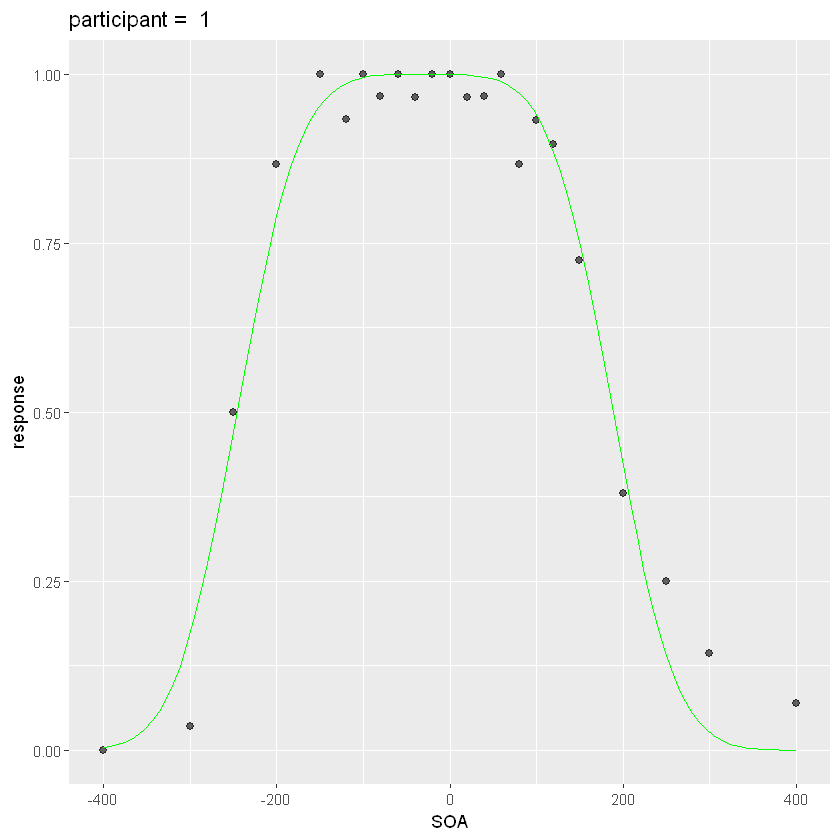

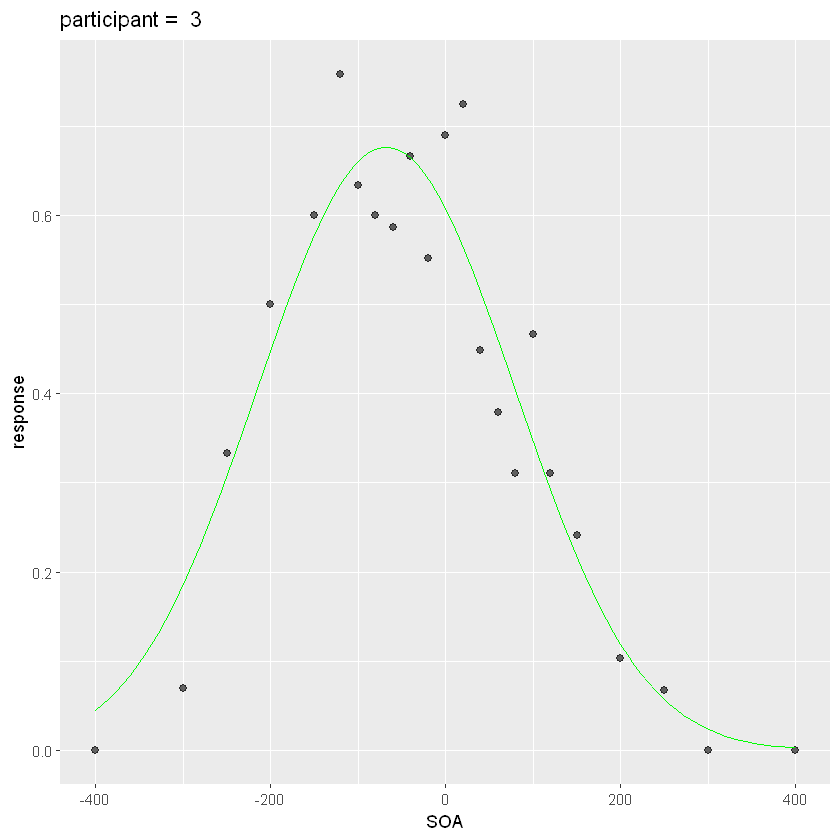

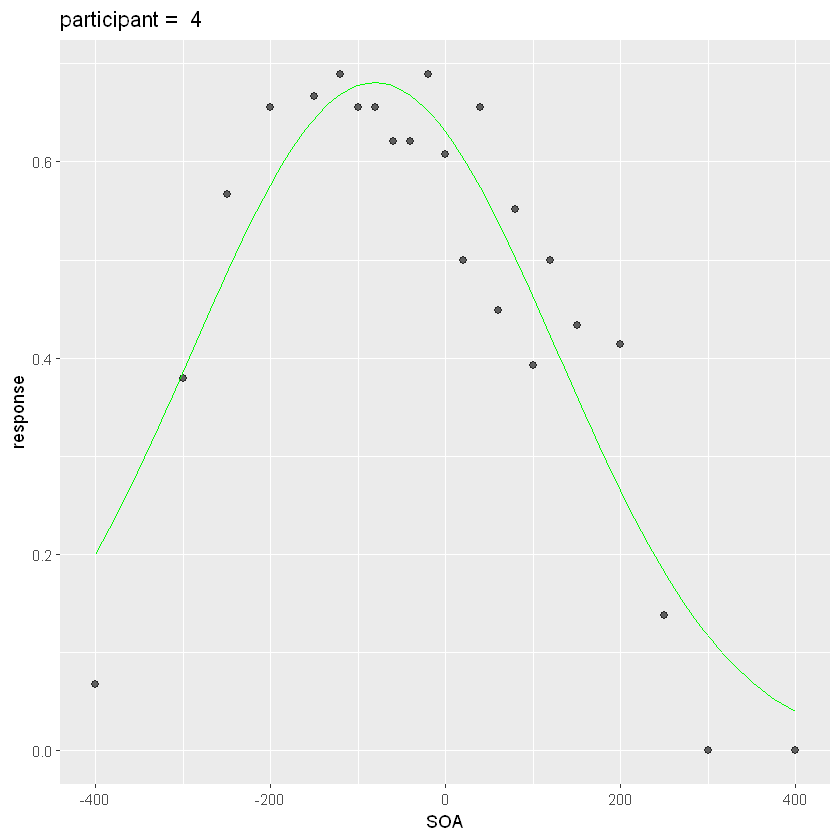

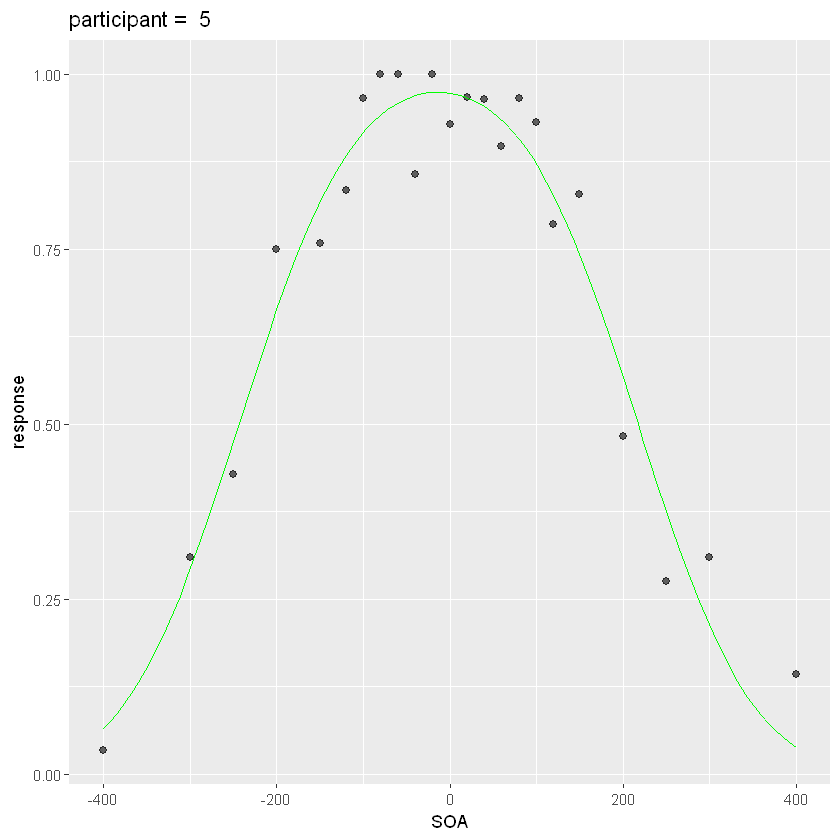

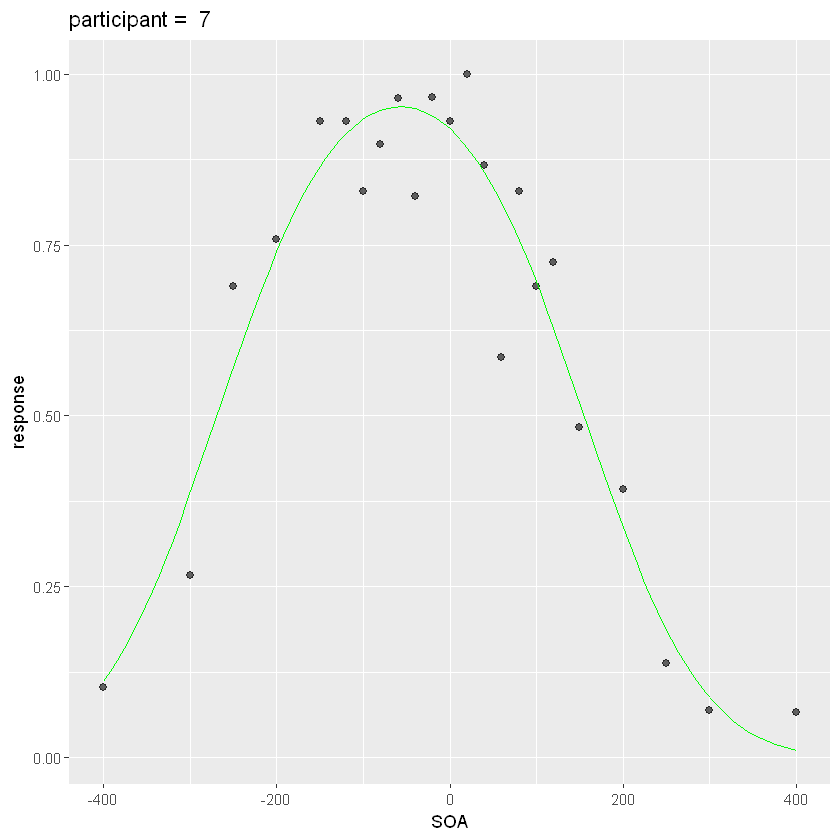

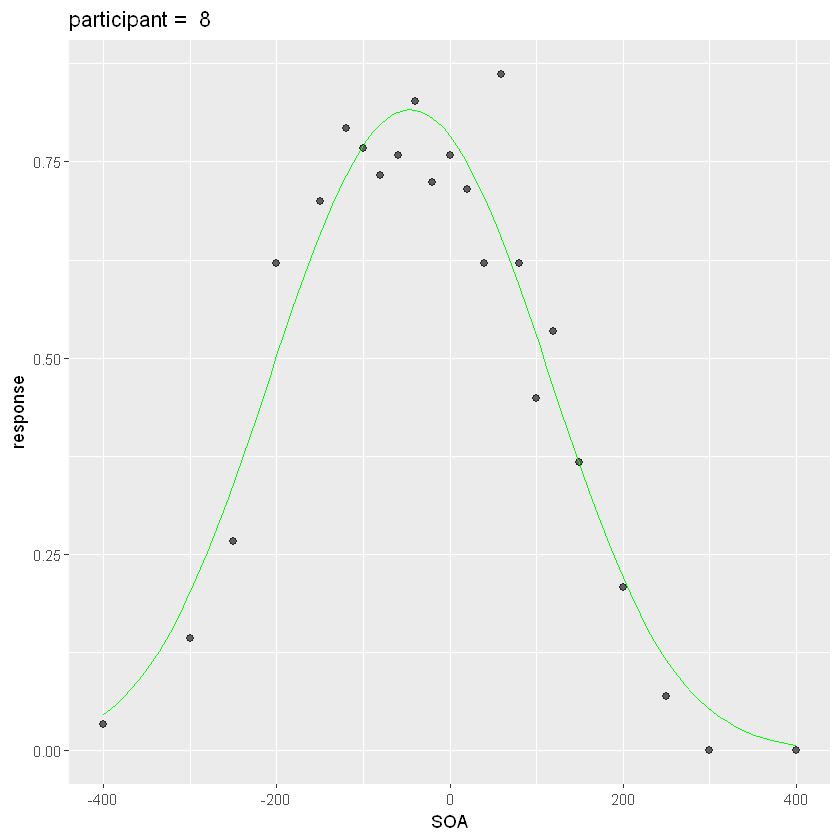

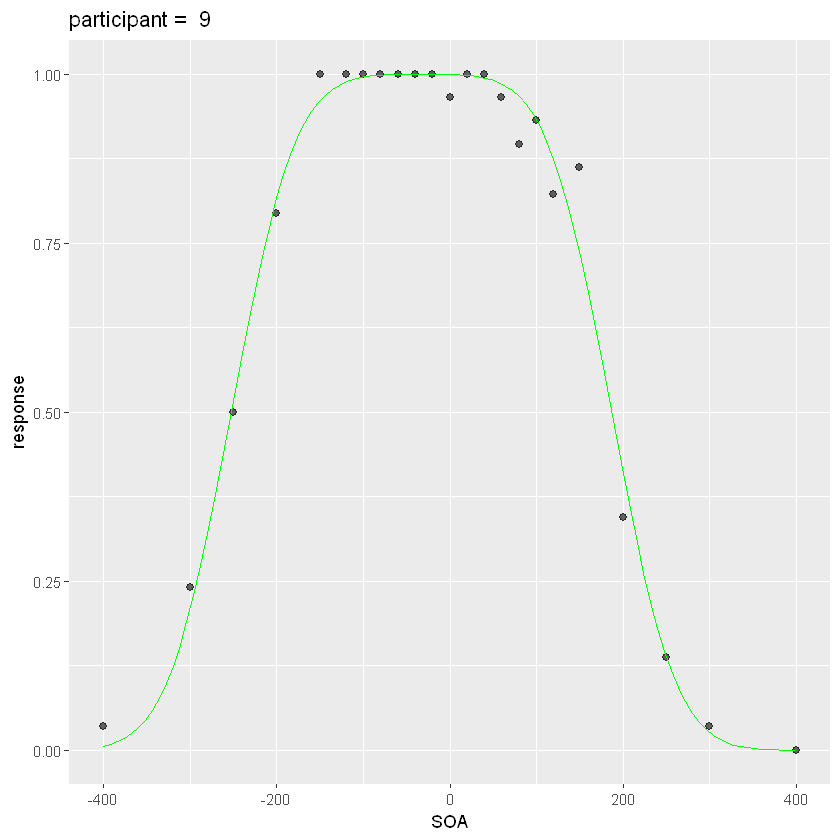

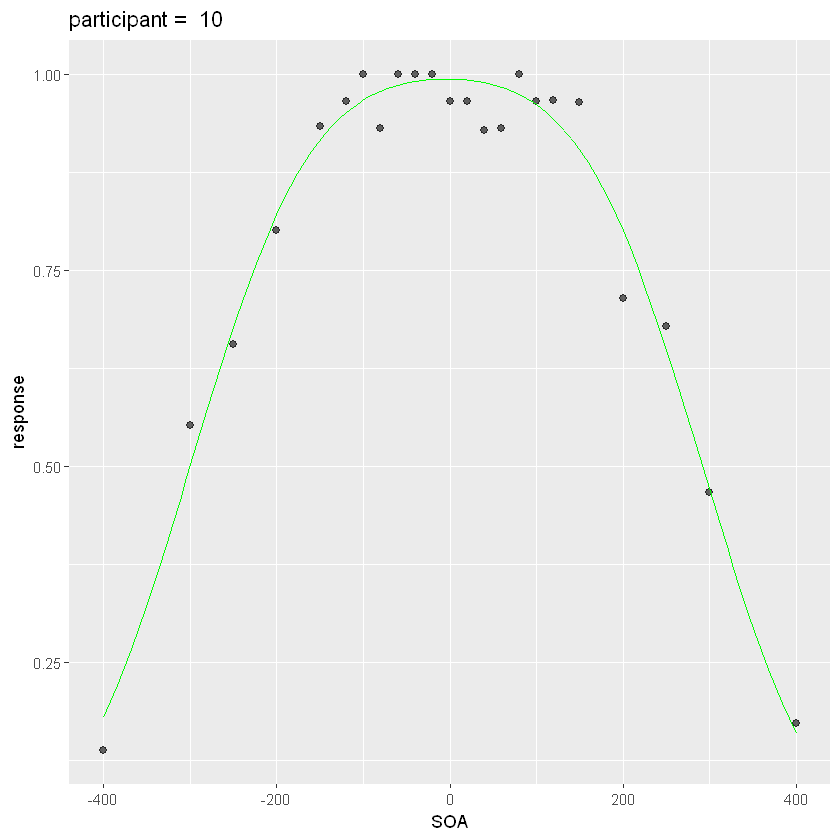

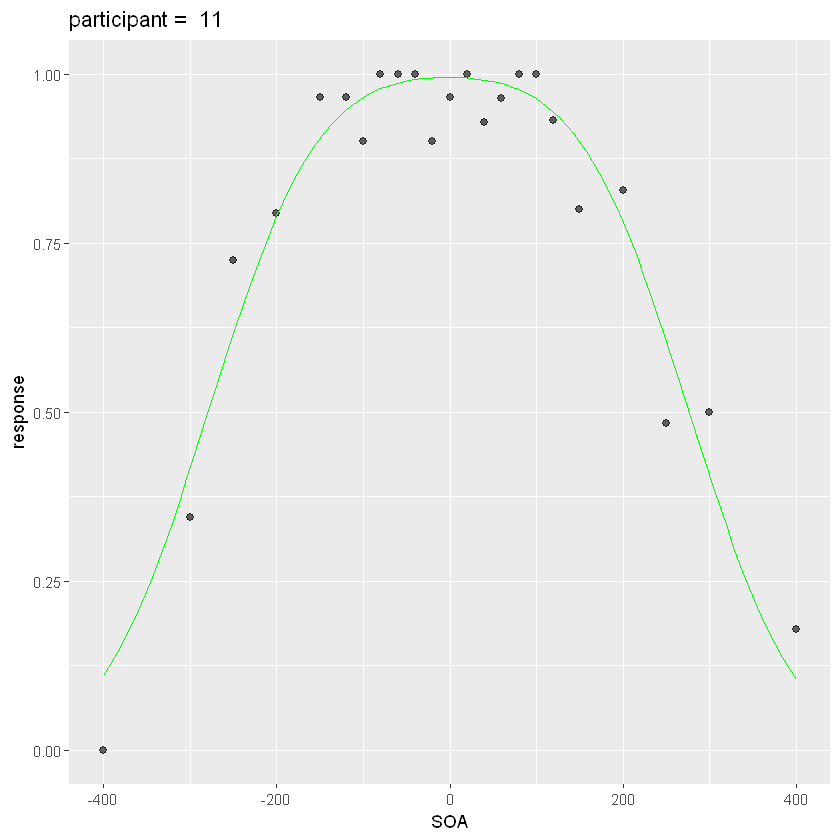

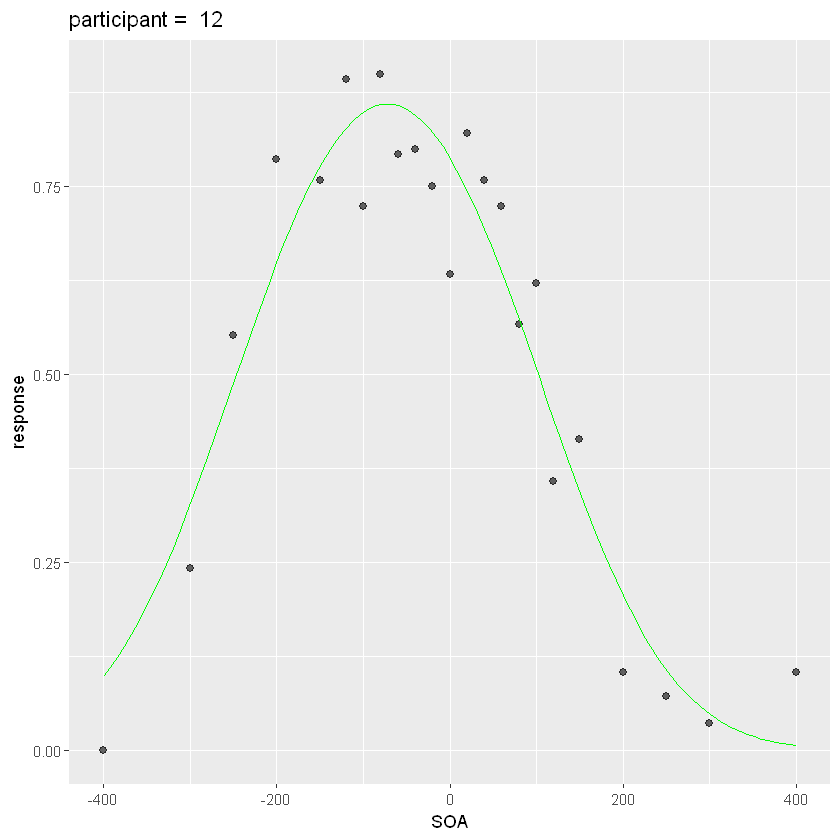

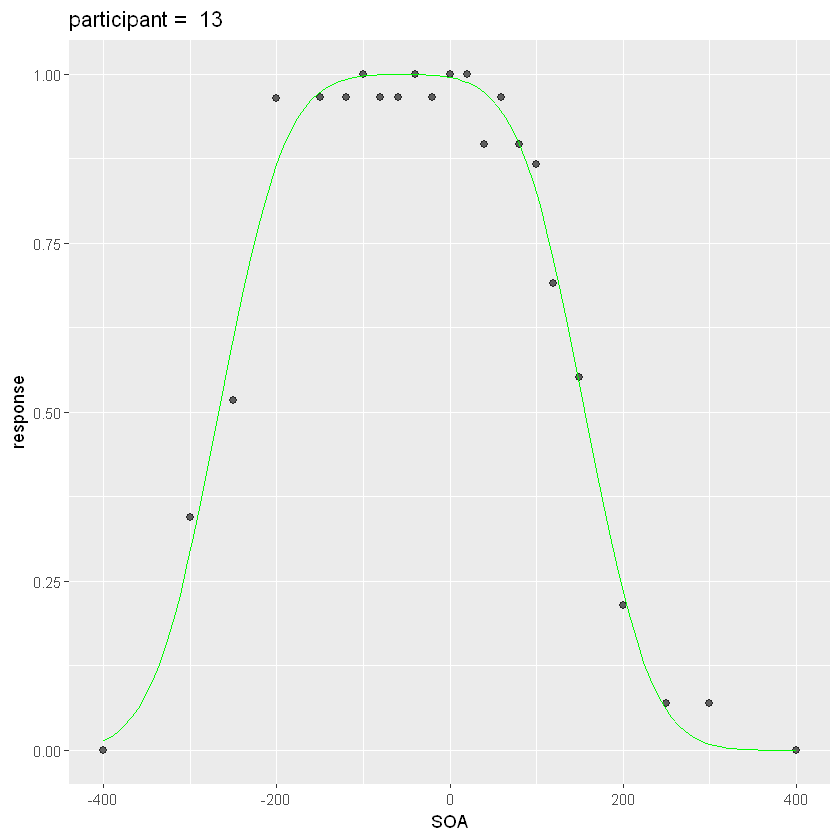

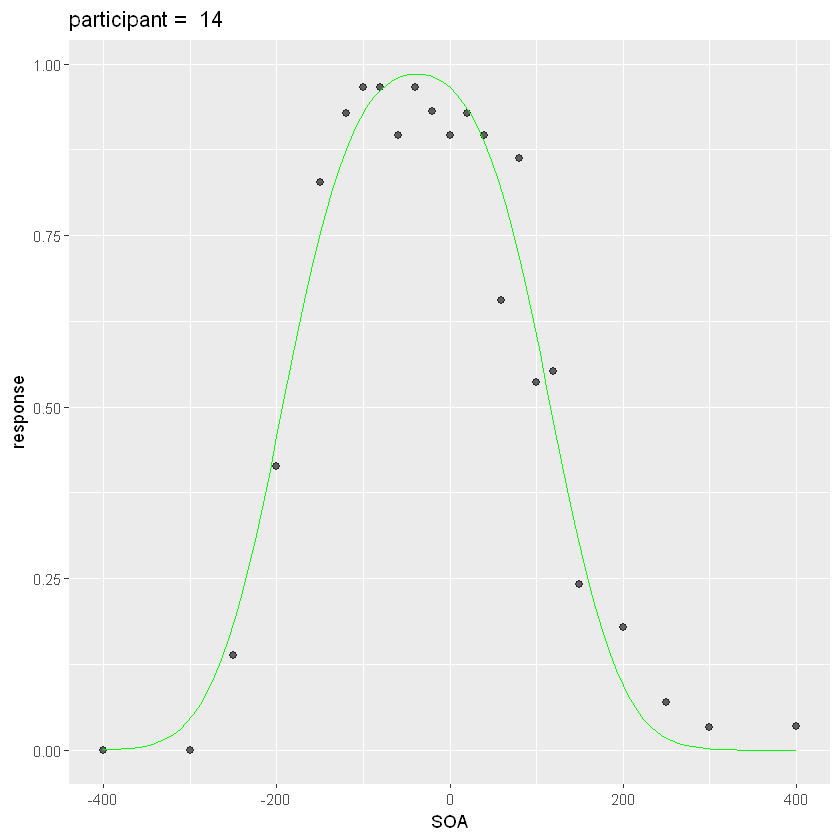

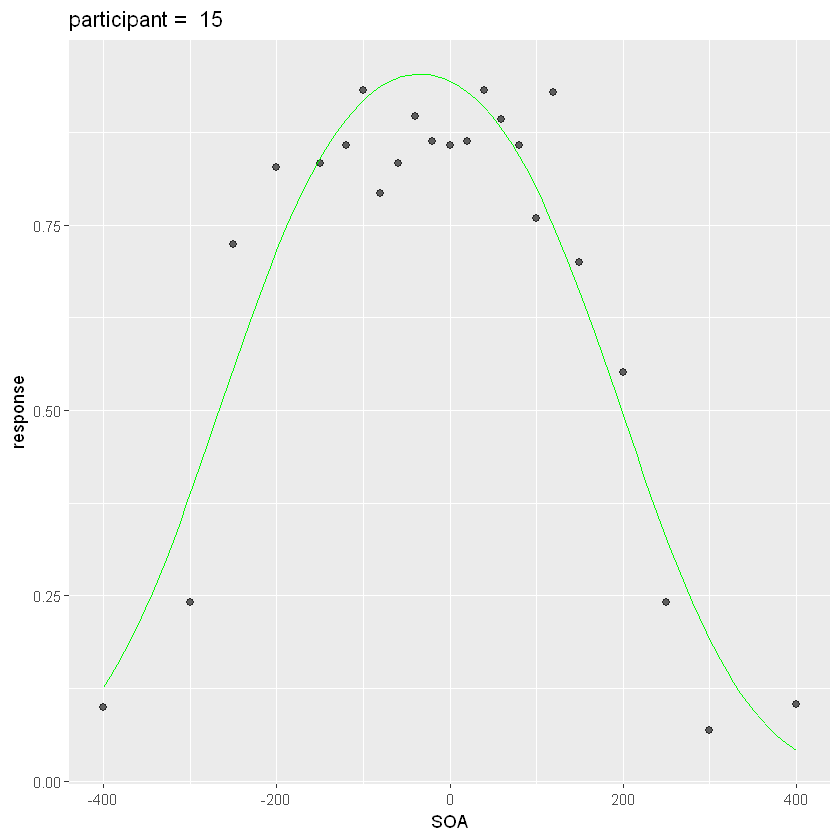

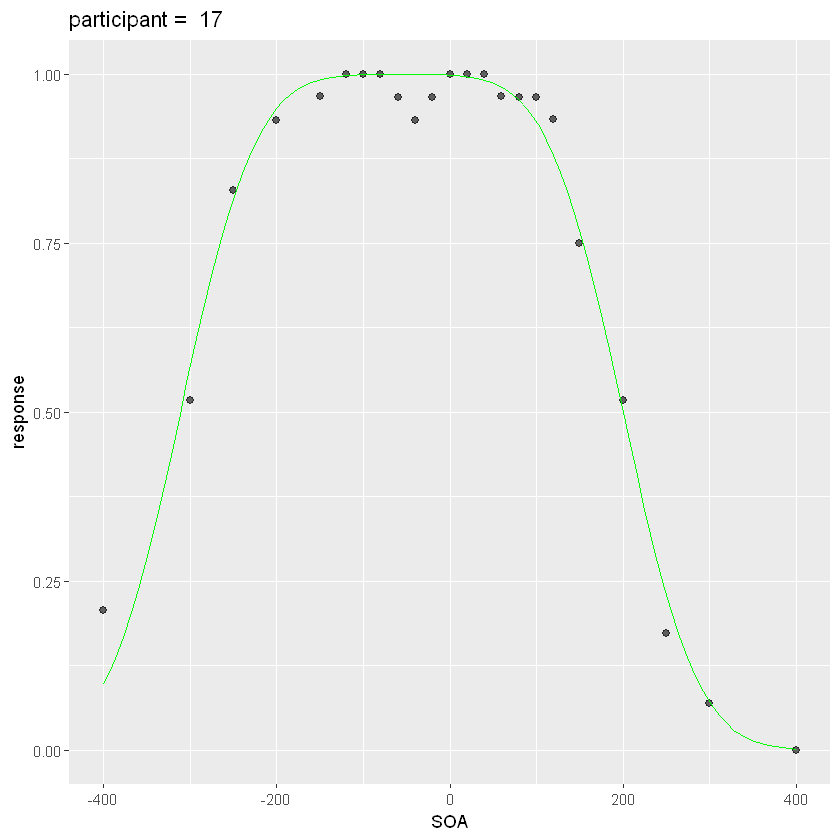

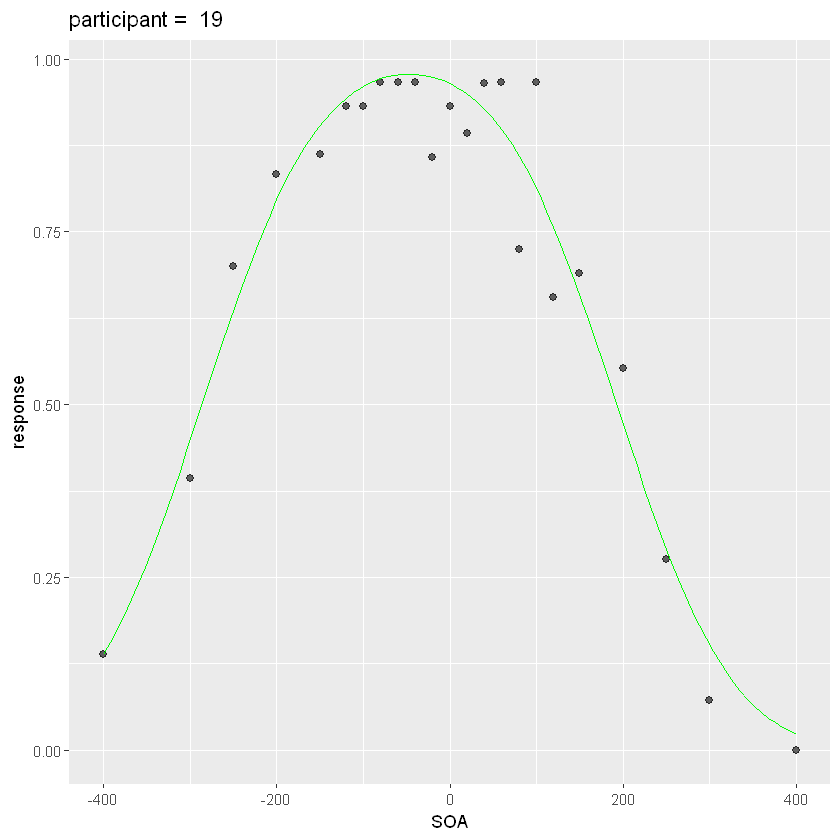

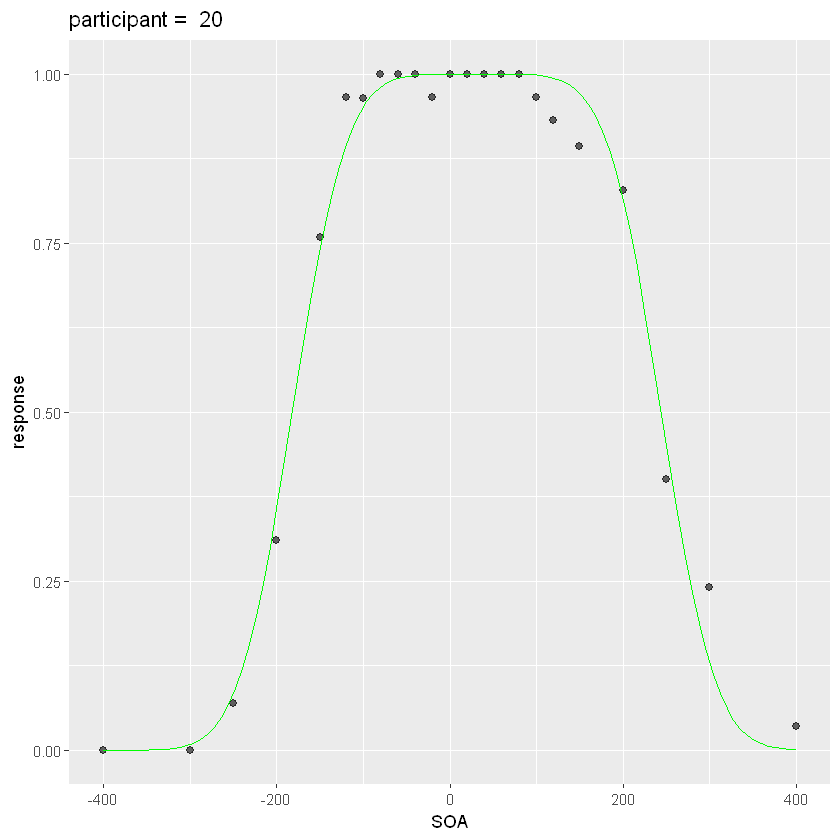

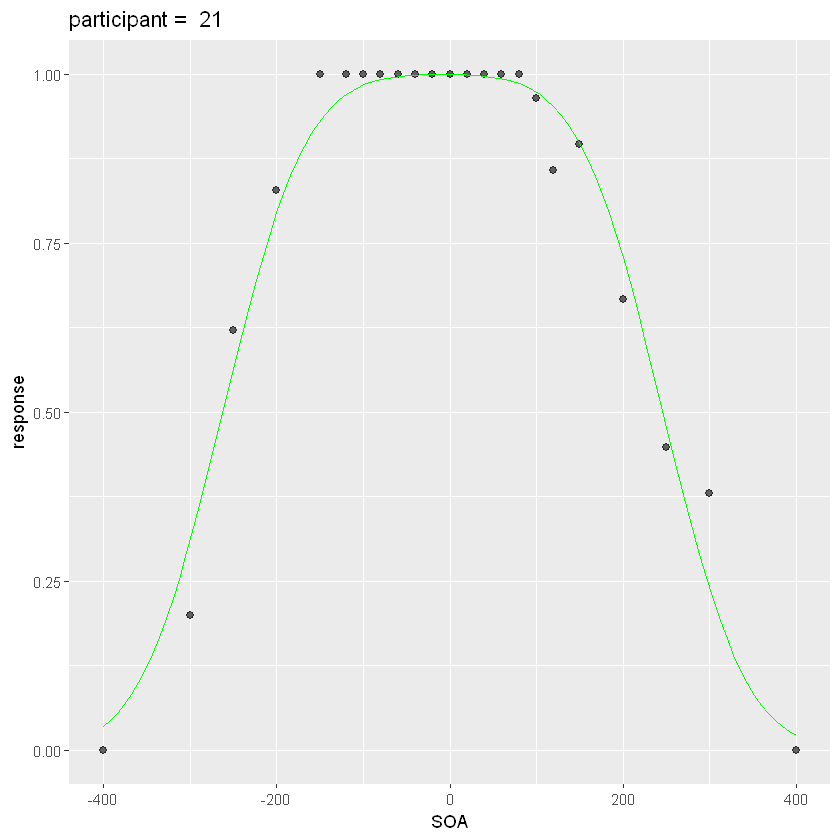

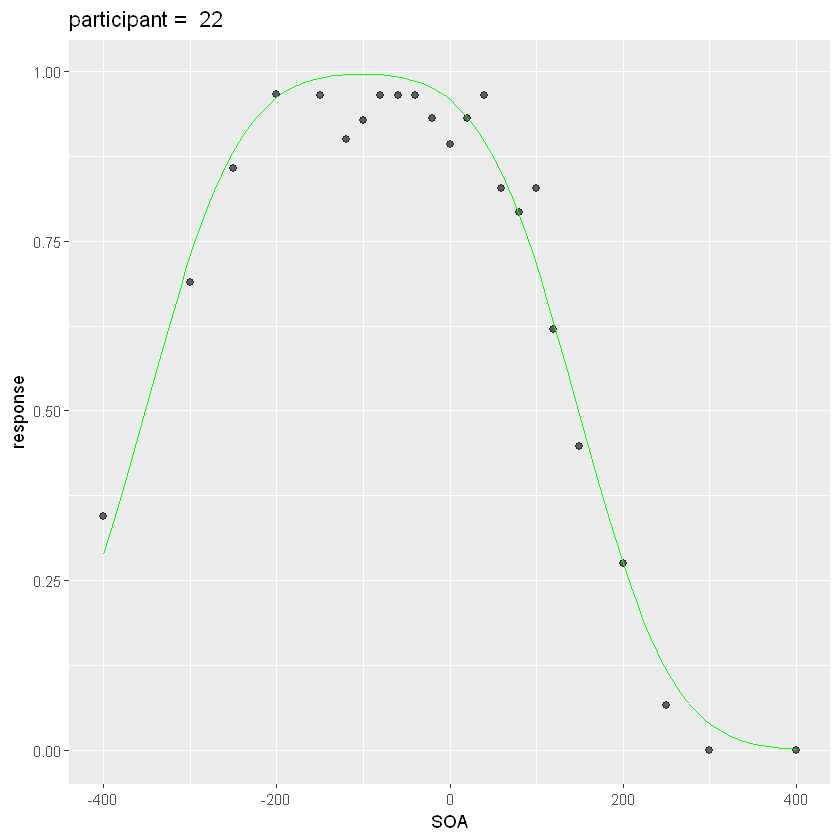

In [10]:
ff <- function(x,Clow,Chigh,sigma){
      pnorm(x, mean = Clow, sd = sigma) -
    pnorm(x, mean = Chigh, sd = sigma)
}

data_mean <- df %>% group_by(participant, SOA) %>%   
    summarise(
                response = mean(response == 1),
                n_trials = n(),
                .groups = "drop"
              )

for(subj in unique(df$participant)){

    d1 <- data_mean %>% filter(participant == subj)
    Clow <- (model_results %>% filter(participant == subj))$Clow
    Chigh <- (model_results %>% filter(participant == subj))$Chigh
    sigma <- (model_results %>% filter(participant == subj))$sigma
    print(ggplot(d1, aes(x = SOA, y = response)) +
            geom_point(size = 2, alpha = 0.6) +
            geom_function(fun=ff, args = list(Clow = Clow, Chigh = Chigh, sigma = sigma), color='green') +
            labs(title = paste('participant = ',subj)))
            
}

In [11]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){
  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)
  return(1 - SS_res / SS_tot)
}

model_results$R2 <- NA

for(i in 1:nrow(model_results)){
  id <- model_results$participant[i]
  subdata <- data_mean %>% filter(participant == id)
  pred <- ff(subdata$SOA, model_results$Clow[i], model_results$Chigh[i], model_results$sigma[i])
  model_results$R2[i] <- R2(subdata$response, pred)
}

head(model_results)

,participant,Clow,Chigh,sigma,PSS,R2
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-246.1273,188.53599,57.15752,-28.79564,0.9737873
2,3,-189.9685,54.52676,123.80209,-67.72085,0.9126244
3,4,-254.6838,92.91935,174.46400,-80.88224,0.8863433
4,5,-243.7031,217.30374,103.52649,-13.19966,0.9553740
5,7,-269.4322,154.93041,107.24385,-57.25092,0.9329455
6,8,-202.0173,109.56783,117.14745,-46.22473,0.9423526


In [12]:
model_results %>% arrange(R2)

participant,Clow,Chigh,sigma,PSS,R2
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4,-254.6838,92.91935,174.46400,-80.882235,0.8863433
15,-266.6964,198.15160,116.67218,-34.272378,0.9048837
3,-189.9685,54.52676,123.80209,-67.720853,0.9126244
12,-247.1337,102.65995,118.52120,-72.236892,0.9209117
7,-269.4322,154.93041,107.24385,-57.250916,0.9329455
8,-202.0173,109.56783,117.14745,-46.224730,0.9423526
11,-279.3688,276.28069,98.60181,-1.544043,0.9476776
19,-286.4819,192.61597,104.38905,-46.932977,0.9533128
5,-243.7031,217.30374,103.52649,-13.199665,0.9553740


## 1-4 Save Results

In [9]:
write_xlsx(model_results,"files/SJ_general_observer_parameters.xlsx")

###############################################################\
###############################################################
# 2- Serial Dependence based on Prior Stimulus
**List of contents:**\
2-1 Load data\
2-2 Fit psychometric model\
2-3 Check fits\
2-4 Plot group-level fits\
2-5 Statistical test of sigma\
2-6 Statistical test of Criterion_Low\
2-7 Statistical test of Criterion_High\
2-8 Statistical test of PSS

###############################################################
## 2-1 Load data

In [13]:
###############################################################
# Load SJ serial dependence dataset (prepared previously)
###############################################################

df <- read_xlsx("files/SJ_prior_stimulus_data.xlsx")
head(df)

participant,pre_stim,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,auditory_leading,-400,asynchrony,1.4373420
1,auditory_leading,-400,asynchrony,1.1699982
1,auditory_leading,-400,asynchrony,1.2704500
1,auditory_leading,-400,asynchrony,1.0868608
1,auditory_leading,-400,asynchrony,0.9859973
1,auditory_leading,-400,asynchrony,0.9527494


In [14]:
###############################################################
# Prepare behavioral variables
###############################################################

colnames(df)[4] <- "response"
colnames(df)[2] <- "prior_stimulus"

data <- df %>%
  mutate(
    response = ifelse(response == "synchrony", 1, 0)
  )
head(data)

participant,prior_stimulus,SOA,response,rt
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,auditory_leading,-400,0,1.4373420
1,auditory_leading,-400,0,1.1699982
1,auditory_leading,-400,0,1.2704500
1,auditory_leading,-400,0,1.0868608
1,auditory_leading,-400,0,0.9859973
1,auditory_leading,-400,0,0.9527494


###############################################################
## 2-2 Fit psychometric model

In [15]:
# Model:
# P(synchronous)=Φ(SOA;Clow,σ)−Φ(SOA;Chigh,σ)

model <- function(data){
  loss_function <- function(params){
    Clow <- params[1]
    Chigh <- params[2]
    sigma <- params[3]
    predicted <-  pnorm(data$SOA, mean = Clow, sd = sigma) - pnorm(data$SOA, mean = Chigh, sd = sigma)
    sum((predicted - data$response)^2)
  }

  DEoptim(
    loss_function,
    lower = c(-500, -600, .0001),
    upper = c(500, 600, 1000)
  )
}

model_results <- data.frame()

for(subj in unique(data$participant)){

    d1 <- data %>% filter(participant == subj)
    for(ps in unique(data$prior_stimulus)){
        d2 <- d1 %>% filter(prior_stimulus == ps)
        fit <- model(d2)$optim$bestmem

        model_results <- rbind(
            model_results,
            data.frame(
              participant = subj,
              prior_stimulus = ps,
              Clow = fit[1],
              Chigh = fit[2],
              sigma = fit[3]
    )
  )
}}

rownames(model_results) <- NULL

Iteration: 1 bestvalit: 27.098742 bestmemit: -263.939151  164.708192  122.991464
Iteration: 2 bestvalit: 27.098742 bestmemit: -263.939151  164.708192  122.991464
Iteration: 3 bestvalit: 25.057915 bestmemit: -232.561367  164.708192   98.330206
Iteration: 4 bestvalit: 25.057915 bestmemit: -232.561367  164.708192   98.330206
Iteration: 5 bestvalit: 23.603989 bestmemit: -254.742056  158.556198   65.118792
Iteration: 6 bestvalit: 23.603989 bestmemit: -254.742056  158.556198   65.118792
Iteration: 7 bestvalit: 23.603989 bestmemit: -254.742056  158.556198   65.118792
Iteration: 8 bestvalit: 23.603989 bestmemit: -254.742056  158.556198   65.118792
Iteration: 9 bestvalit: 23.603989 bestmemit: -254.742056  158.556198   65.118792
Iteration: 10 bestvalit: 23.603989 bestmemit: -254.742056  158.556198   65.118792
Iteration: 11 bestvalit: 23.603989 bestmemit: -254.742056  158.556198   65.118792
Iteration: 12 bestvalit: 23.603989 bestmemit: -254.742056  158.556198   65.118792
Iteration: 13 bestvalit: 

In [16]:
model_results <- model_results %>%
  mutate(
    PSS = (Clow + Chigh) / 2
  )

###############################################################
## 2-3 Check fits

In [17]:
nrow(model_results)

[1] 36

In [18]:
sort(model_results$Clow)

[1] -456.8248 -323.3225 -320.2736 -308.2325 -301.7211 -301.4230 -299.3514
 [8] -299.1190 -284.0067 -274.1438 -273.7600 -270.7546 -268.2810 -267.2083
[15] -264.5922 -263.4413 -262.6507 -261.2607 -261.1994 -259.1434 -256.0944
[22] -252.8220 -248.3944 -247.6636 -244.9381 -244.8072 -236.6964 -231.7215
[29] -231.5535 -196.7820 -196.1594 -194.1878 -190.6740 -187.6700 -177.9891
[36] -174.0171

In [19]:
sort(model_results$Chigh)

[1]  56.60296  62.97677  81.10409 103.77389 103.85298 109.12868 111.29195
 [8] 113.70073 129.30273 136.63522 138.76018 140.67730 142.11186 147.82106
[15] 163.82724 171.54914 172.88617 173.40322 173.75994 173.83564 197.57758
[22] 198.82019 199.69421 214.48074 215.87948 216.57906 228.78293 232.16057
[29] 232.38600 247.58557 253.13756 265.10813 268.55375 293.19076 312.48273
[36] 314.37580

In [20]:
sort(model_results$sigma)

[1]  40.35723  43.76092  47.38512  50.34732  54.28669  55.32193  56.94315
 [8]  58.84405  59.23483  59.88726  64.91825  71.48717  80.01336  81.45321
[15]  83.52532  88.79261  90.20504  91.22718  91.57126  91.67516  96.81870
[22]  97.00317 104.66857 105.21310 105.68000 107.54878 108.75934 111.13529
[29] 118.44297 120.24264 121.99712 124.87557 133.46239 138.17417 169.60502
[36] 178.19228

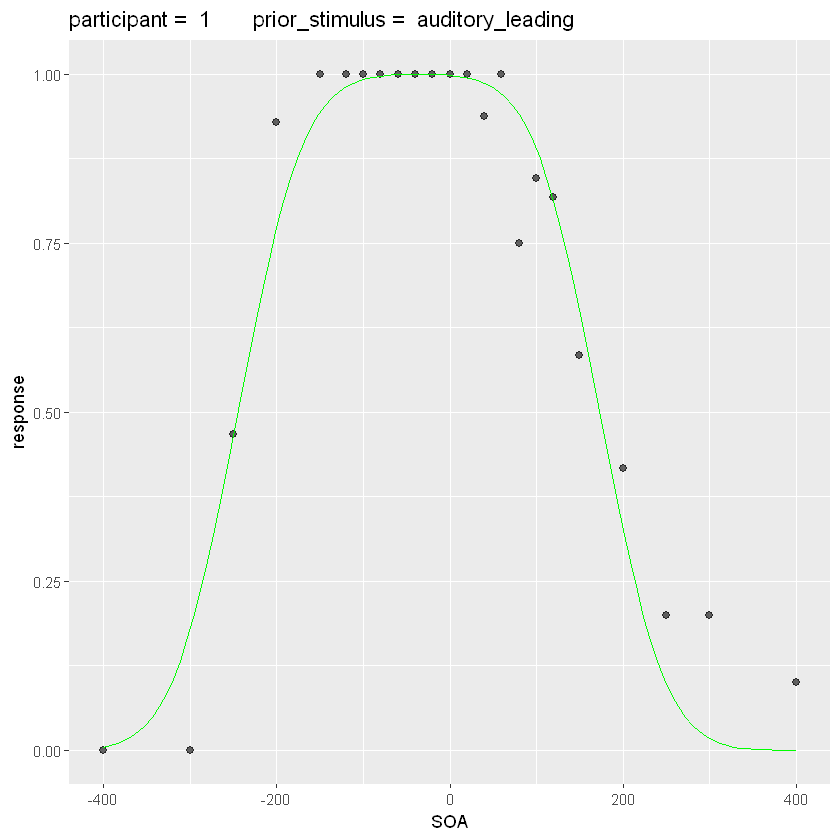

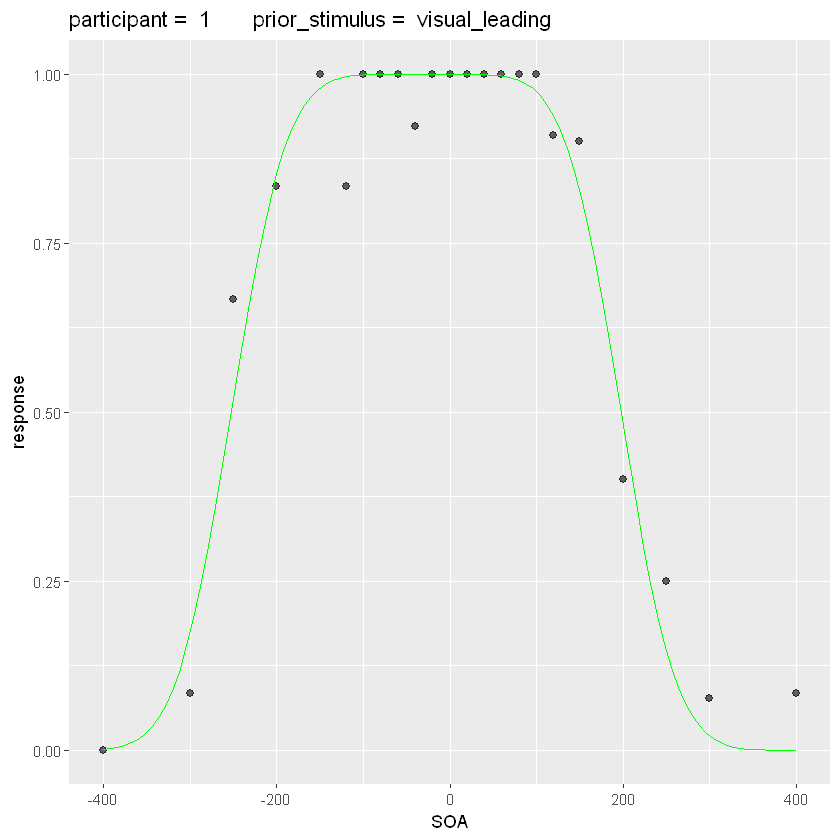

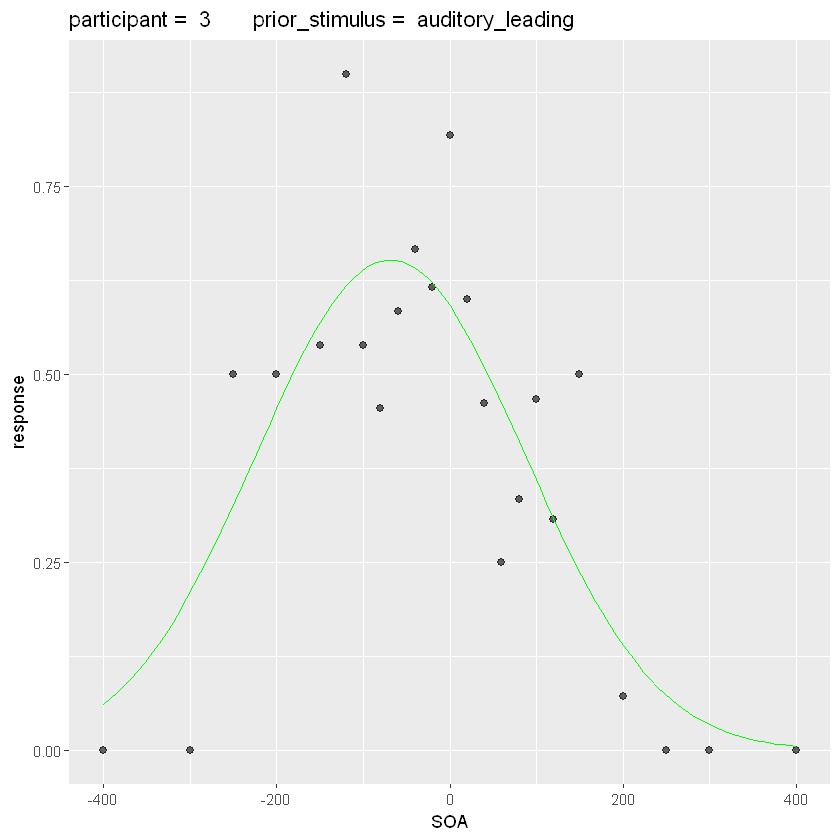

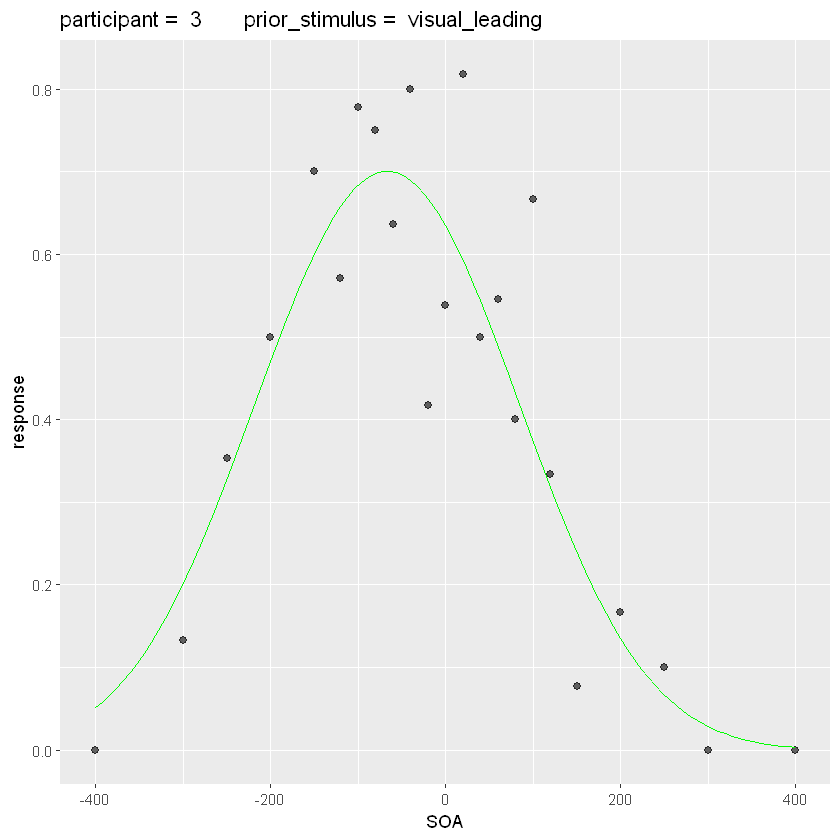

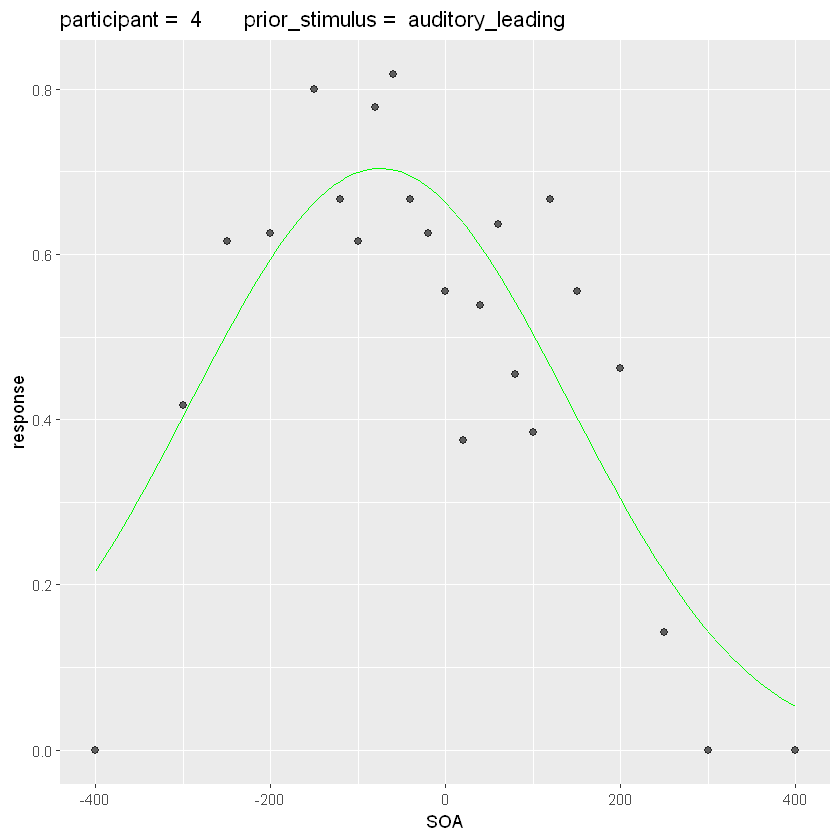

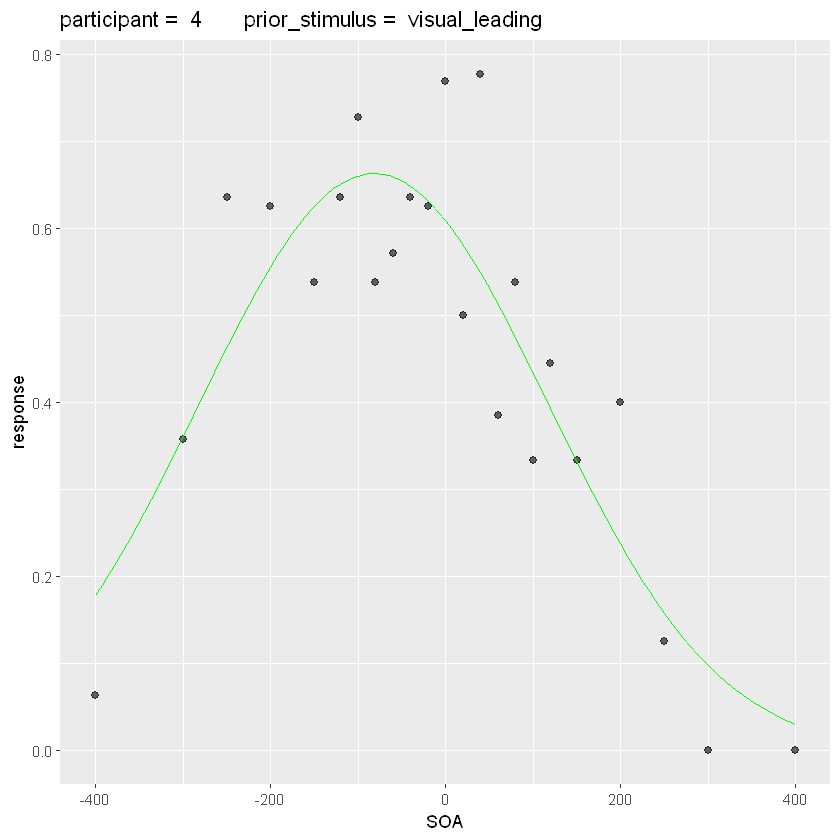

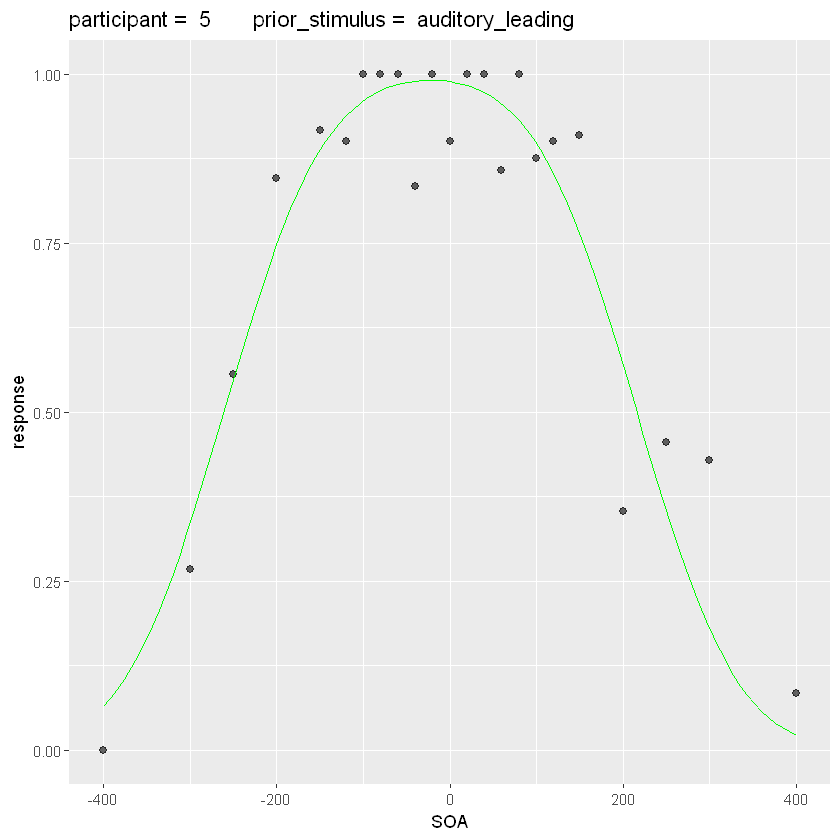

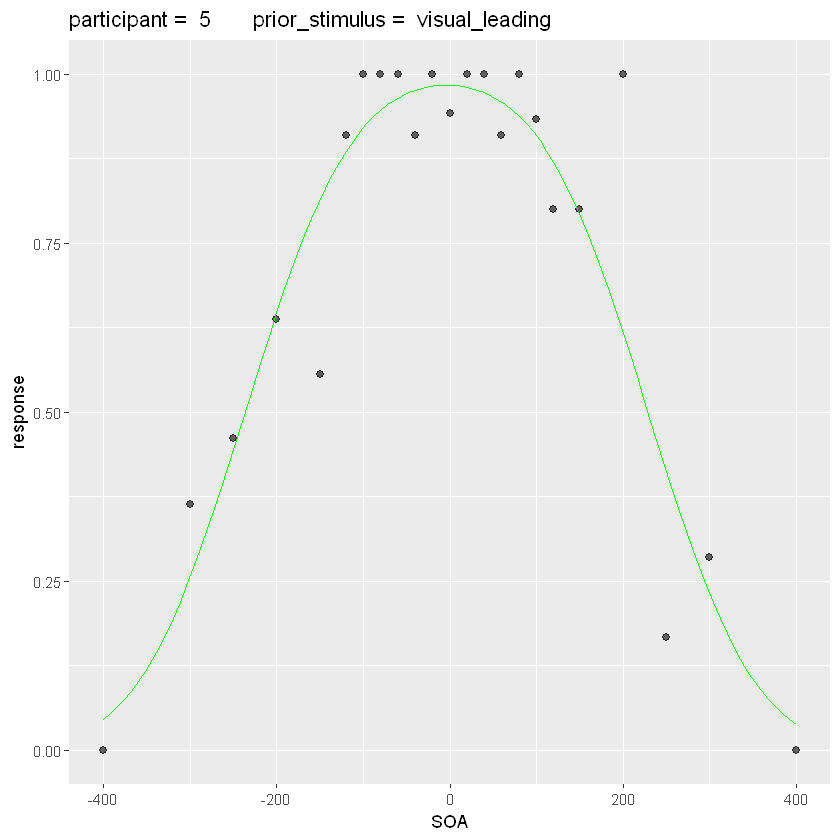

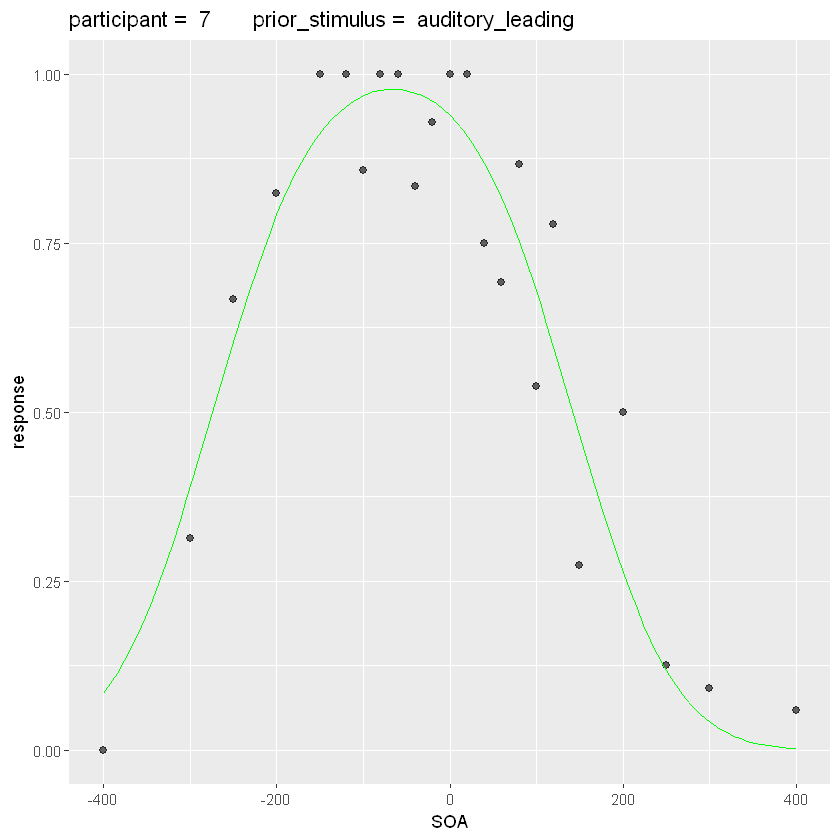

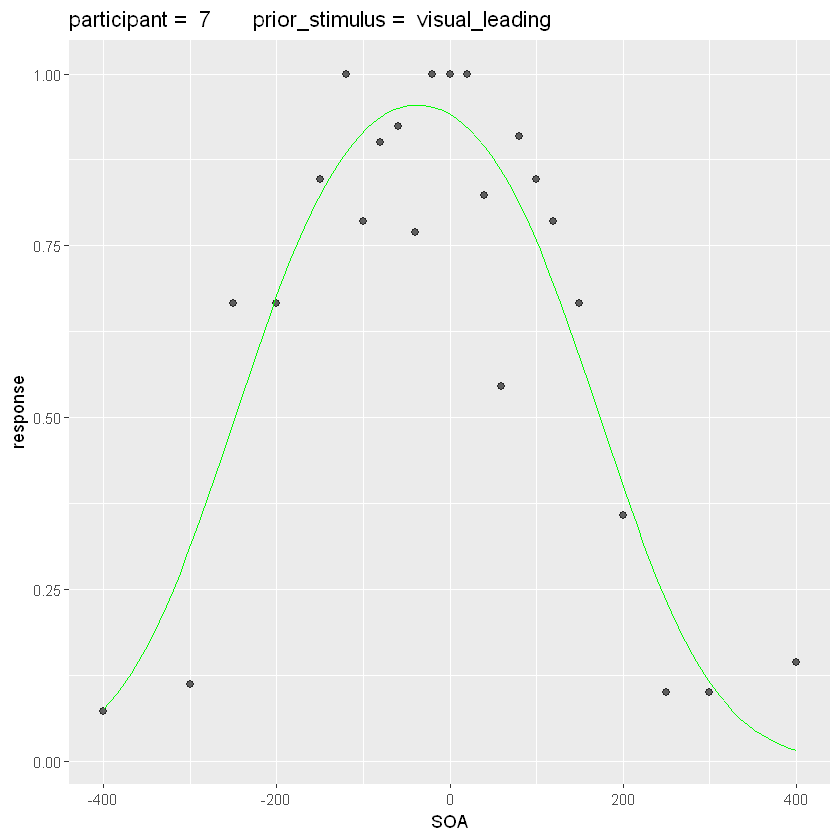

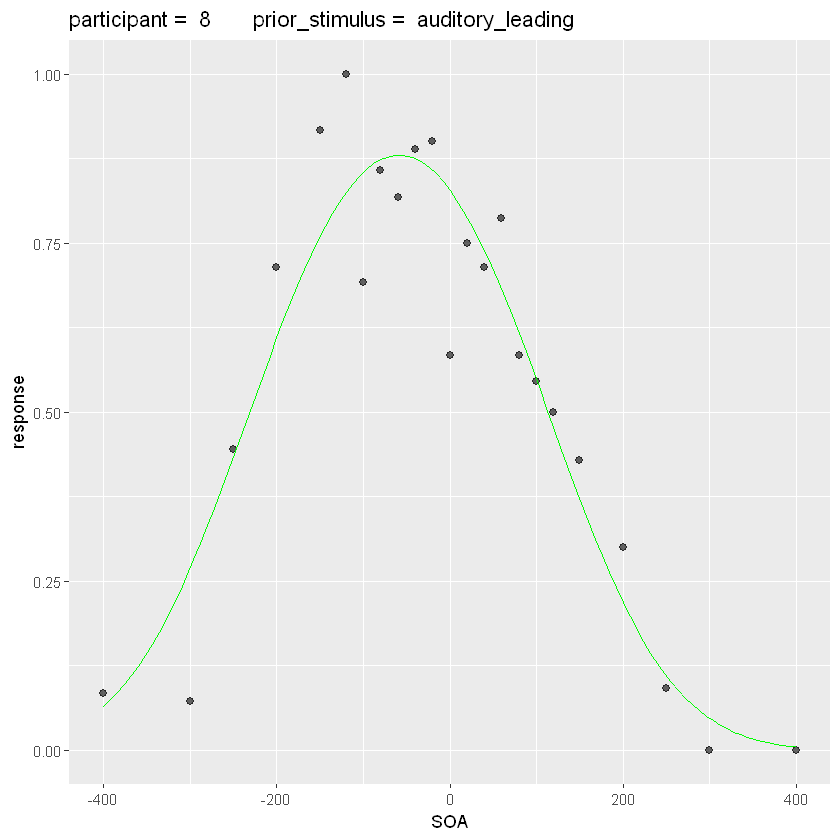

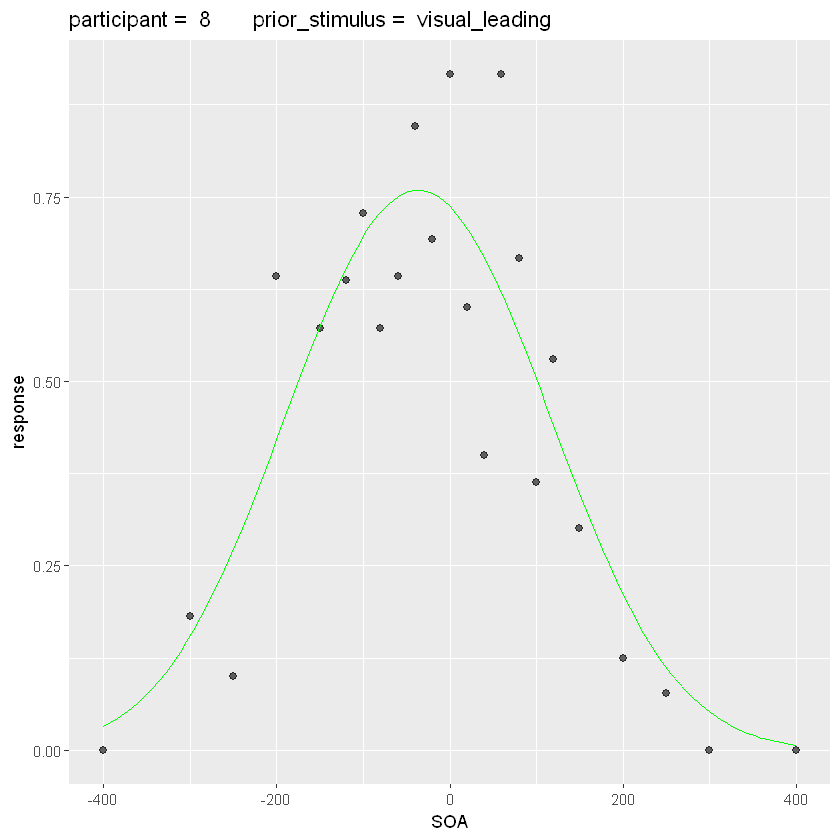

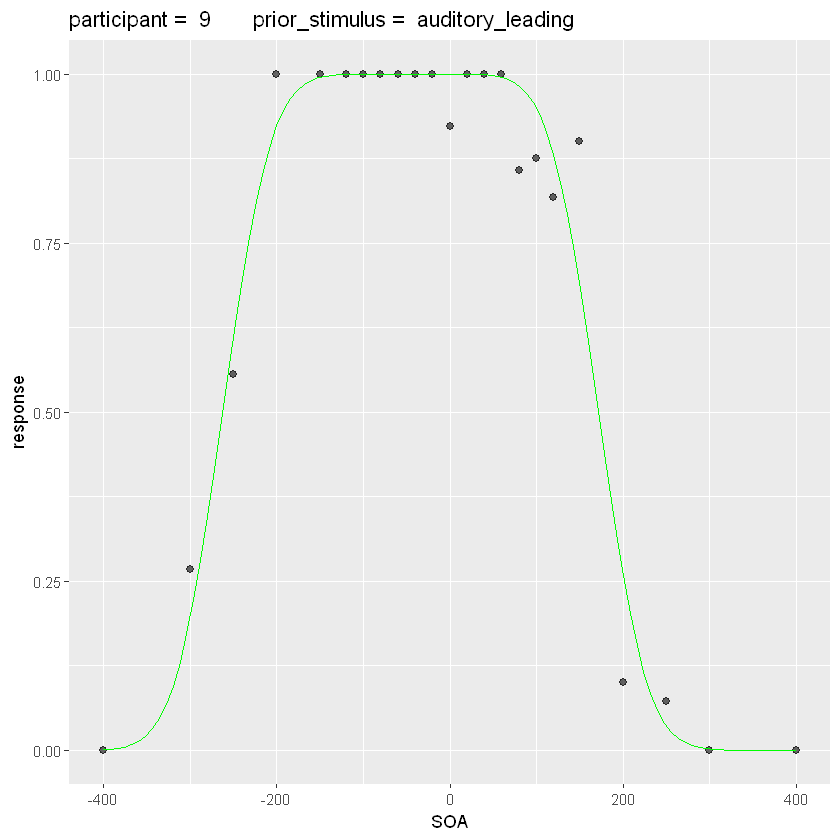

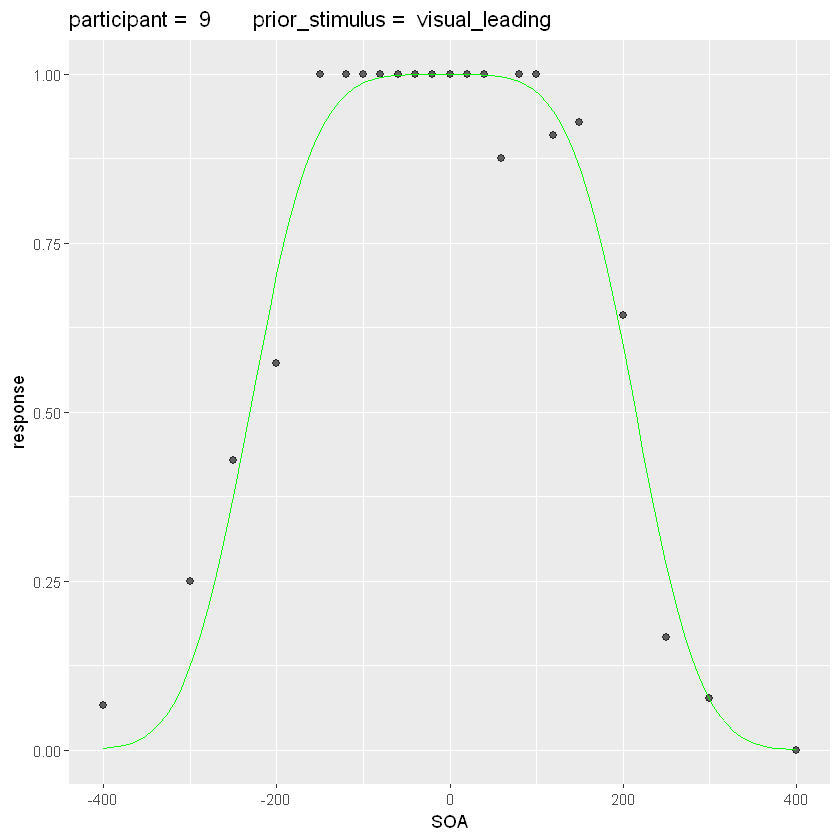

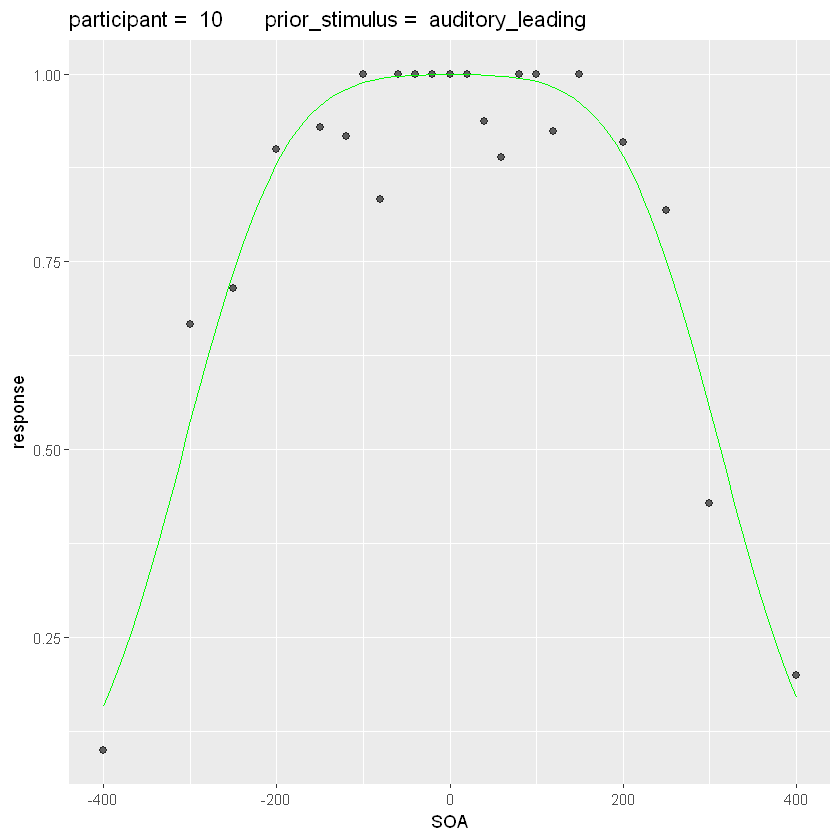

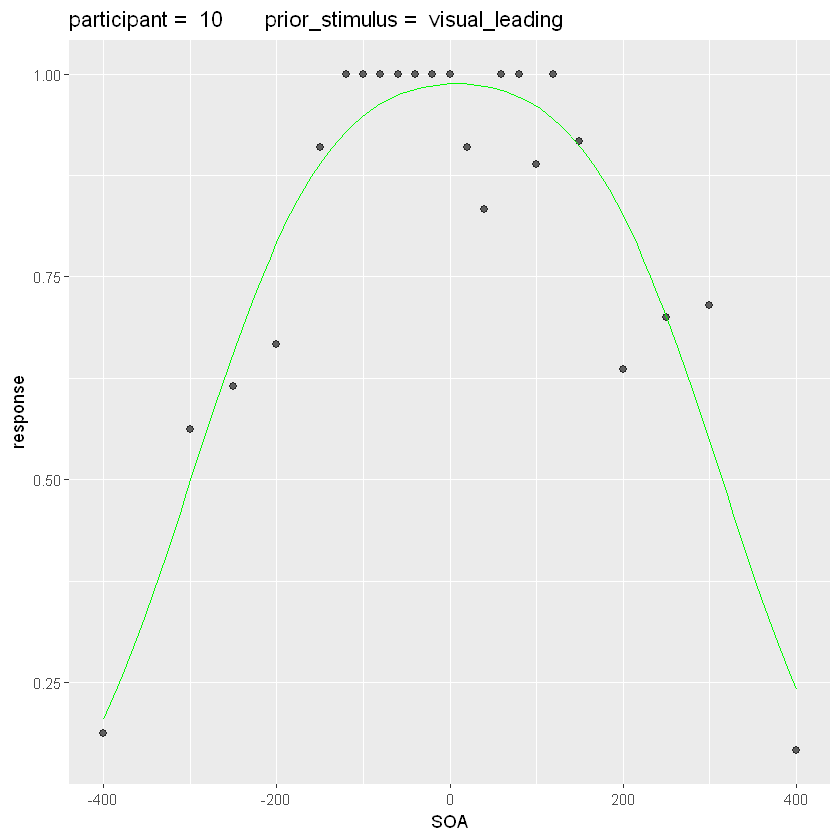

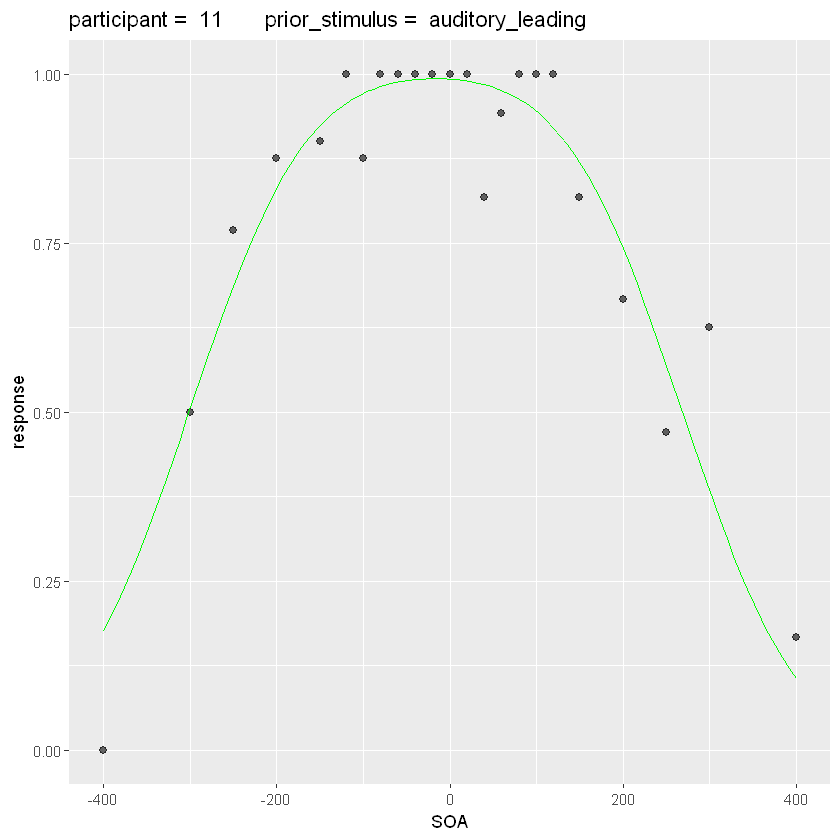

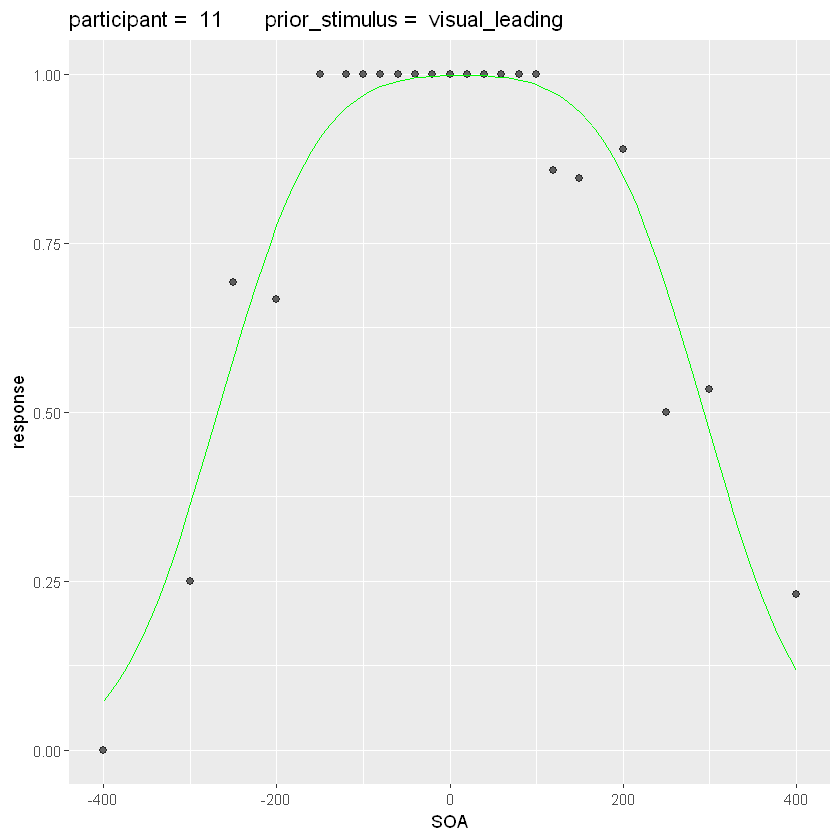

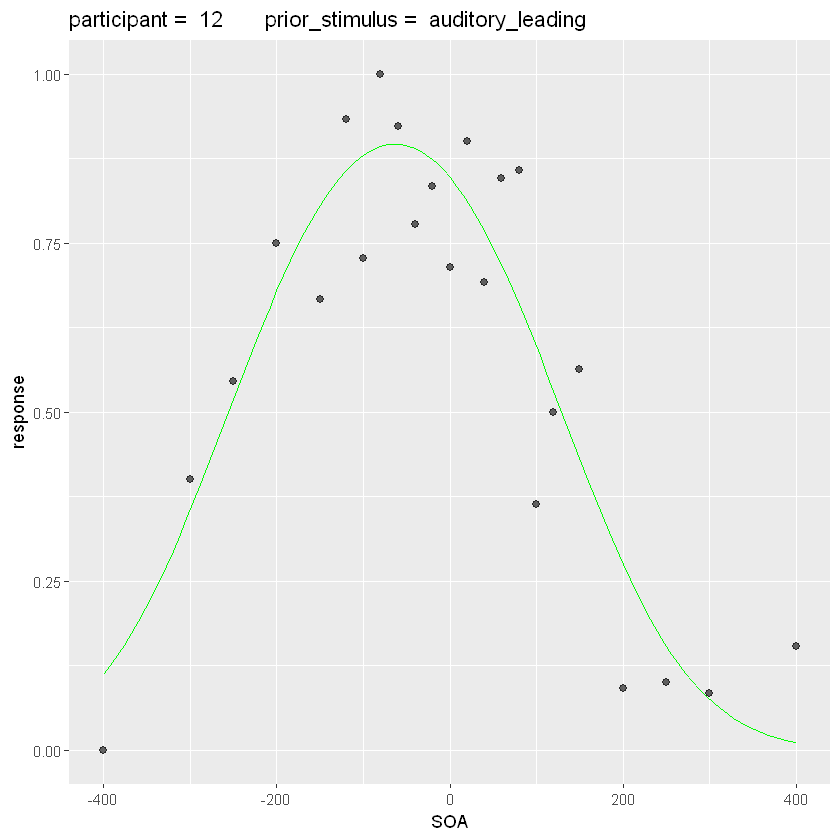

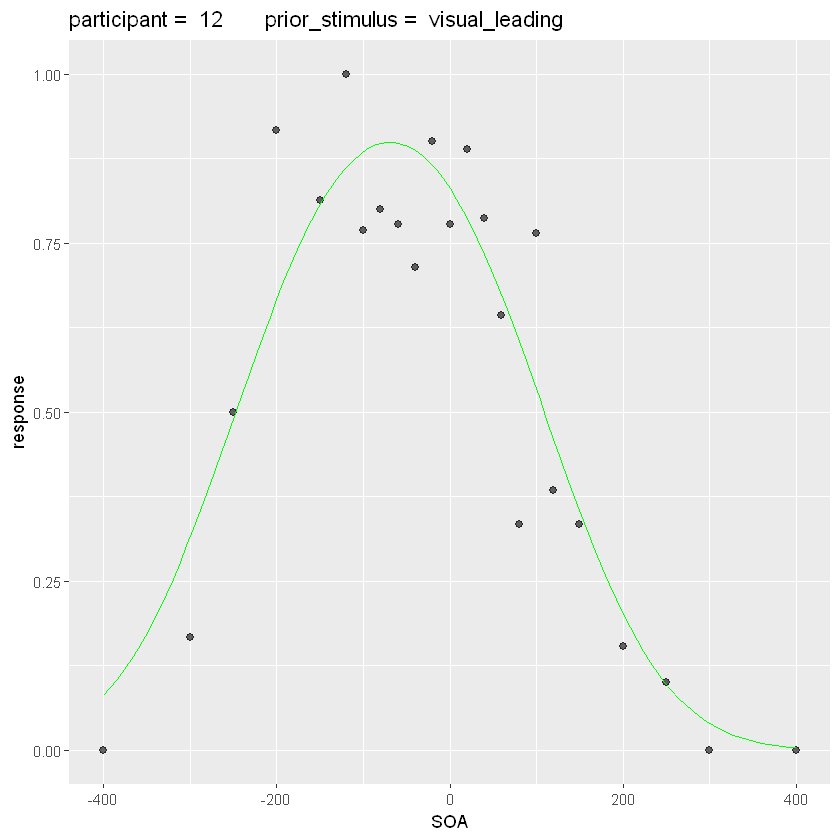

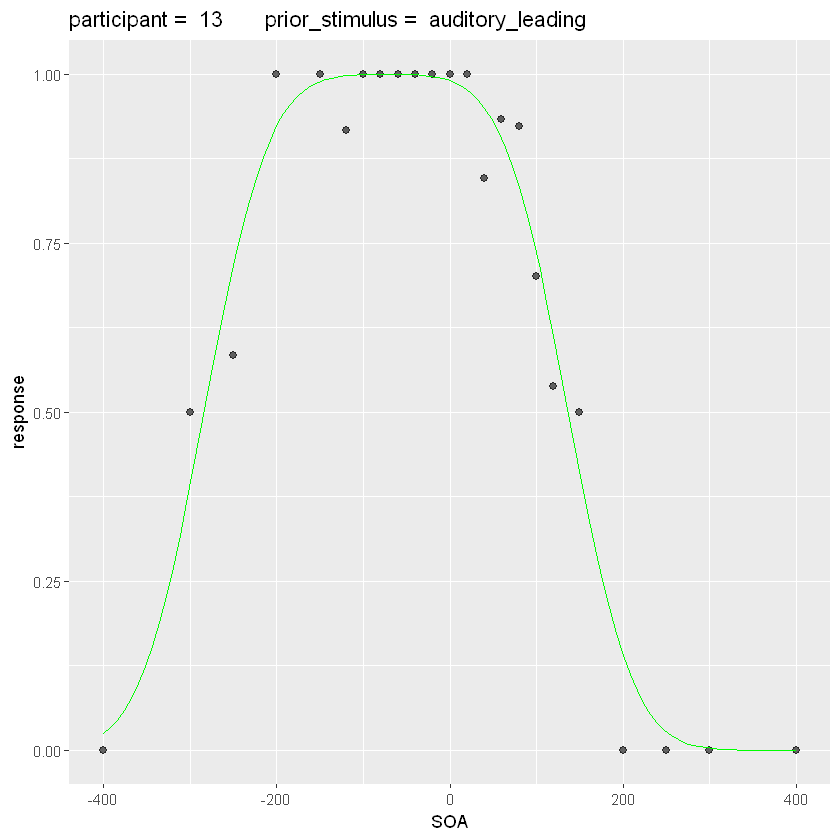

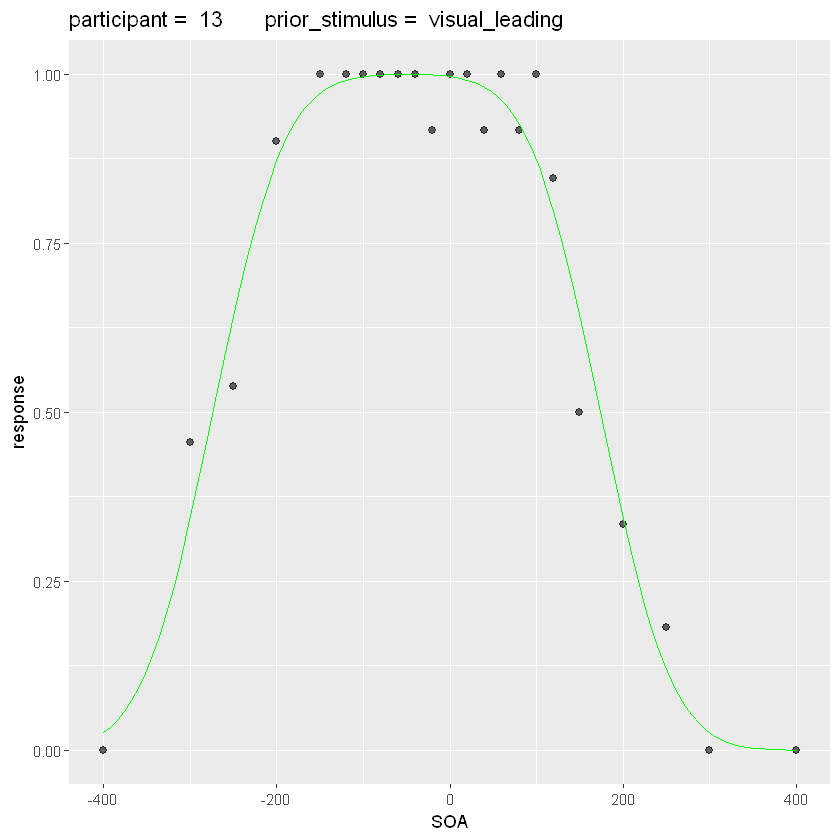

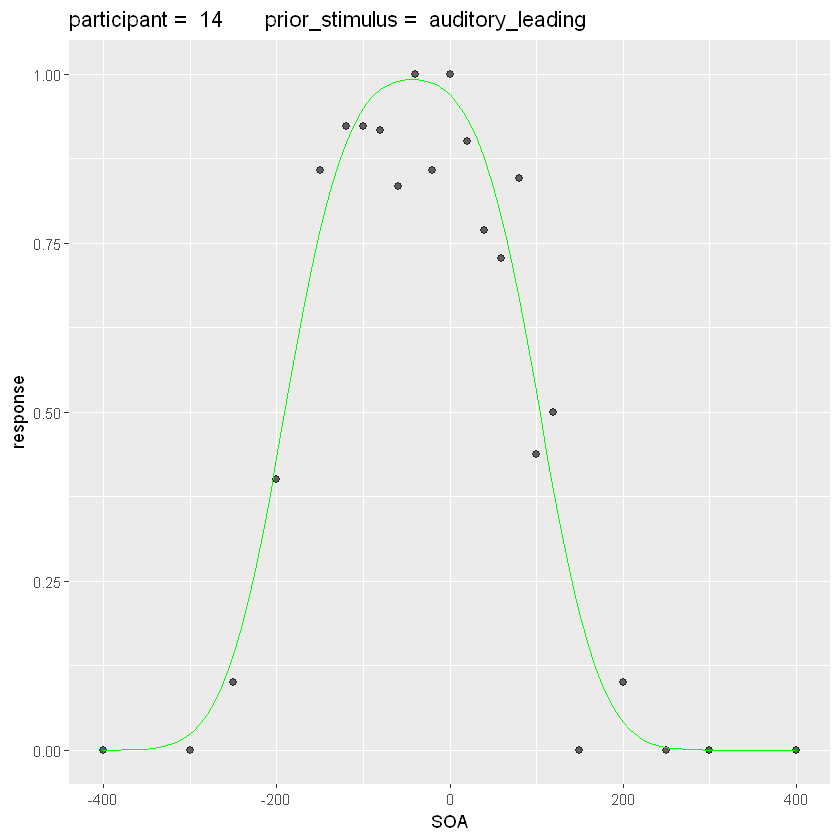

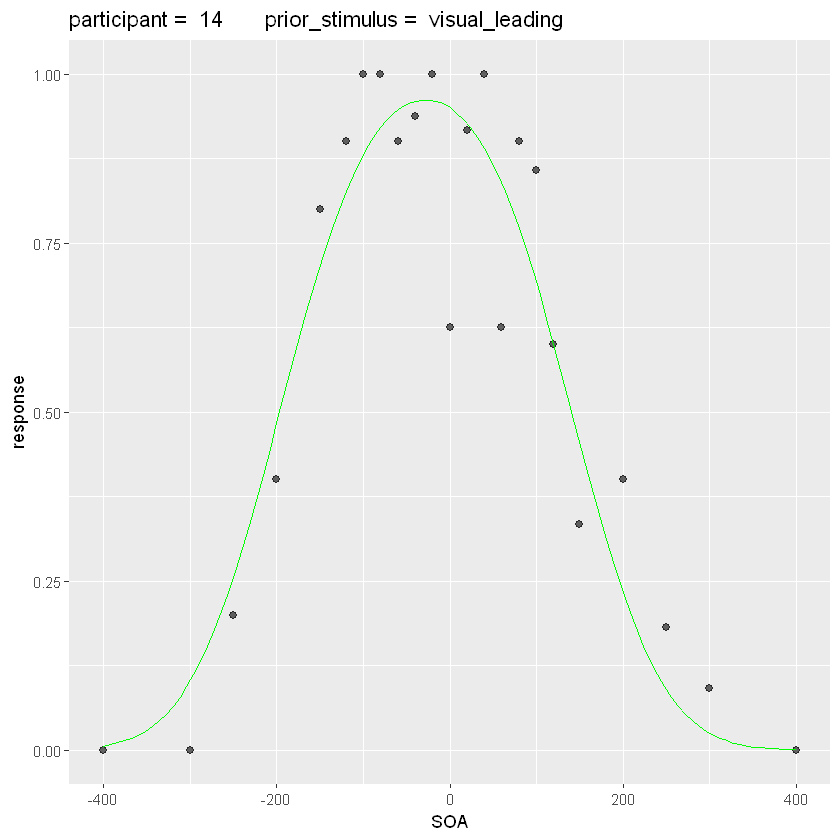

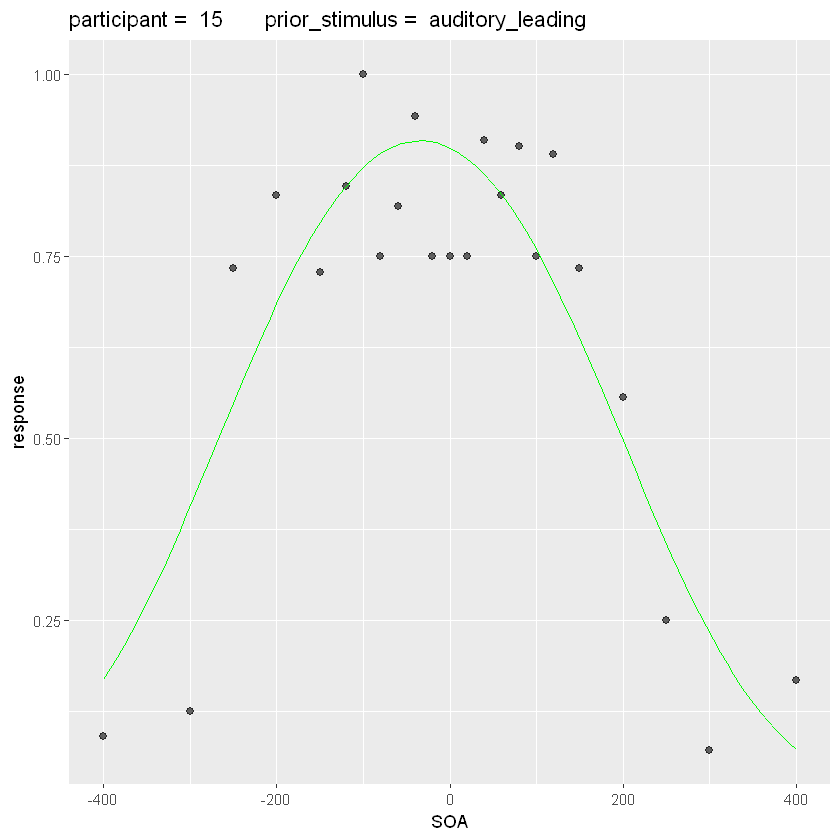

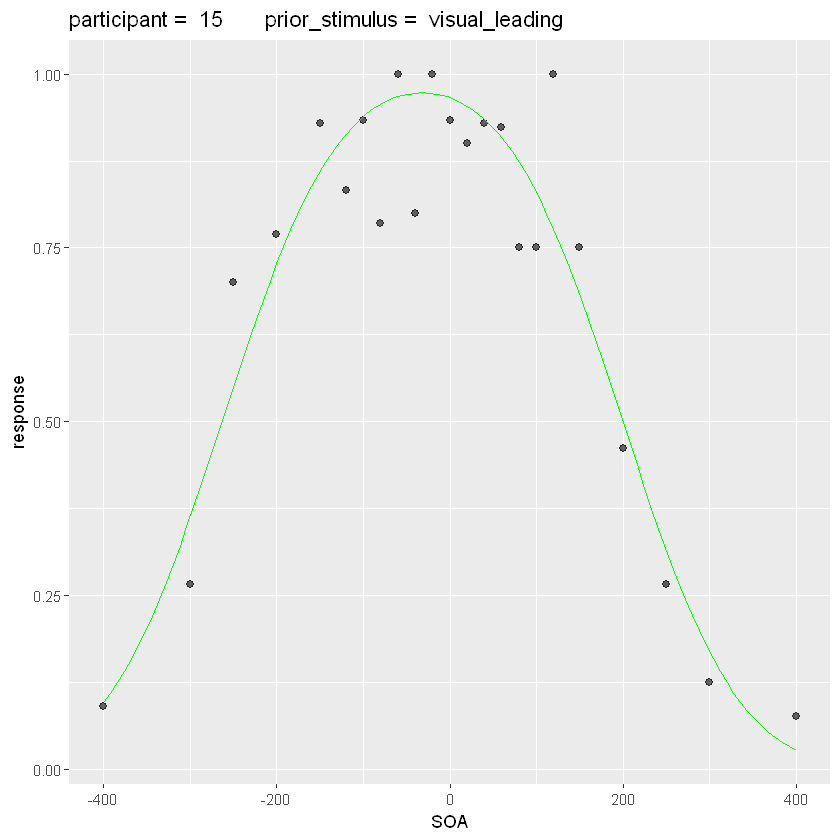

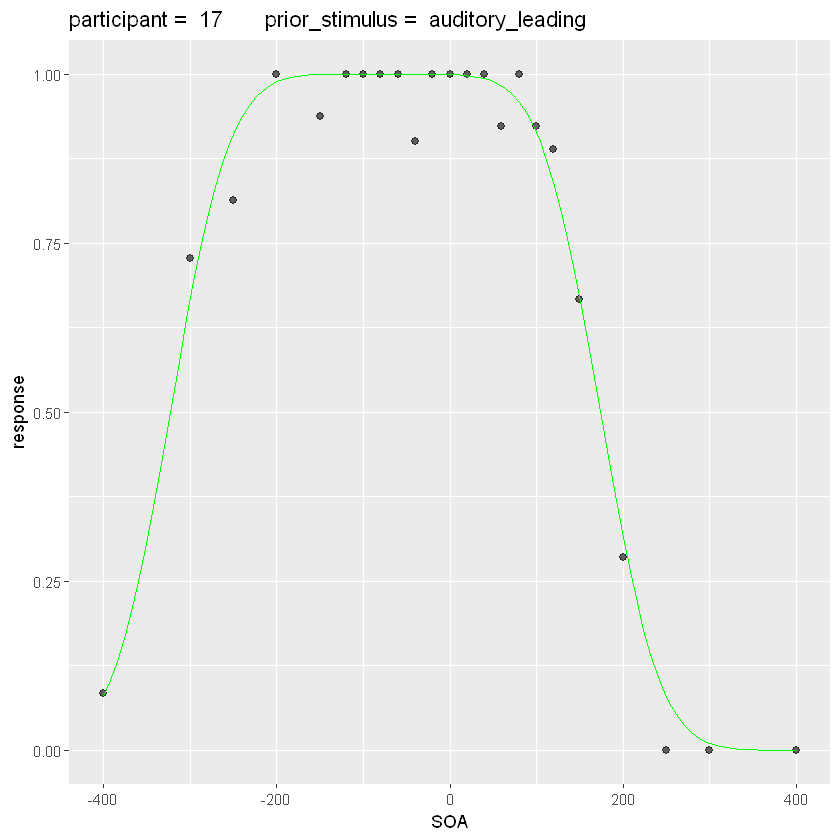

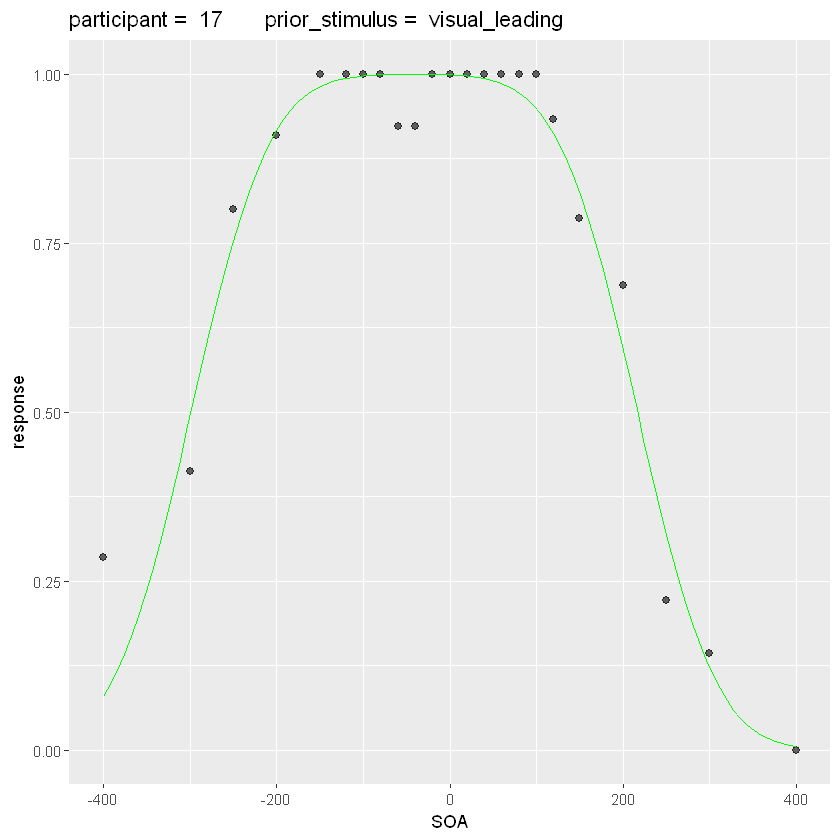

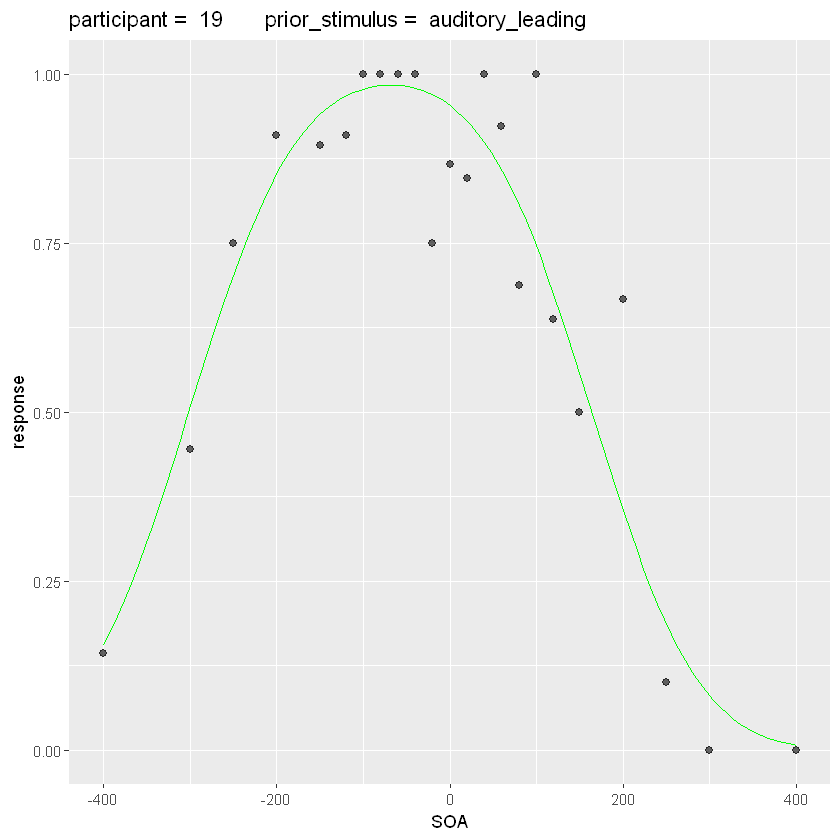

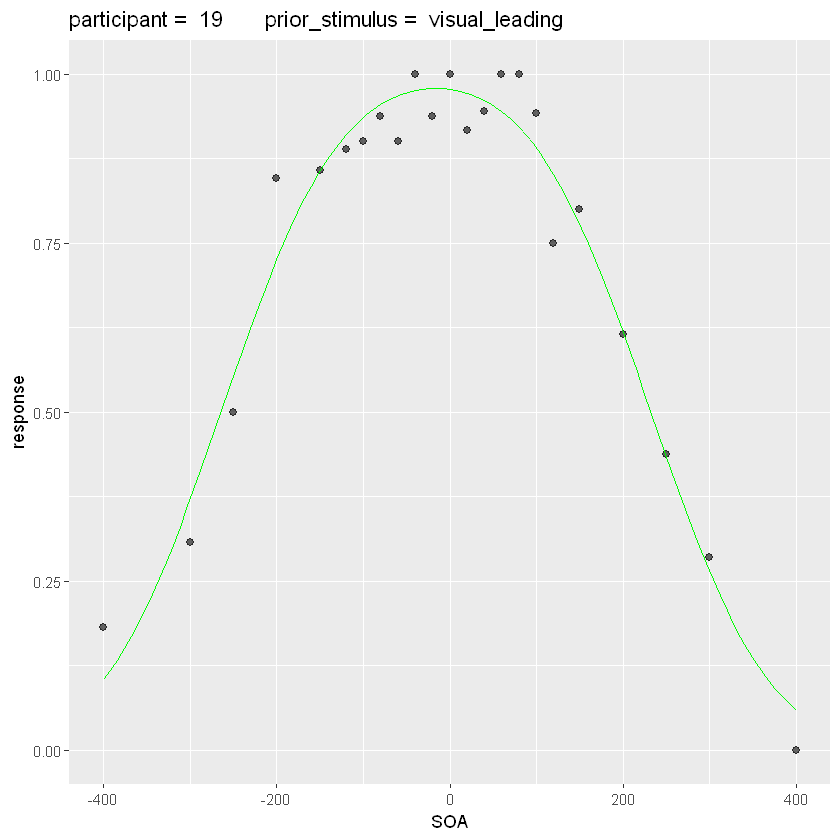

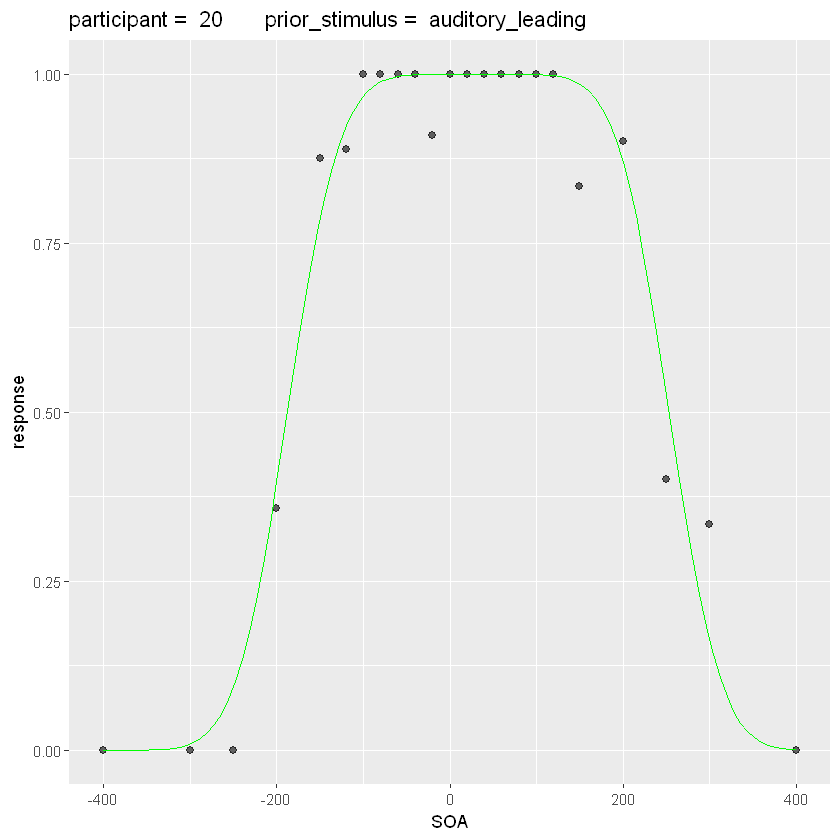

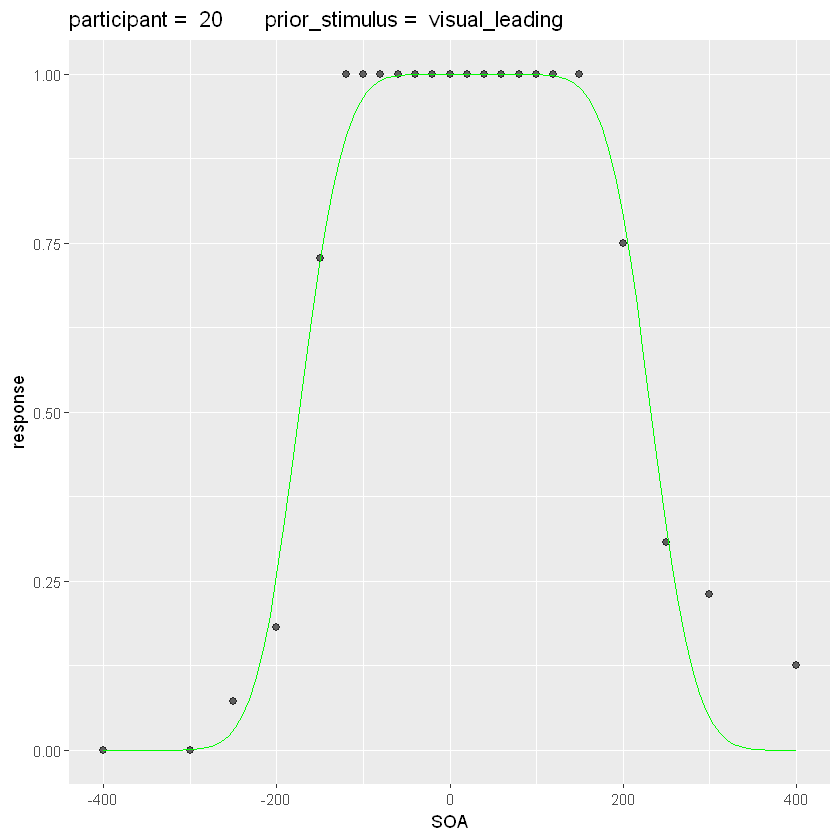

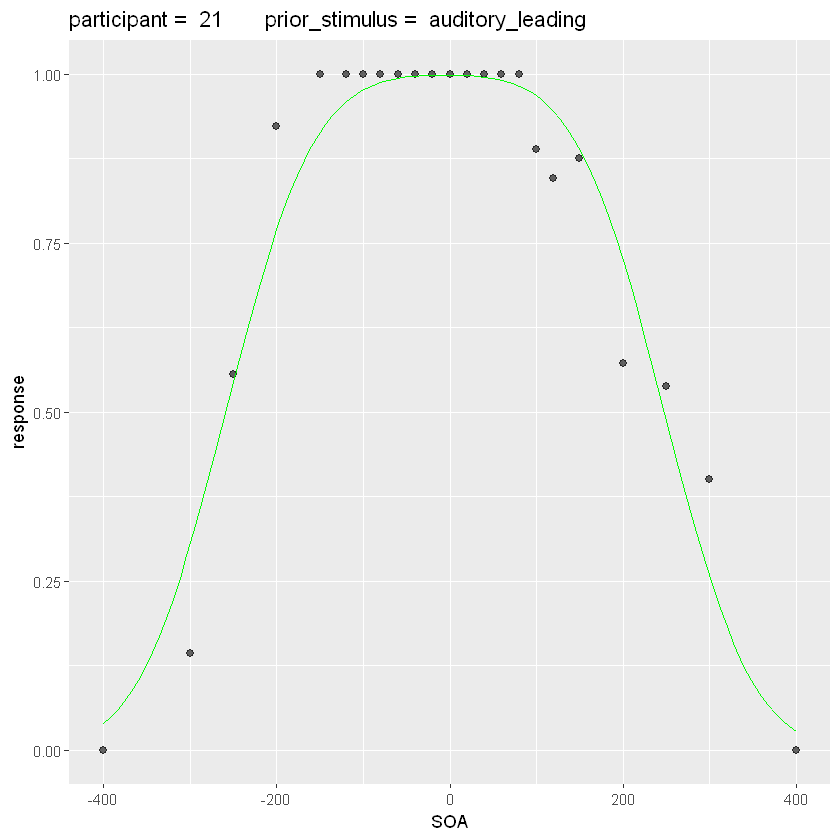

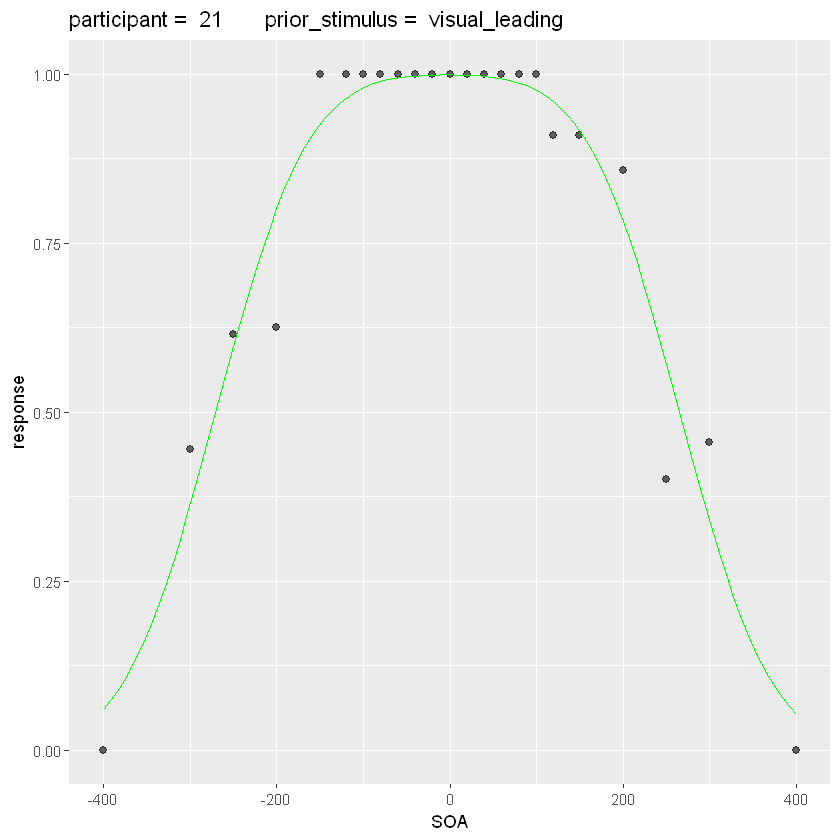

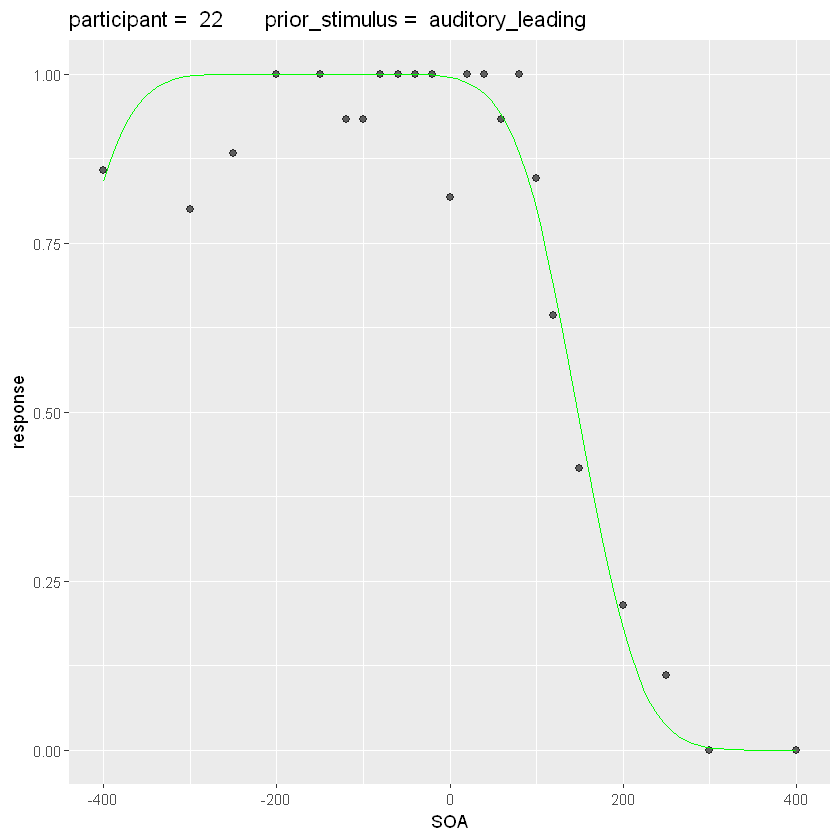

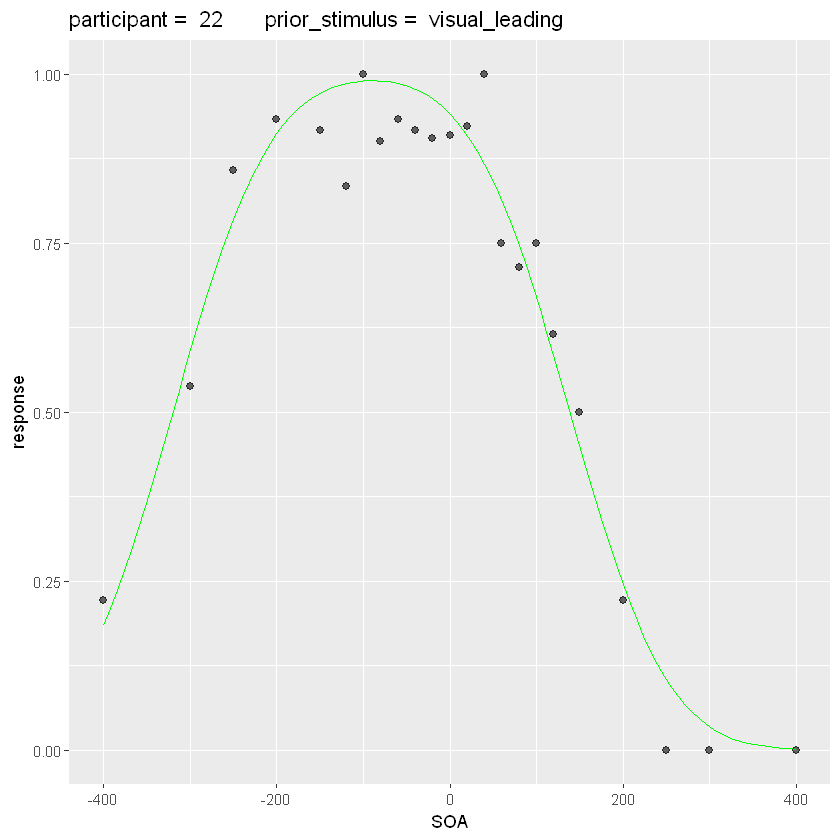

In [21]:
ff <- function(x,Clow,Chigh,sigma){
      pnorm(x, mean = Clow, sd = sigma) -
    pnorm(x, mean = Chigh, sd = sigma)
}

data_mean <- data %>% group_by(participant, prior_stimulus, SOA) %>%   
    summarise(
                response = mean(response == 1),
                n_trials = n(),
                .groups = "drop"
              )

for(subj in unique(data$participant)){

    d1 <- data_mean %>% filter(participant == subj)
    for(ps in unique(data$prior_stimulus)){
        d2 <- d1 %>% filter(prior_stimulus == ps)

        Clow <- (model_results %>% filter(participant == subj) %>% filter(prior_stimulus == ps))$Clow
        Chigh <- (model_results %>% filter(participant == subj) %>% filter(prior_stimulus == ps))$Chigh
        sigma <- (model_results %>% filter(participant == subj) %>% filter(prior_stimulus == ps))$sigma
        print(ggplot(d2, aes(x = SOA, y = response)) +
                geom_point(size = 2, alpha = 0.6) +
                geom_function(fun=ff, args = list(Clow = Clow, Chigh = Chigh, sigma = sigma), color='green') +
                labs(title = paste('participant = ',subj,'      prior_stimulus = ',ps)))
            
}}

In [22]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){
  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)
  return(1 - SS_res / SS_tot)
}

model_results$R2 <- NA

for(i in 1:nrow(model_results)){
  id <- model_results$participant[i]
  ps <- model_results$prior_stimulus[i]
  subdata <- data_mean %>% filter(participant == id) %>% filter(prior_stimulus == ps)
  pred <- ff(subdata$SOA, model_results$Clow[i], model_results$Chigh[i], model_results$sigma[i])
  model_results$R2[i] <- R2(subdata$response, pred)
}

head(model_results)

,participant,prior_stimulus,Clow,Chigh,sigma,PSS,R2
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,auditory_leading,-244.9381,172.88617,59.88726,-36.02595,0.9449122
2,1,visual_leading,-252.8220,197.57758,50.34732,-27.62223,0.9686345
3,3,auditory_leading,-194.1878,56.60296,133.46239,-68.79241,0.7480422
4,3,visual_leading,-196.1594,62.97677,124.87557,-66.59131,0.8244559
5,4,auditory_leading,-261.1994,111.29195,178.19228,-74.95371,0.7497288
6,4,visual_leading,-244.8072,81.10409,169.60502,-81.85155,0.7988711


In [23]:
model_results %>% arrange(R2)

participant,prior_stimulus,Clow,Chigh,sigma,PSS,R2
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
3,auditory_leading,-194.1878,56.60296,133.46239,-68.792414,0.7480422
4,auditory_leading,-261.1994,111.29195,178.19228,-74.953710,0.7497288
4,visual_leading,-244.8072,81.10409,169.60502,-81.851546,0.7988711
8,visual_leading,-177.9891,103.85298,120.24264,-37.068079,0.8090474
15,auditory_leading,-267.2083,198.82019,138.17417,-34.194076,0.8144613
3,visual_leading,-196.1594,62.97677,124.87557,-66.591307,0.8244559
12,auditory_leading,-256.0944,129.30273,118.44297,-63.395828,0.8570738
12,visual_leading,-247.6636,109.12868,108.75934,-69.267454,0.8687506
7,visual_leading,-248.3944,173.40322,105.21310,-37.495613,0.8687694


In [121]:
## Save Parameter Estimates

write_xlsx(model_results, "files/SJ_prior_stimulus_observer_parameters.xlsx")

###############################################################
## 2-4 Plot group-level fits

In [24]:
model_results <- read_xlsx("files/SJ_prior_stimulus_observer_parameters.xlsx")
head(model_results)

participant,prior_stimulus,Clow,Chigh,sigma,PSS,delta_c
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,auditory_leading,-244.9381,172.88617,59.88726,-36.02595,417.8242
1,visual_leading,-252.8220,197.57758,50.34732,-27.62223,450.3996
3,auditory_leading,-194.1878,56.60296,133.46239,-68.79241,250.7907
3,visual_leading,-196.1594,62.97677,124.87557,-66.59131,259.1362
4,auditory_leading,-261.1994,111.29195,178.19228,-74.95371,372.4913
4,visual_leading,-244.8072,81.10409,169.60502,-81.85155,325.9113


In [25]:
ff <- function(x,Clow,Chigh,sigma){
      pnorm(x, mean = Clow, sd = sigma) -
    pnorm(x, mean = Chigh, sd = sigma)
}

df_predicted <- data.frame()

for(subj in unique(data$participant)){
    for(ps in unique(data$prior_stimulus)){
        Clow <- (model_results %>% filter(participant == subj) %>% filter(prior_stimulus == ps))$Clow
        Chigh <- (model_results %>% filter(participant == subj) %>% filter(prior_stimulus == ps))$Chigh
        sigma <- (model_results %>% filter(participant == subj) %>% filter(prior_stimulus == ps))$sigma
        df <- data.frame(participant=subj, prior_stimulus=ps, SOA = -400:400, response=ff(-400:400,Clow,Chigh,sigma))
        df_predicted <- rbind(df_predicted, df)
}}

In [26]:
###############################################################
# Compute observed psychometric data
###############################################################

df_summary <- data %>%
  group_by(participant, prior_stimulus, SOA) %>%
  summarise(
    mr = mean(response),
    .groups = "drop"
  ) %>% group_by(prior_stimulus, SOA) %>%
  summarise(
    mean_response = mean(mr),
    se = sd(mr) / sqrt(n()),
    .groups = "drop"
  )

df_predicted_summary <- df_predicted %>%
  group_by(prior_stimulus, SOA) %>%
  summarise(
    mean_response = mean(response),
    se = sd(response) / sqrt(n()),
    .groups = "drop"
  )

png 
  2

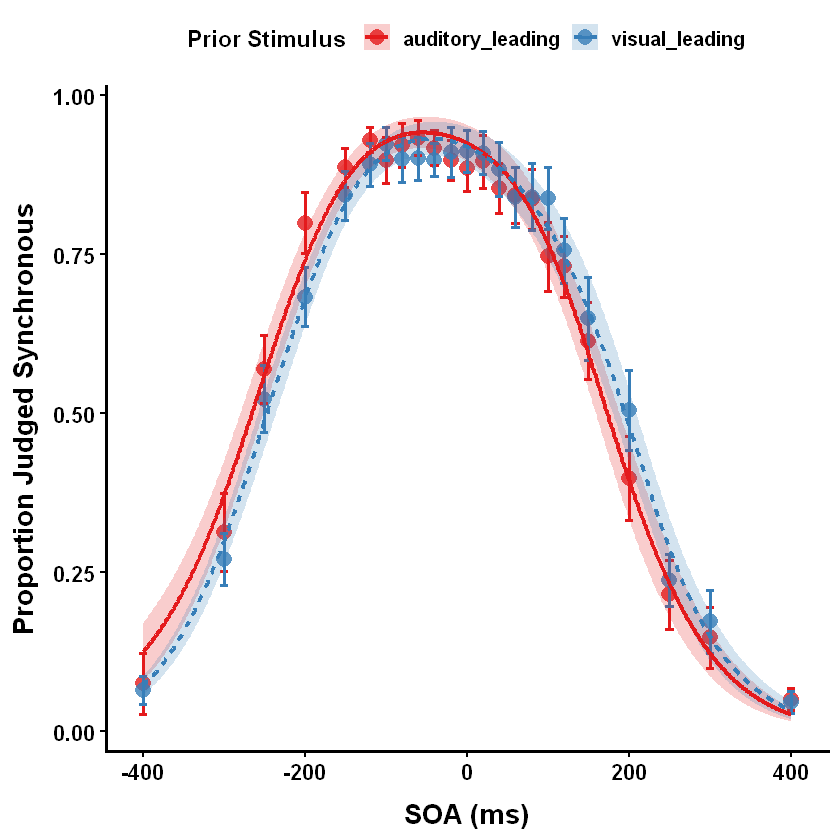

In [7]:
# =========================================================
# Visualize observed TOJ responses and fitted psychometric
# curves as a function of SOA and prior stimulus condition.
# =========================================================

pdf(file="figures/SJ_prior_stimulus_observer_response.pdf", width = 10, height = 8)

p_sj_prior_stim <- ggplot() +
  # Plot observed data points
  geom_point(
    data = df_summary,
    aes(x = SOA, y = mean_response, color = prior_stimulus),
    alpha = 0.8,
    size = 4,
    shape = 16
  ) +


  # Add error bars for observed data
  geom_errorbar(
    data = df_summary,
    aes(
      x = SOA,
      ymin = mean_response - se,
      ymax = mean_response + se,
      color = prior_stimulus
    ),
    width = 10,
    linewidth = 1
  ) +


  # Add shaded ribbon around fitted values
  geom_ribbon(
    data = df_predicted_summary,
    aes(
      x = SOA,
      ymin = mean_response - se,
      ymax = mean_response + se,
      fill = prior_stimulus,
      group = prior_stimulus
    ),
    alpha = 0.22,
    color = NA
  ) +

  # Plot fitted curves
  geom_line(
    data = df_predicted_summary,
    aes(
      x = SOA,
      y = mean_response,
      color = prior_stimulus,
      linetype = prior_stimulus,
      group = prior_stimulus
    ),
    linewidth = 1.2
  ) +

  # Define labels
  labs(
    x = "SOA (ms)",
    y = "Proportion Judged Synchronous",
    color = "Prior Stimulus",
    linetype = "Prior Stimulus",
    fill = "Prior Stimulus"
  ) +

  # Use a clean theme consistent with previous figures
  theme_classic(base_size = 14) +
  theme(
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    legend.position = "top",
    axis.line = element_line(linewidth = 1)
  ) +

  # Use the same color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  scale_fill_brewer(palette = "Set1")
p_sj_prior_stim
dev.off()
# Display the plot
print(p_sj_prior_stim)

###############################################################
## 2-5 Statistical test of sigma

In [29]:
psy_results <- read_xlsx("files/SJ_prior_stimulus_observer_parameters.xlsx")
head(psy_results)

participant,prior_stimulus,Clow,Chigh,sigma,PSS,delta_c
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,auditory_leading,-244.9381,172.88617,59.88726,-36.02595,417.8242
1,visual_leading,-252.8220,197.57758,50.34732,-27.62223,450.3996
3,auditory_leading,-194.1878,56.60296,133.46239,-68.79241,250.7907
3,visual_leading,-196.1594,62.97677,124.87557,-66.59131,259.1362
4,auditory_leading,-261.1994,111.29195,178.19228,-74.95371,372.4913
4,visual_leading,-244.8072,81.10409,169.60502,-81.85155,325.9113


In [30]:
psy_results2 <- psy_results %>% group_by(participant) %>% summarise(
    diff = sigma[prior_stimulus == "visual_leading"] - sigma[prior_stimulus == "auditory_leading"],
    .groups = "drop"
  )
head(psy_results2)

participant,diff
<dbl>,<dbl>
1,-9.539933
3,-8.586821
4,-8.587267
5,5.247442
7,13.985913
8,9.107356


In [31]:
#summary
psy_results %>% group_by(prior_stimulus) %>%  get_summary_stats(sigma)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory_leading,sigma,18,43.761,178.192,91.399,57.418,109.771,52.353,47.493,89.611,36.818,8.678,18.309
visual_leading,sigma,18,40.357,169.605,93.512,73.979,108.457,34.478,27.630,93.892,31.101,7.331,15.466


In [32]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-33.506,31.849,5.661,-8.587,15.102,23.689,19.968,4.28,17.205,4.055,8.556


In [33]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

participant,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [34]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")

In [35]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9646453,0.6931023


Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the ggpubr package.
  Please report the issue at <https://github.com/kassambara/ggpubr/issues>."
Warning message:
"The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the ggpubr package.
  Please report the issue at <https://github.com/kassambara/ggpubr/issues>."


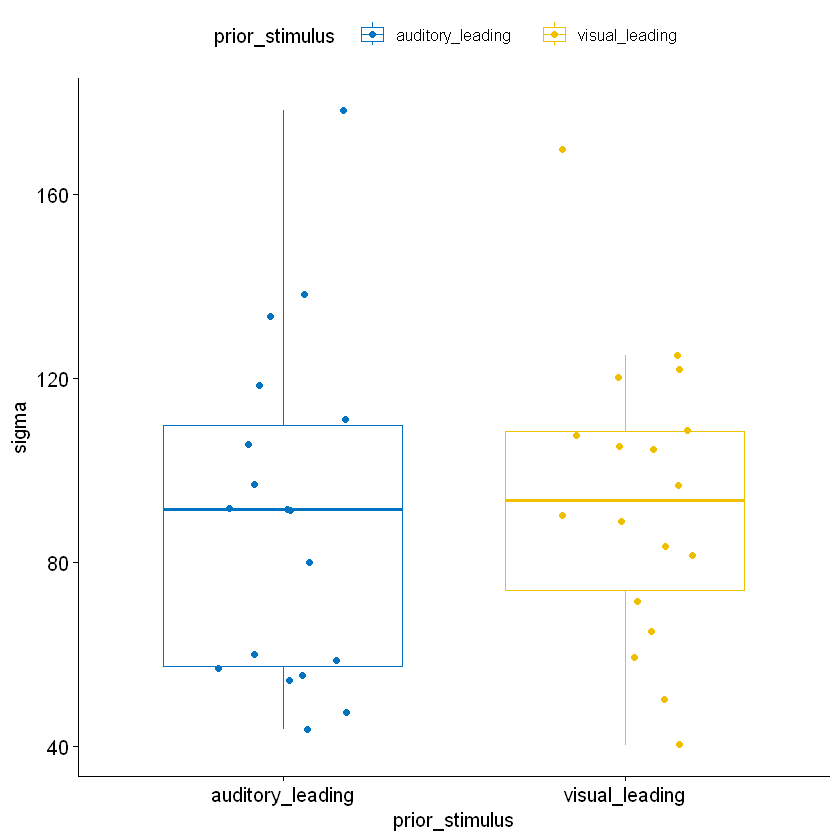

In [36]:
#plot
ggboxplot(
  psy_results, x = "prior_stimulus", y = "sigma",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

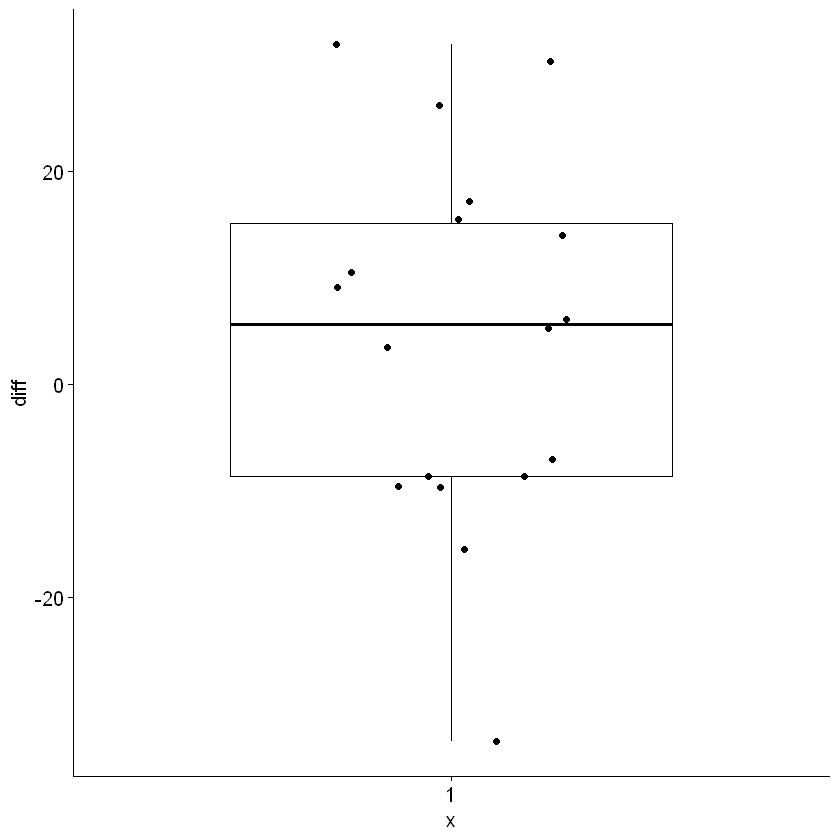

In [37]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [38]:
psy_results %>% t_test(sigma ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-4.280194,sigma,auditory_leading,visual_leading,18,18,-1.055441,0.306,17,-12.83626,4.275873,T-test,two.sided


In [39]:
psy_results %>% cohens_d(sigma ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,sigma,auditory_leading,visual_leading,-0.2487697,18,18,small


###############################################################
## 2-6 Statistical test of Criterion_Low

In [40]:
psy_results <- read_xlsx("files/SJ_prior_stimulus_observer_parameters.xlsx")
head(psy_results)

participant,prior_stimulus,Clow,Chigh,sigma,PSS,delta_c
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,auditory_leading,-244.9381,172.88617,59.88726,-36.02595,417.8242
1,visual_leading,-252.8220,197.57758,50.34732,-27.62223,450.3996
3,auditory_leading,-194.1878,56.60296,133.46239,-68.79241,250.7907
3,visual_leading,-196.1594,62.97677,124.87557,-66.59131,259.1362
4,auditory_leading,-261.1994,111.29195,178.19228,-74.95371,372.4913
4,visual_leading,-244.8072,81.10409,169.60502,-81.85155,325.9113


In [41]:
psy_results2 <- psy_results %>% group_by(participant) %>% summarise(
    diff = Clow[prior_stimulus == "visual_leading"] - Clow[prior_stimulus == "auditory_leading"],
    .groups = "drop"
  )
head(psy_results2)

participant,diff
<dbl>,<dbl>
1,-7.883978
3,-1.971597
4,16.392186
5,24.564309
7,25.749336
8,53.732357


In [42]:
#summary
psy_results %>% group_by(prior_stimulus) %>%  get_summary_stats(Clow)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory_leading,Clow,18,-456.825,-187.670,-261.956,-297.069,-247.727,49.342,38.759,-270.357,60.804,14.332,30.237
visual_leading,Clow,18,-320.274,-174.017,-250.608,-270.136,-232.839,37.297,29.060,-248.137,41.086,9.684,20.432


In [43]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-11.611,136.551,15.023,4.933,29.76,24.827,20.26,22.22,33.347,7.86,16.583


In [44]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

participant,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>
22,136.5512,TRUE,TRUE


In [45]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")

In [46]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9732244,0.8720642


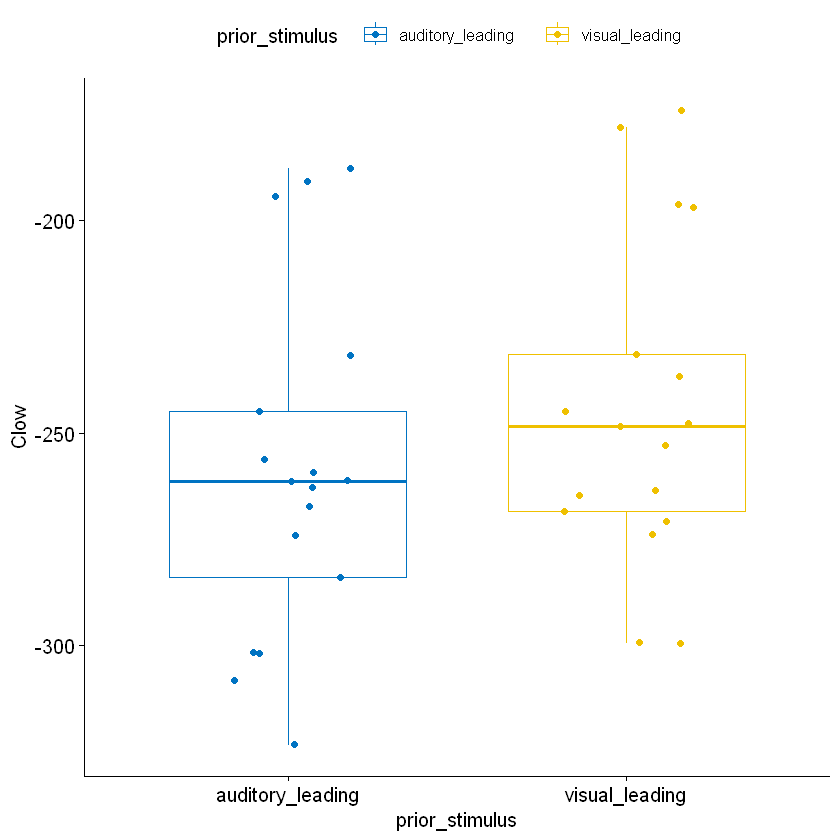

In [47]:
#plot
ggboxplot(
  psy_results, x = "prior_stimulus", y = "Clow",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

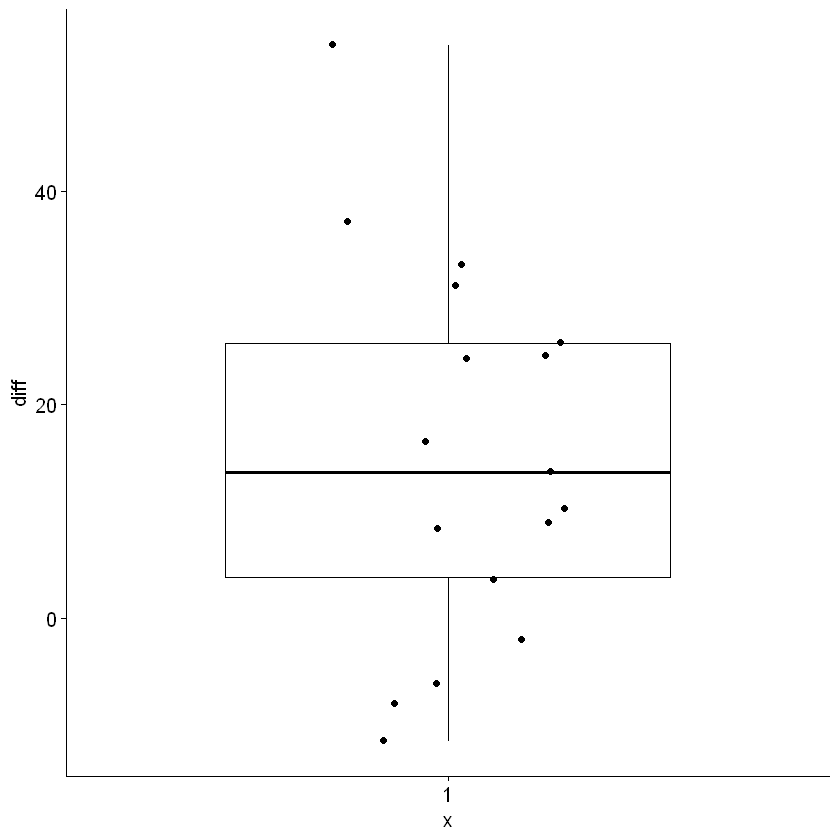

In [48]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [49]:
psy_results %>% t_test(Clow ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-15.49492,Clow,auditory_leading,visual_leading,17,17,-3.591012,0.00245,16,-24.64213,-6.347703,T-test,two.sided


In [50]:
psy_results %>% cohens_d(Clow ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,Clow,auditory_leading,visual_leading,-0.8709483,17,17,large


###############################################################
## 2-7 Statistical test of Criterion_High

In [51]:
psy_results <- read_xlsx("files/SJ_prior_stimulus_observer_parameters.xlsx")
head(psy_results)

participant,prior_stimulus,Clow,Chigh,sigma,PSS,delta_c
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,auditory_leading,-244.9381,172.88617,59.88726,-36.02595,417.8242
1,visual_leading,-252.8220,197.57758,50.34732,-27.62223,450.3996
3,auditory_leading,-194.1878,56.60296,133.46239,-68.79241,250.7907
3,visual_leading,-196.1594,62.97677,124.87557,-66.59131,259.1362
4,auditory_leading,-261.1994,111.29195,178.19228,-74.95371,372.4913
4,visual_leading,-244.8072,81.10409,169.60502,-81.85155,325.9113


In [52]:
psy_results2 <- psy_results %>% group_by(participant) %>% summarise(
    diff = Chigh[prior_stimulus == "visual_leading"] - Chigh[prior_stimulus == "auditory_leading"],
    .groups = "drop"
  )
head(psy_results2)

participant,diff
<dbl>,<dbl>
1,24.691406
3,6.373811
4,-30.187861
5,12.903448
7,31.291364
8,-9.847752


In [53]:
#summary
psy_results %>% group_by(prior_stimulus) %>%  get_summary_stats(Chigh)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory_leading,Chigh,18,56.603,312.483,167.688,131.136,211.615,80.479,64.179,173.322,65.819,15.514,32.731
visual_leading,Chigh,18,62.977,314.376,198.636,139.239,231.316,92.077,67.984,187.667,71.021,16.740,35.318


In [54]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-30.188,68.333,15.213,-6.577,35.5,42.078,32.322,14.345,26.589,6.267,13.222


In [55]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

participant,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [56]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")

In [57]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9750228,0.8849611


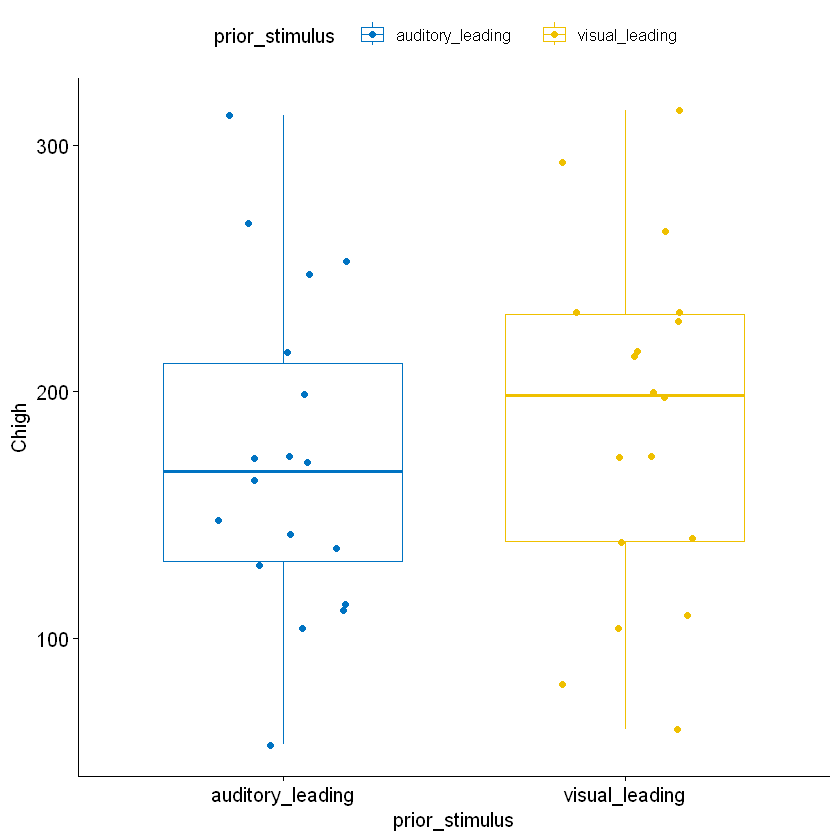

In [58]:
#plot
ggboxplot(
  psy_results, x = "prior_stimulus", y = "Chigh",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

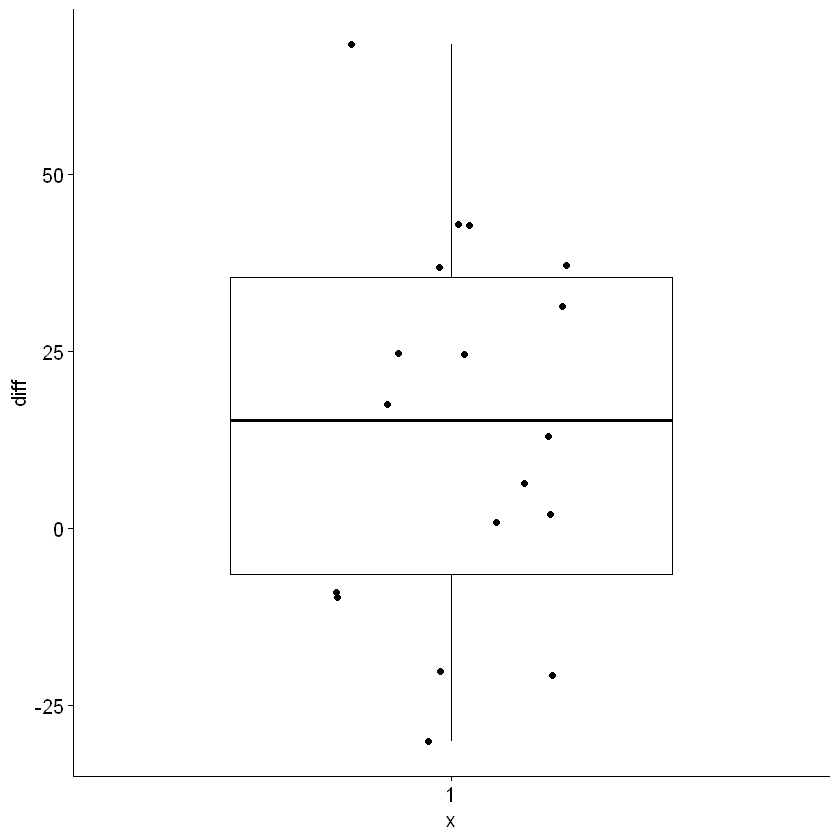

In [59]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [60]:
psy_results %>% t_test(Chigh ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-14.3445,Chigh,auditory_leading,visual_leading,18,18,-2.288896,0.0352,17,-27.56671,-1.122298,T-test,two.sided


In [61]:
psy_results %>% cohens_d(Chigh ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,Chigh,auditory_leading,visual_leading,-0.539498,18,18,moderate


###############################################################
## 2-8 Statistical test of PSS

In [62]:
psy_results <- read_xlsx("files/SJ_prior_stimulus_observer_parameters.xlsx")
head(psy_results)

participant,prior_stimulus,Clow,Chigh,sigma,PSS,delta_c
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,auditory_leading,-244.9381,172.88617,59.88726,-36.02595,417.8242
1,visual_leading,-252.8220,197.57758,50.34732,-27.62223,450.3996
3,auditory_leading,-194.1878,56.60296,133.46239,-68.79241,250.7907
3,visual_leading,-196.1594,62.97677,124.87557,-66.59131,259.1362
4,auditory_leading,-261.1994,111.29195,178.19228,-74.95371,372.4913
4,visual_leading,-244.8072,81.10409,169.60502,-81.85155,325.9113


In [63]:
psy_results2 <- psy_results %>% group_by(participant) %>% summarise(
    diff = PSS[prior_stimulus == "visual_leading"] - PSS[prior_stimulus == "auditory_leading"],
    .groups = "drop"
  )
head(psy_results2)

participant,diff
<dbl>,<dbl>
1,8.403714
3,2.201107
4,-6.897837
5,18.733879
7,28.520350
8,21.942303


In [64]:
#summary
psy_results %>% group_by(prior_stimulus) %>%  get_summary_stats(PSS)

prior_stimulus,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
auditory_leading,PSS,18,-154.502,32.734,-52.281,-68.908,-25.566,43.342,29.275,-48.517,40.442,9.532,20.111
visual_leading,PSS,18,-90.757,29.184,-29.963,-47.818,-5.102,42.716,35.162,-30.235,33.154,7.814,16.487


In [65]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-6.898,63.745,17.066,2.479,28.797,26.318,21.39,18.282,20.015,4.717,9.953


In [66]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

participant,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [67]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")

In [68]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9353617,0.2410107


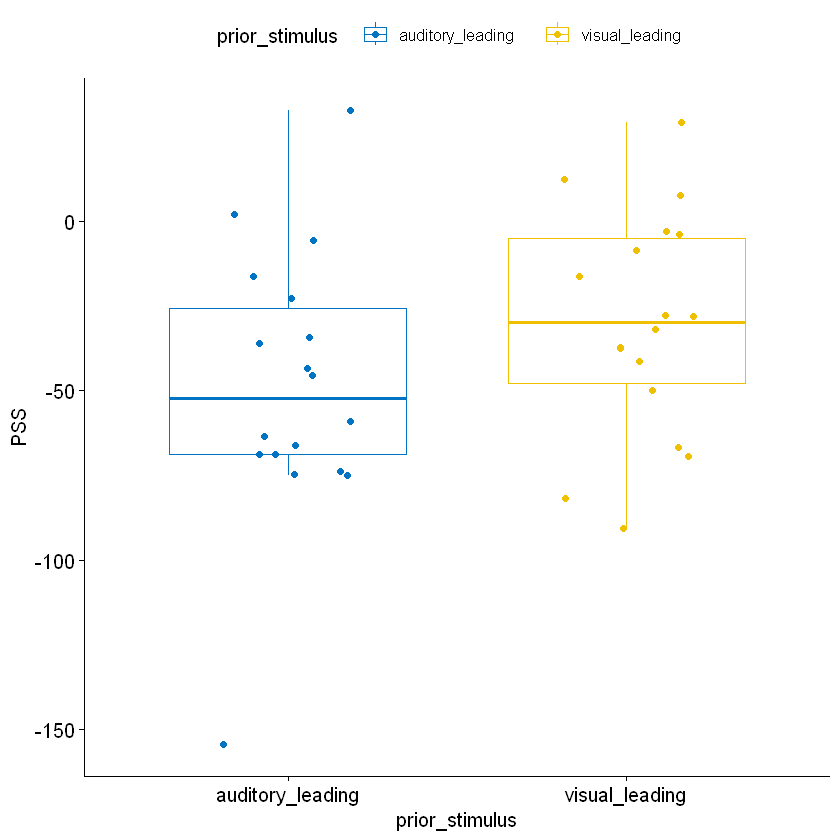

In [69]:
#plot
ggboxplot(
  psy_results, x = "prior_stimulus", y = "PSS",
  color = "prior_stimulus", palette = "jco", add = "jitter"
  )

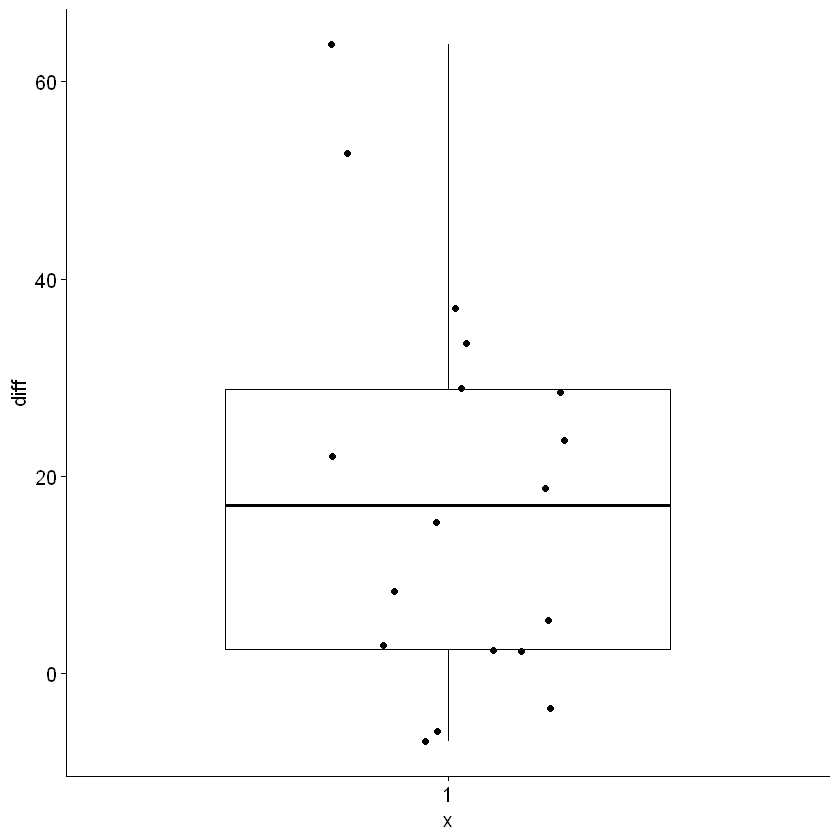

In [70]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [71]:
psy_results %>% t_test(PSS ~ prior_stimulus, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-18.28238,PSS,auditory_leading,visual_leading,18,18,-3.87545,0.00121,17,-28.23541,-8.329357,T-test,two.sided


In [72]:
psy_results %>% cohens_d(PSS ~ prior_stimulus, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,PSS,auditory_leading,visual_leading,-0.9134523,18,18,large


###############################################################\
###############################################################
# 3- Serial Dependence based on Prior Response
**List of contents:**\
3-1 Load data\
3-2 Fit psychometric model\
3-3 Check fits\
3-4 Plot group-level fits\
3-5 Statistical test of sigma\
3-6 Statistical test of Criterion_Low\
3-7 Statistical test of Criterion_High\
3-8 Statistical test of PSS

###############################################################
## 3-1 Load data

In [75]:
###############################################################
# Load SJ serial dependence dataset (prepared previously)
###############################################################

data <- read_xlsx("files/SJ_prior_response_data.xlsx")
head(data)

participant,pre_resp,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,asynchrony,-400,asynchrony,1.437342
1,asynchrony,-400,asynchrony,1.169998
1,asynchrony,-400,asynchrony,1.236840
1,asynchrony,-400,asynchrony,1.186734
1,asynchrony,-400,asynchrony,1.403907
1,asynchrony,-400,asynchrony,1.069756


In [76]:
###############################################################
# Prepare behavioral variables
###############################################################

colnames(data)[4] <- "response"
colnames(data)[2] <- "prior_response"

data$response = ifelse(data$response == "synchrony", 1, 0)

data$prior_response[data$prior_response == 'synchrony'] <- "synchronous response"
data$prior_response[data$prior_response == 'asynchrony'] <- "asynchronous response"

head(data)

participant,prior_response,SOA,response,rt
<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,asynchronous response,-400,0,1.437342
1,asynchronous response,-400,0,1.169998
1,asynchronous response,-400,0,1.236840
1,asynchronous response,-400,0,1.186734
1,asynchronous response,-400,0,1.403907
1,asynchronous response,-400,0,1.069756


###############################################################
## 3-2 Fit psychometric model

In [77]:
# Model:
# P(synchronous)=Φ(SOA;Clow,σ)−Φ(SOA;Chigh,σ)

model <- function(data){
  loss_function <- function(params){
    Clow <- params[1]
    Chigh <- params[2]
    sigma <- params[3]
    predicted <-  pnorm(data$SOA, mean = Clow, sd = sigma) - pnorm(data$SOA, mean = Chigh, sd = sigma)
    sum((predicted - data$response)^2)
  }

  DEoptim(
    loss_function,
    lower = c(-500, -500, .0001),
    upper = c(500, 500, 1000)
  )
}

model_results <- data.frame()

for(subj in unique(data$participant)){

    d1 <- data %>% filter(participant == subj)
    for(pr in unique(data$prior_response)){
        d2 <- d1 %>% filter(prior_response == pr)
        fit <- model(d2)$optim$bestmem

        model_results <- rbind(
            model_results,
            data.frame(
              participant = subj,
              prior_response = pr,
              Clow = fit[1],
              Chigh = fit[2],
              sigma = fit[3]
    )
  )
}}

rownames(model_results) <- NULL

Iteration: 1 bestvalit: 24.410419 bestmemit: -213.822749  113.297550   78.334746
Iteration: 2 bestvalit: 24.410419 bestmemit: -213.822749  113.297550   78.334746
Iteration: 3 bestvalit: 24.410419 bestmemit: -213.822749  113.297550   78.334746
Iteration: 4 bestvalit: 24.410419 bestmemit: -213.822749  113.297550   78.334746
Iteration: 5 bestvalit: 24.410419 bestmemit: -213.822749  113.297550   78.334746
Iteration: 6 bestvalit: 23.579439 bestmemit: -202.170572  128.292389   32.936236
Iteration: 7 bestvalit: 23.579439 bestmemit: -202.170572  128.292389   32.936236
Iteration: 8 bestvalit: 23.579439 bestmemit: -202.170572  128.292389   32.936236
Iteration: 9 bestvalit: 23.579439 bestmemit: -202.170572  128.292389   32.936236
Iteration: 10 bestvalit: 21.900681 bestmemit: -229.144234  238.829414   45.728041
Iteration: 11 bestvalit: 19.700799 bestmemit: -238.494736  207.831762   89.273697
Iteration: 12 bestvalit: 19.700799 bestmemit: -238.494736  207.831762   89.273697
Iteration: 13 bestvalit: 

In [78]:
model_results <- model_results %>%
  mutate(
    PSS = (Clow + Chigh) / 2
  )

In [79]:
head(model_results)

,participant,prior_response,Clow,Chigh,sigma,PSS
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,asynchronous response,-221.0305,181.79011,58.74870,-19.62018
2,1,synchronous response,-254.5232,189.91598,52.38215,-32.30362
3,3,asynchronous response,-200.5636,61.04111,133.09752,-69.76127
4,3,synchronous response,-184.4021,50.34115,112.80065,-67.03046
5,4,asynchronous response,-269.1213,32.08636,201.91210,-118.51746
6,4,synchronous response,-261.5051,144.31105,146.94675,-58.59705


###############################################################
## 3-3 Check fits

In [80]:
nrow(model_results)

[1] 36

In [81]:
sort(model_results$Clow)

[1] -381.0665 -316.7930 -316.0345 -310.3129 -296.5851 -285.5490 -284.6873
 [8] -279.1029 -278.6477 -272.0812 -271.6300 -269.7016 -269.2399 -269.1213
[15] -266.9298 -266.5619 -265.9684 -263.1109 -262.0407 -261.5051 -254.5232
[22] -252.3841 -252.0291 -248.8748 -247.8615 -241.8577 -240.8651 -233.4631
[29] -221.0305 -202.7830 -200.5636 -185.7000 -184.4021 -183.4685 -181.4366
[36] -179.0630

In [82]:
sort(model_results$Chigh)

[1]  32.08636  50.34115  61.04111  77.87048  88.89539 101.59416 107.04104
 [8] 111.29024 125.86149 139.21196 139.26669 144.31105 149.39389 155.41221
[15] 163.39087 170.80396 175.13806 181.79011 182.39694 185.74773 189.91598
[22] 192.75499 193.12650 205.60122 205.66742 219.12677 220.43997 224.96231
[29] 230.84886 232.67758 233.77405 234.09071 240.39294 255.58904 287.62715
[36] 315.63087

In [83]:
sort(model_results$sigma)

[1]  42.68917  46.37198  51.49757  52.00415  52.38215  52.74489  58.74870
 [8]  61.21572  62.73742  66.90087  69.43162  69.54659  76.12206  78.38133
[15]  78.59383  84.33527  92.33974  93.51467  95.41474  95.62497  98.25861
[22] 100.88344 108.20721 109.79730 110.01760 112.13072 112.80065 114.51881
[29] 116.67270 117.28611 119.56592 122.58249 123.16657 133.09752 146.94675
[36] 201.91210

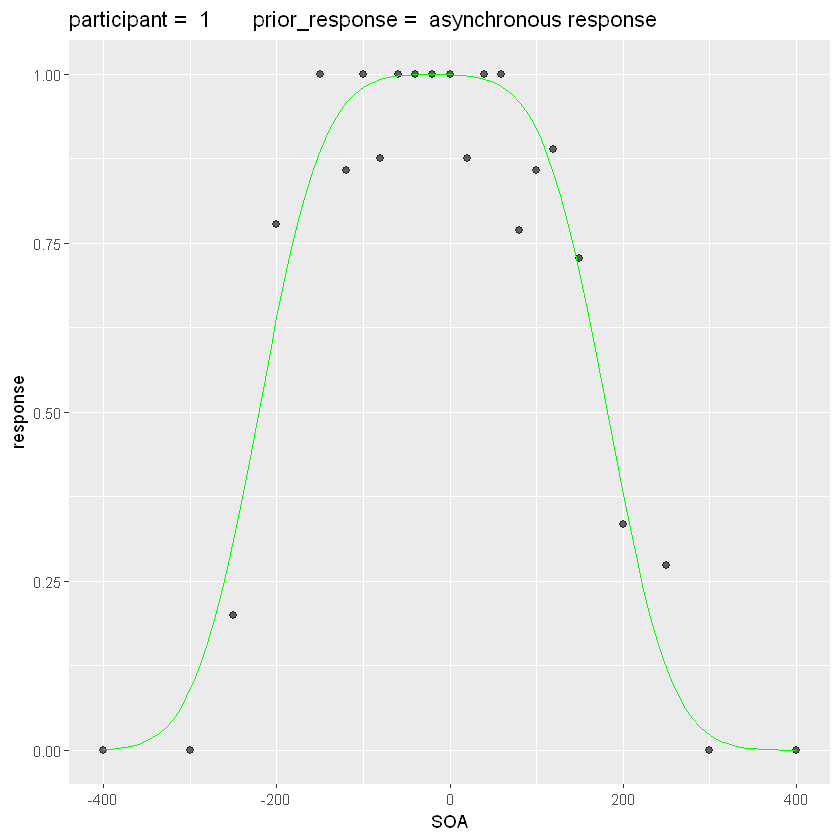

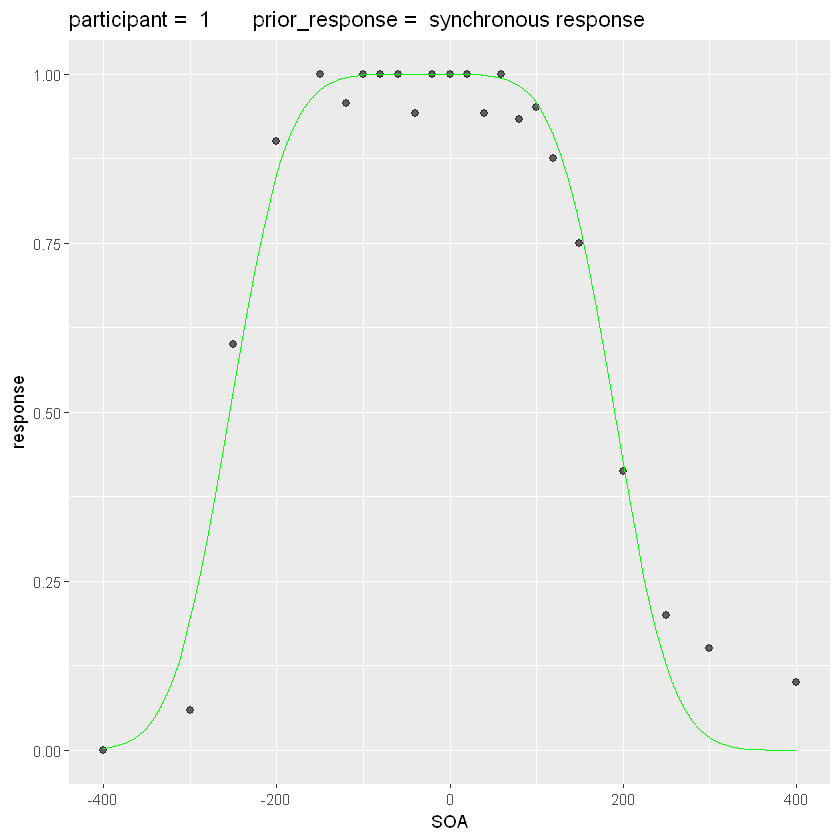

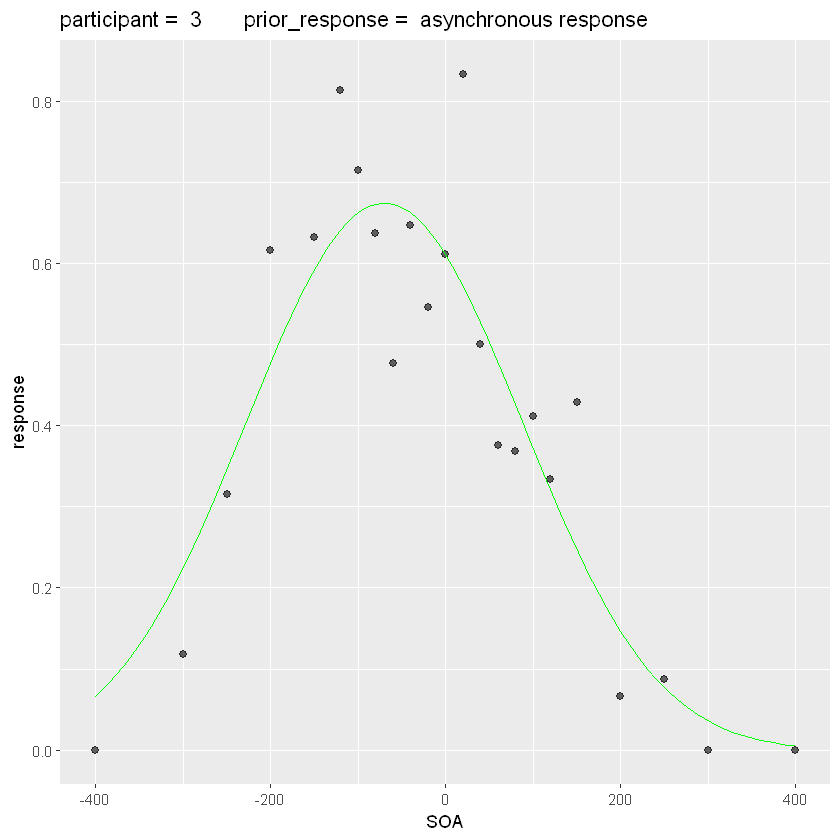

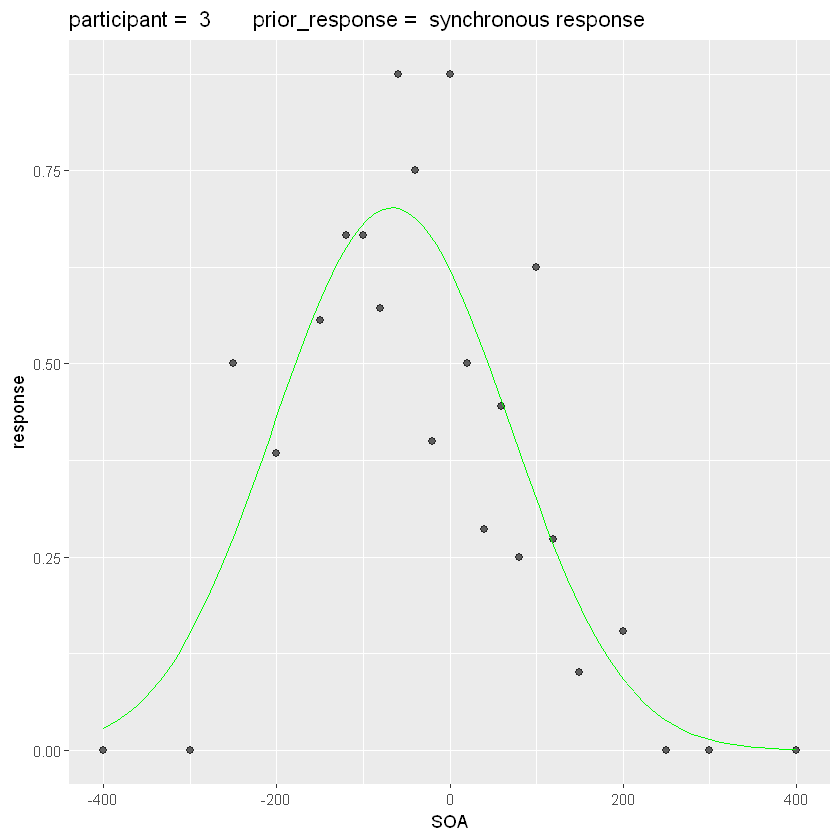

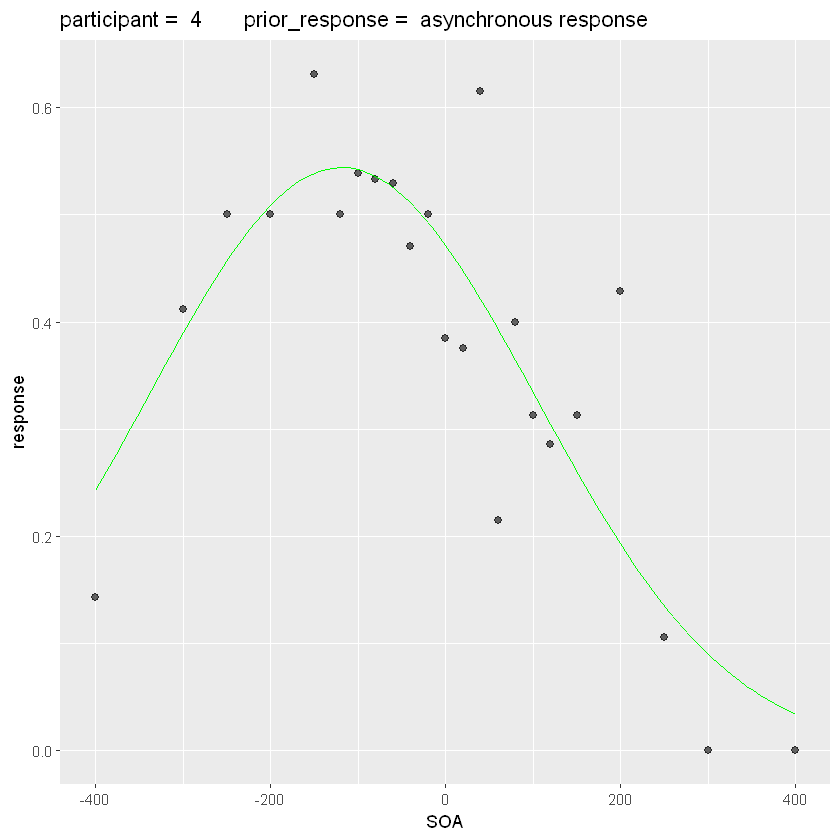

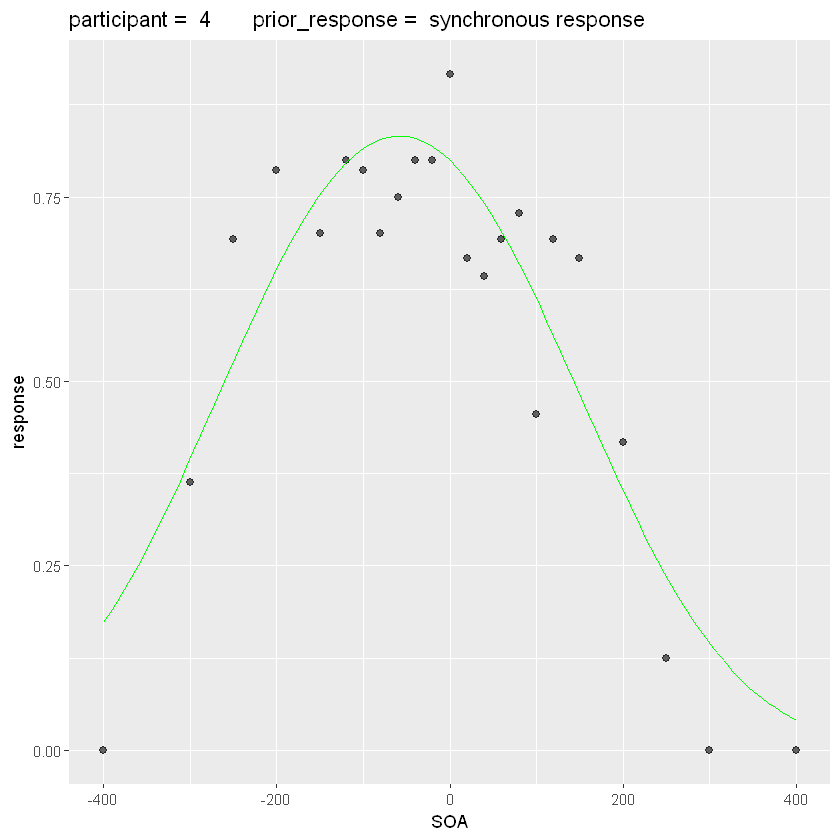

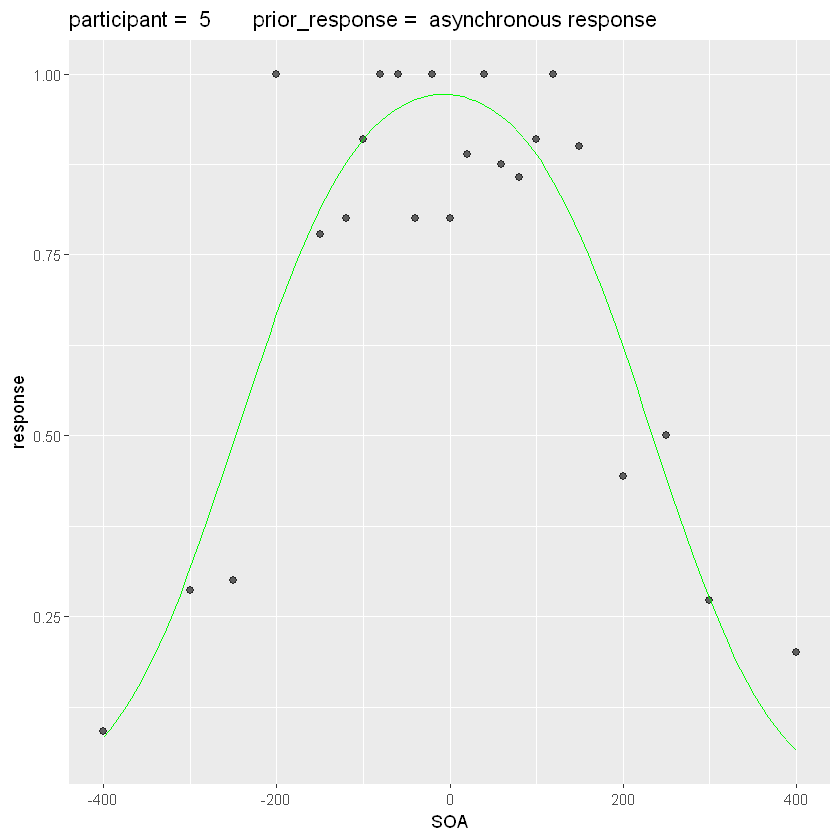

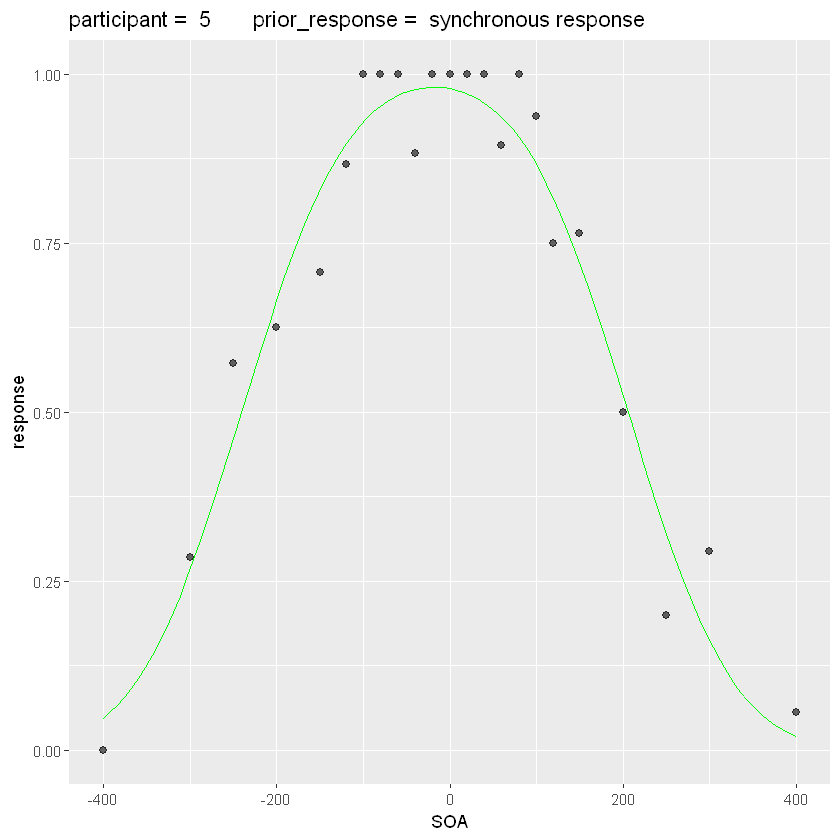

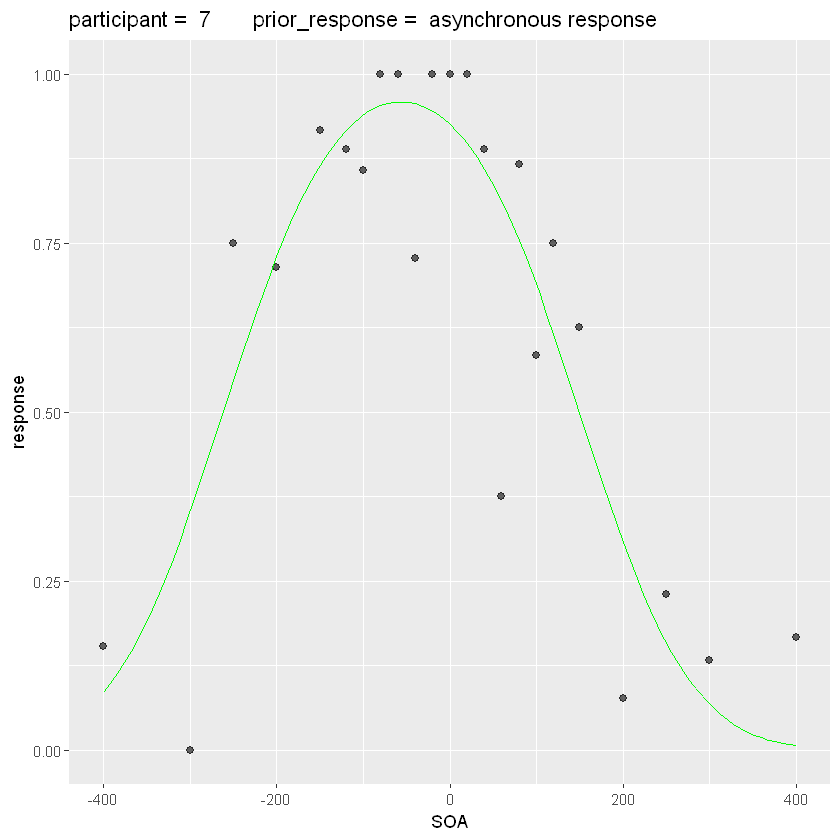

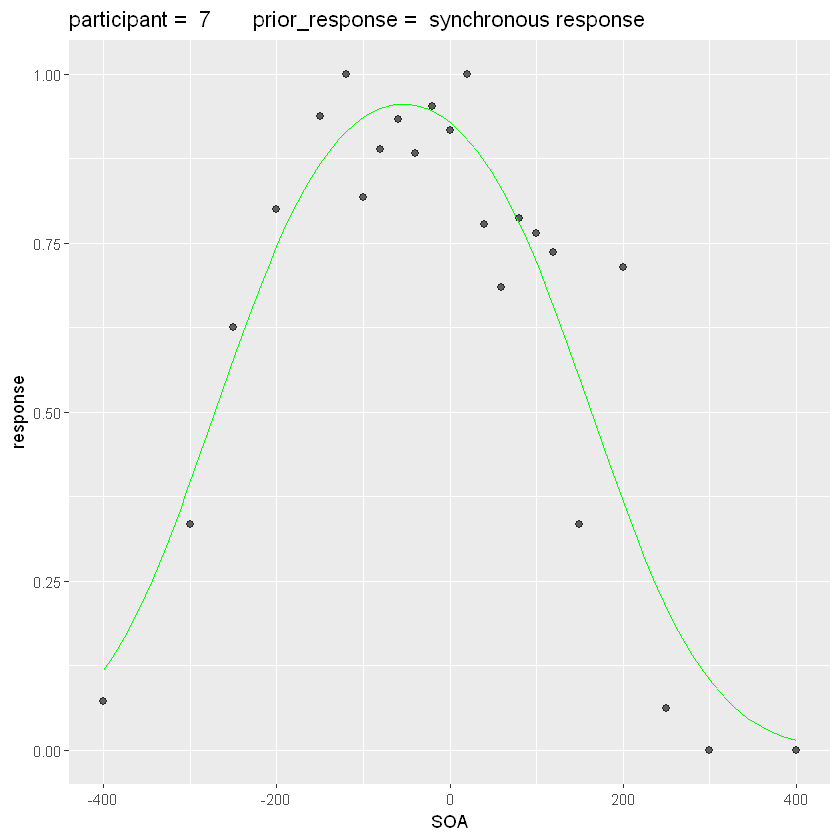

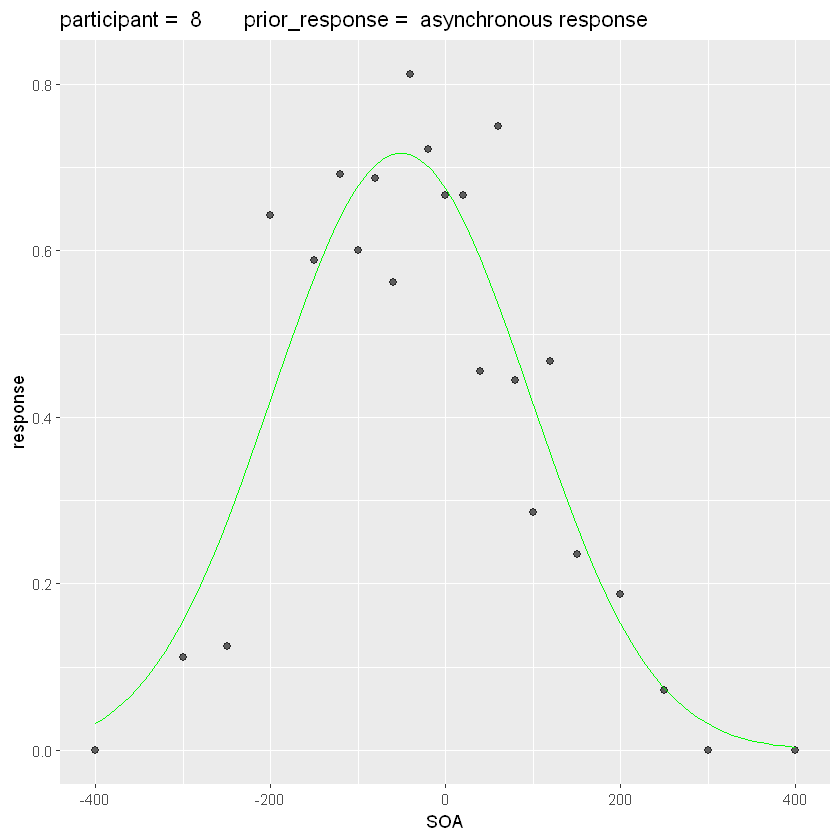

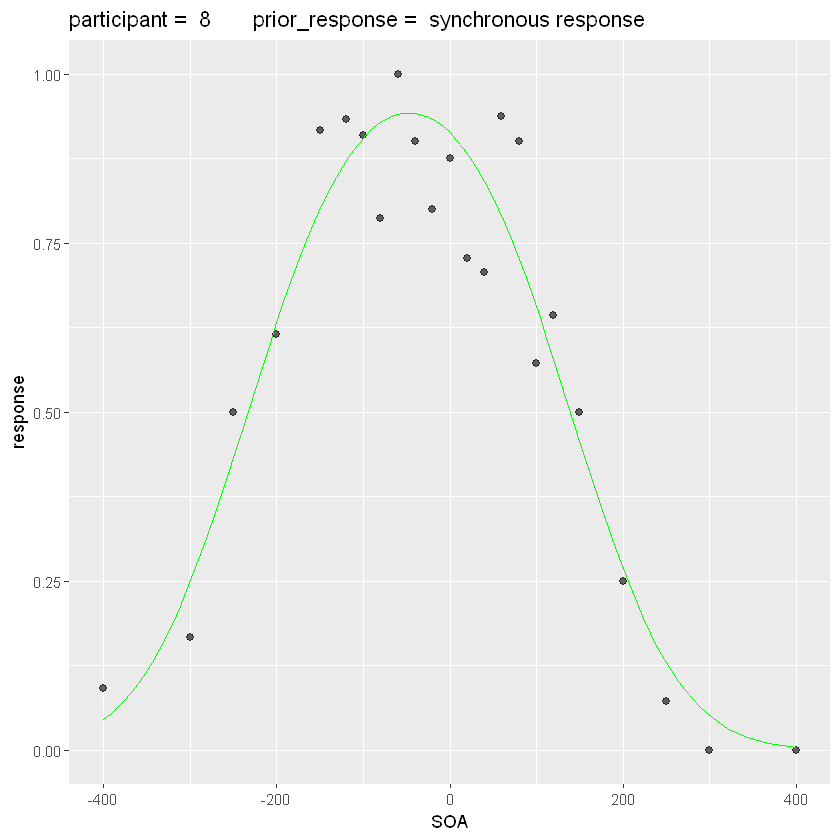

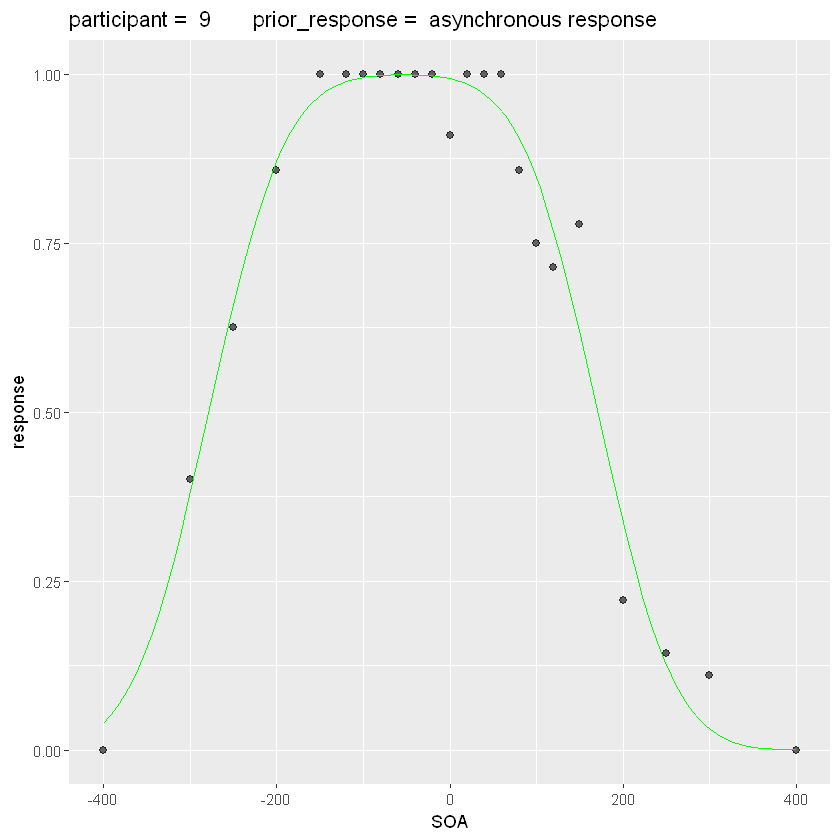

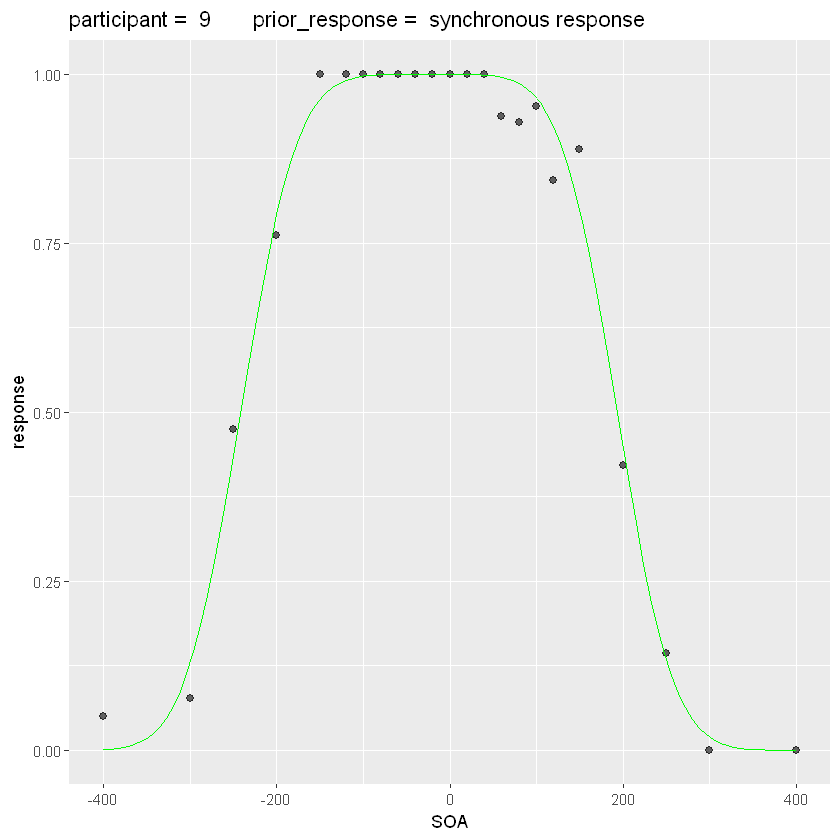

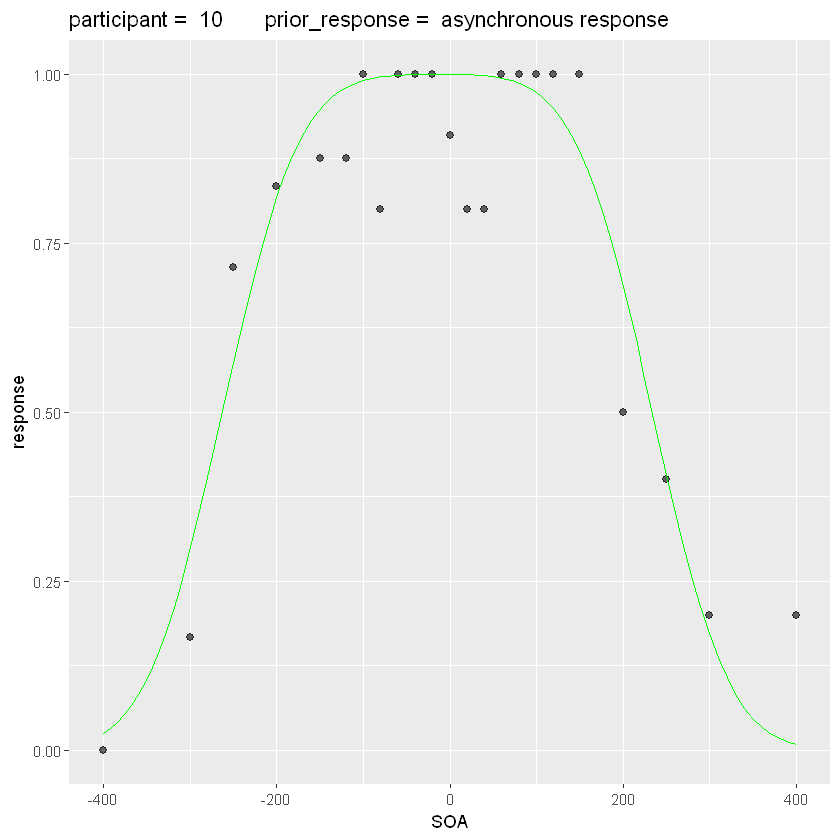

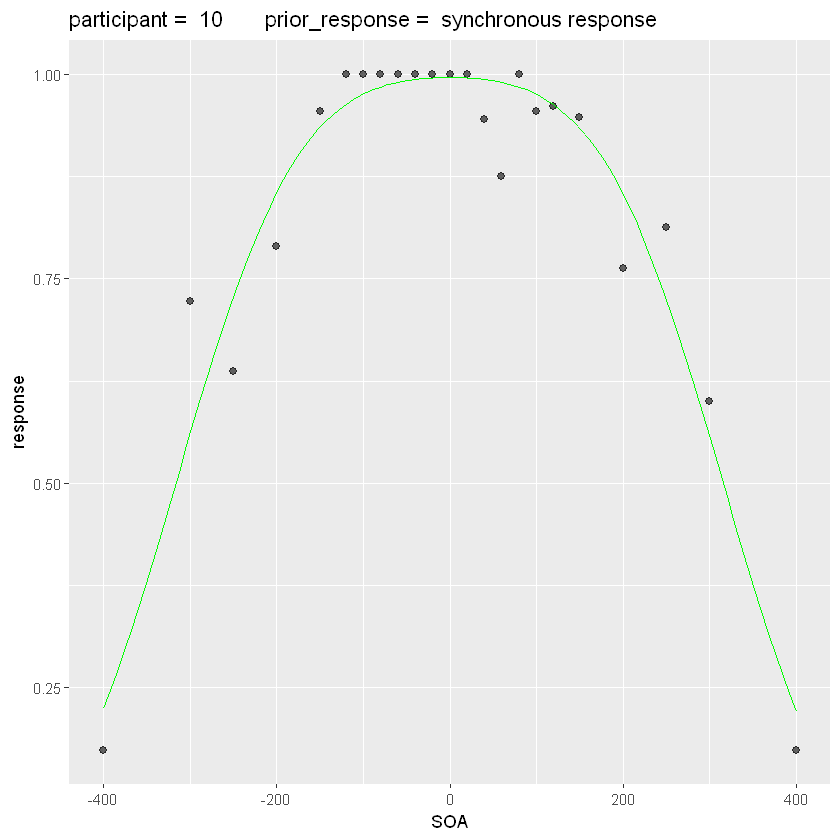

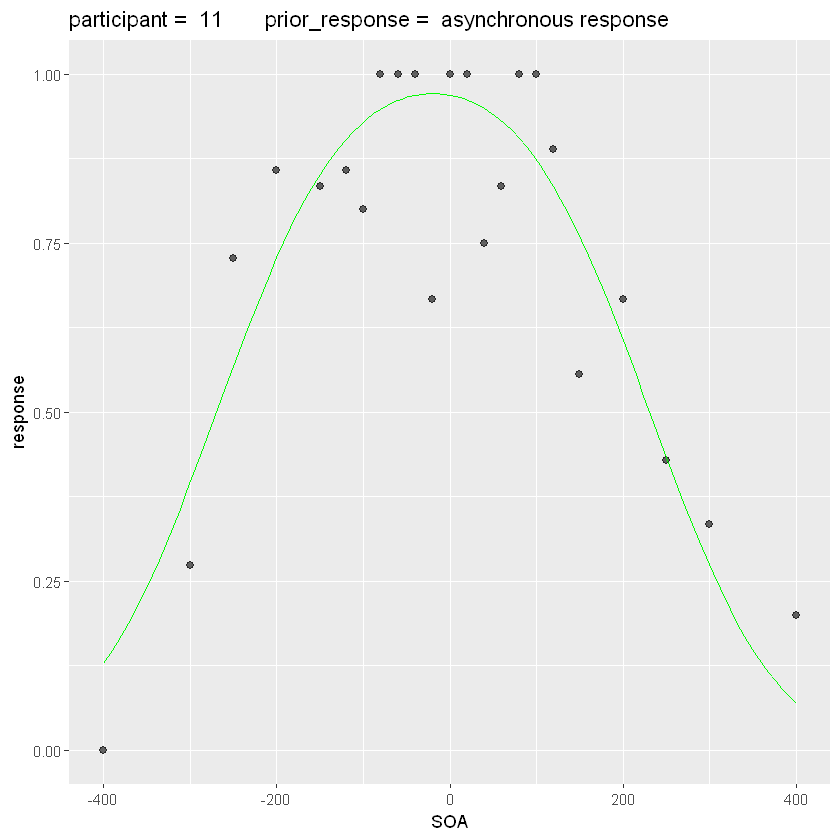

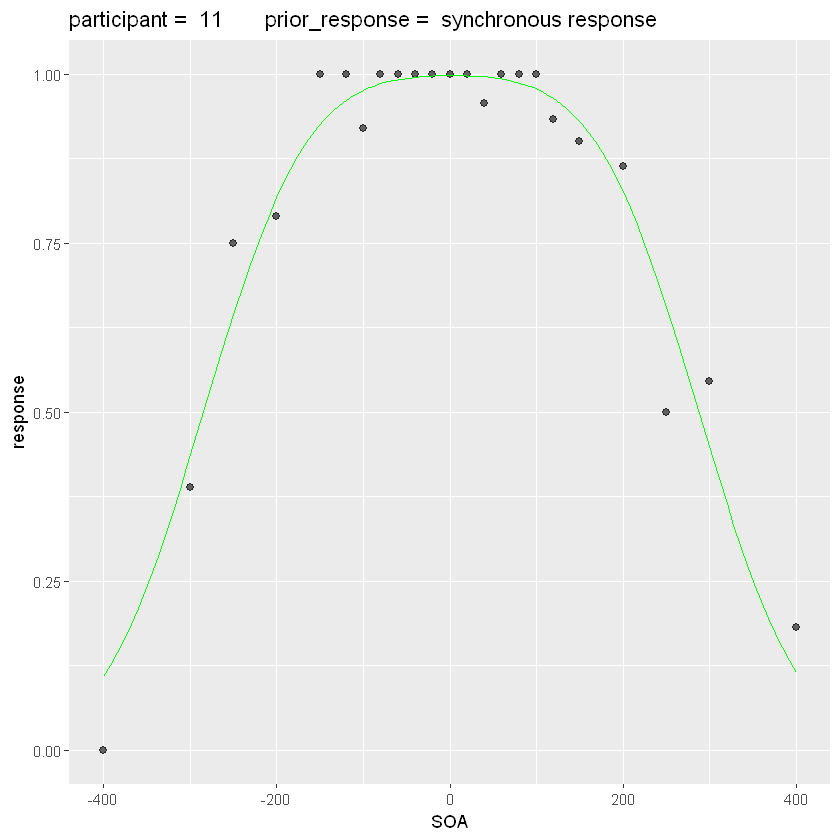

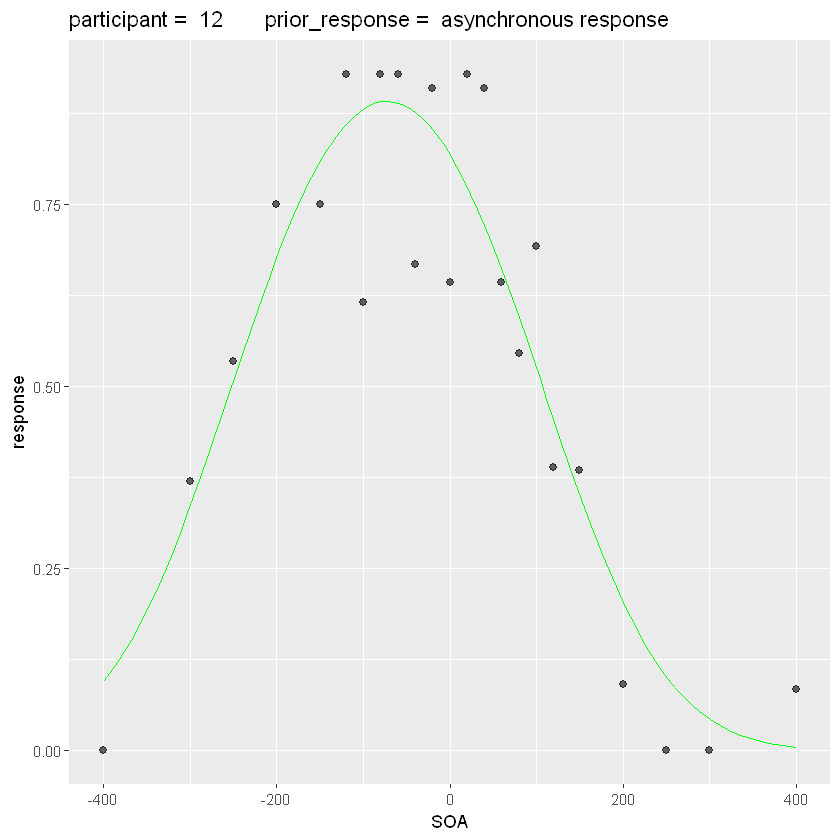

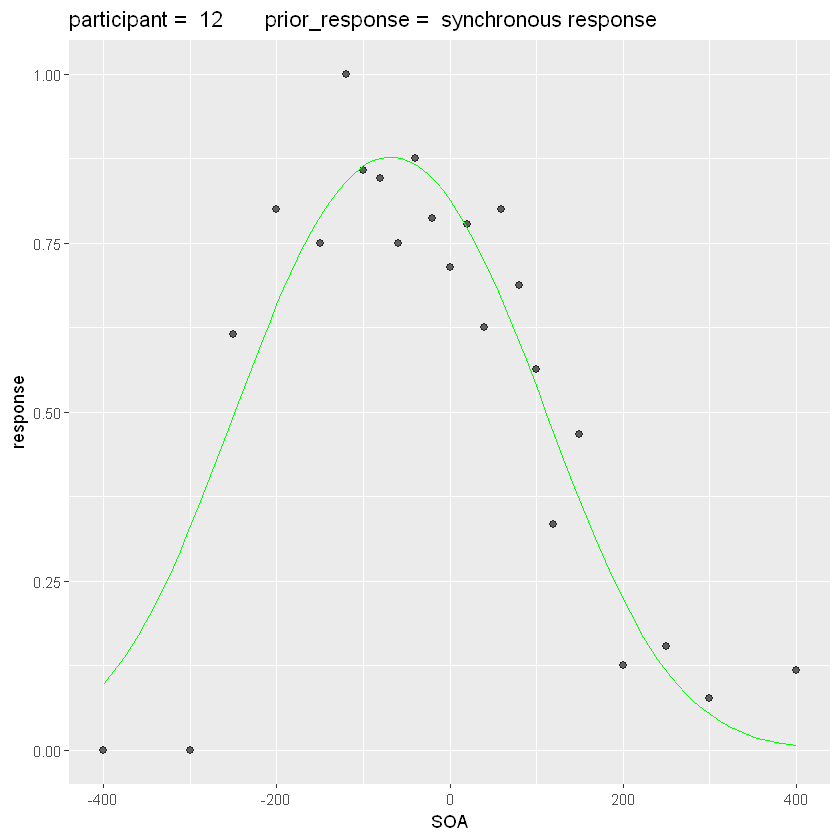

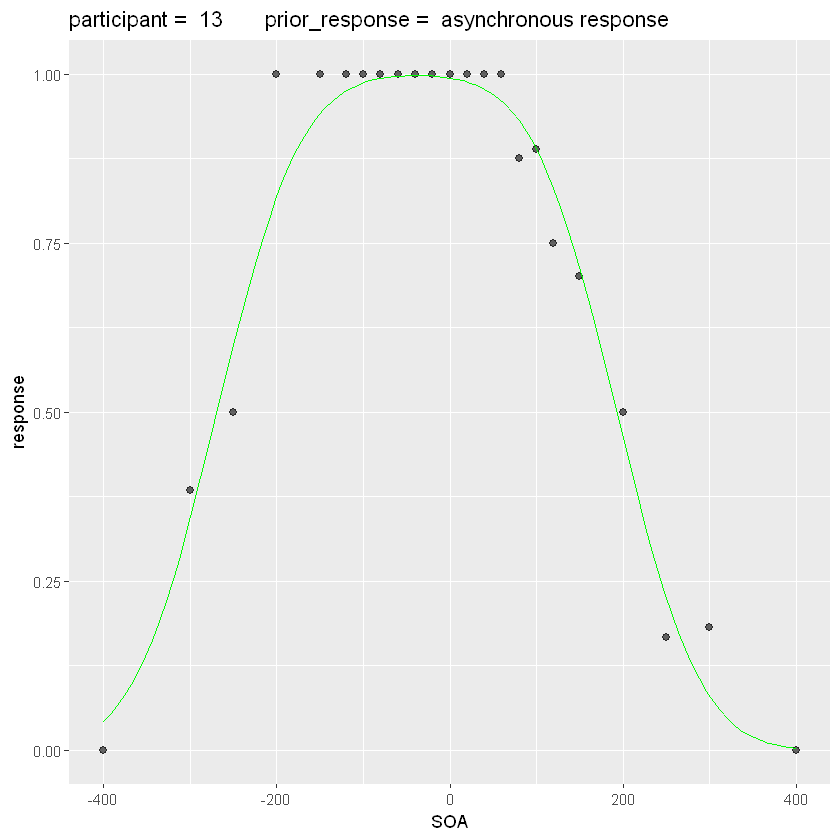

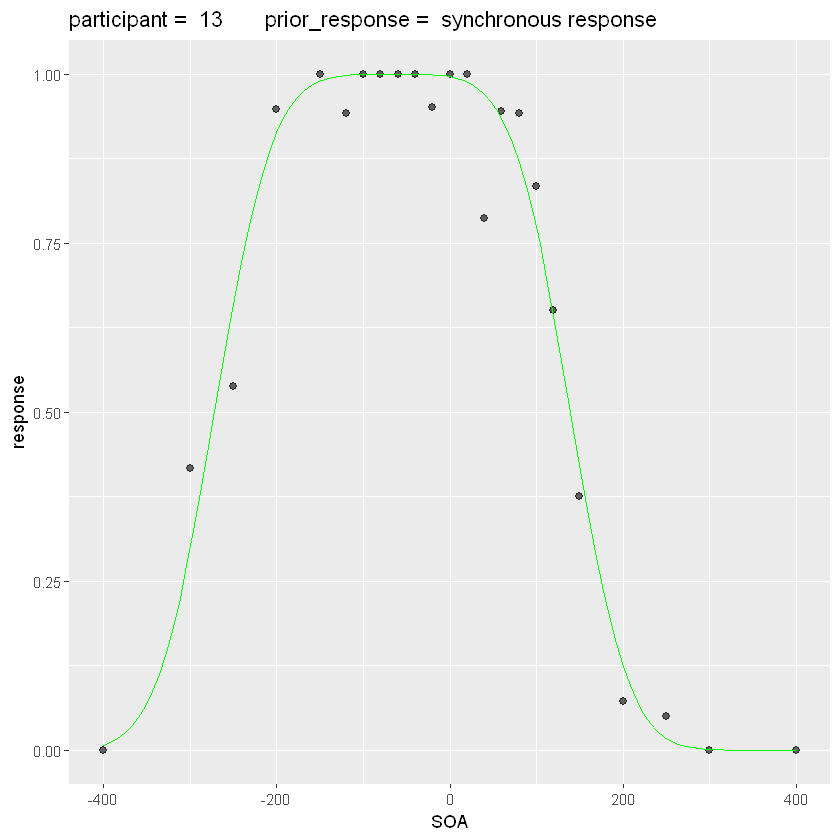

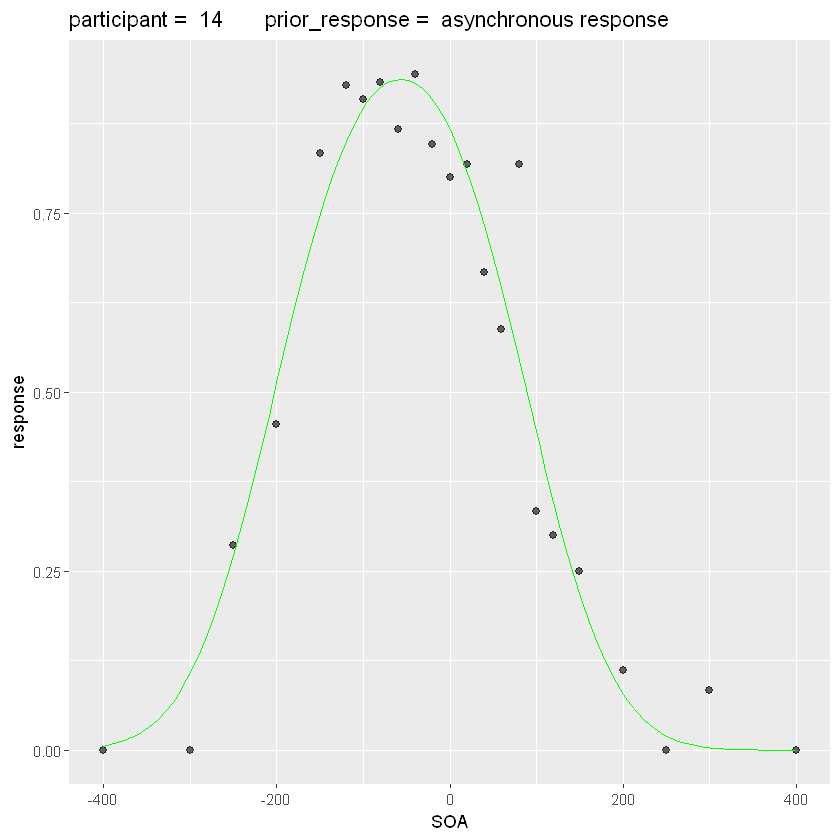

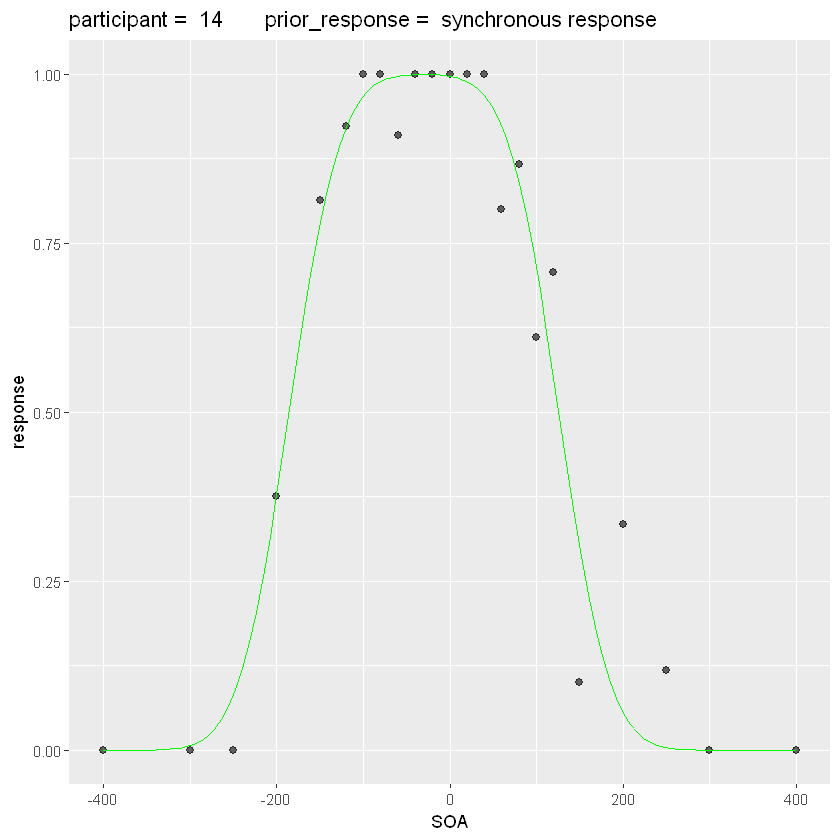

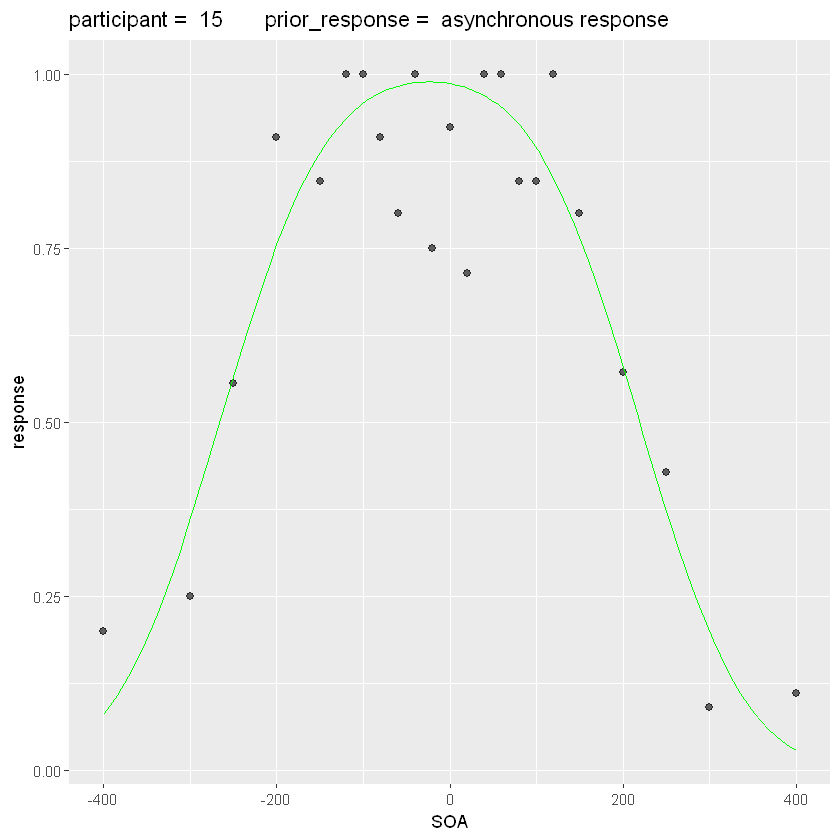

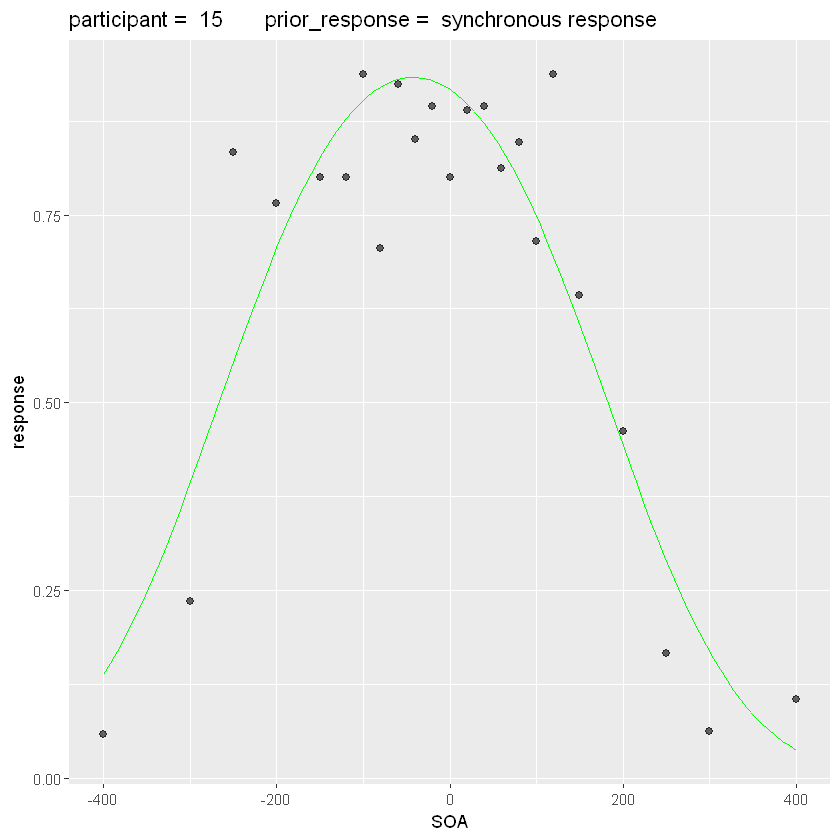

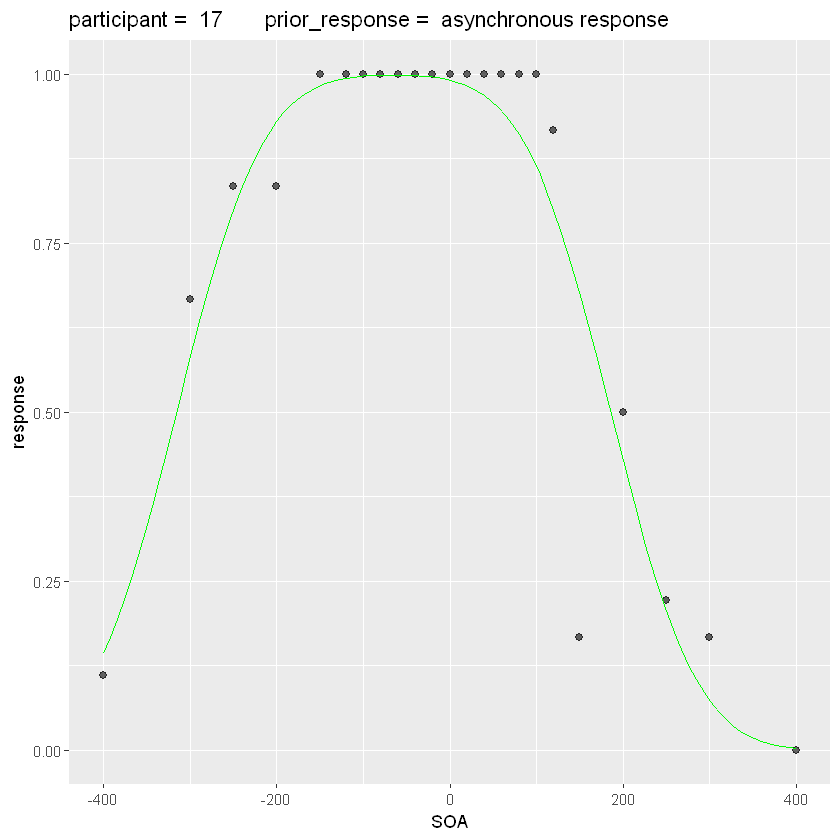

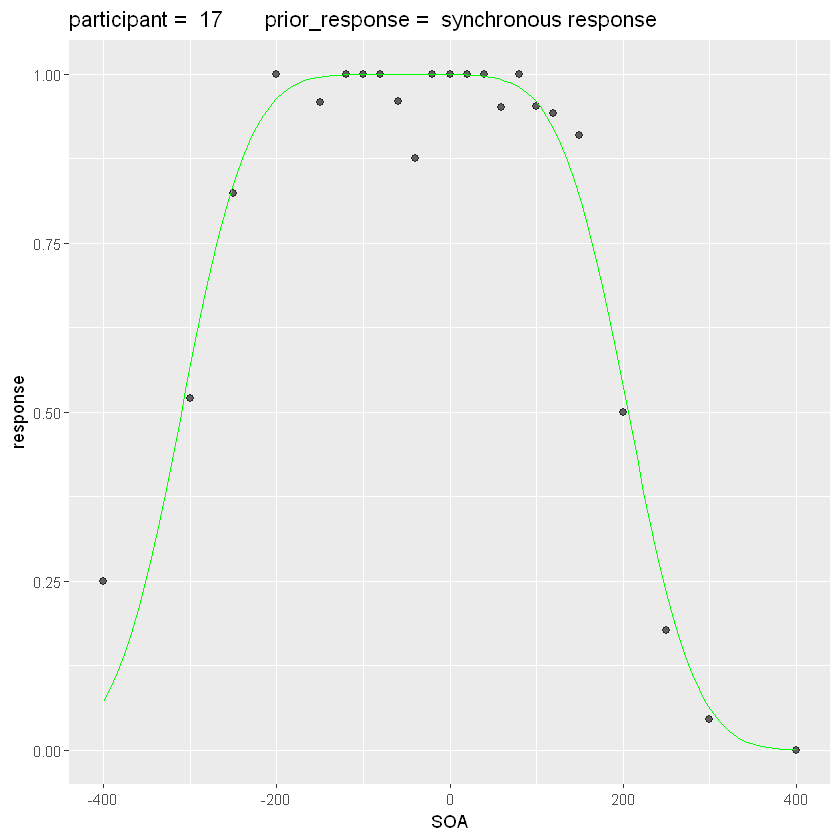

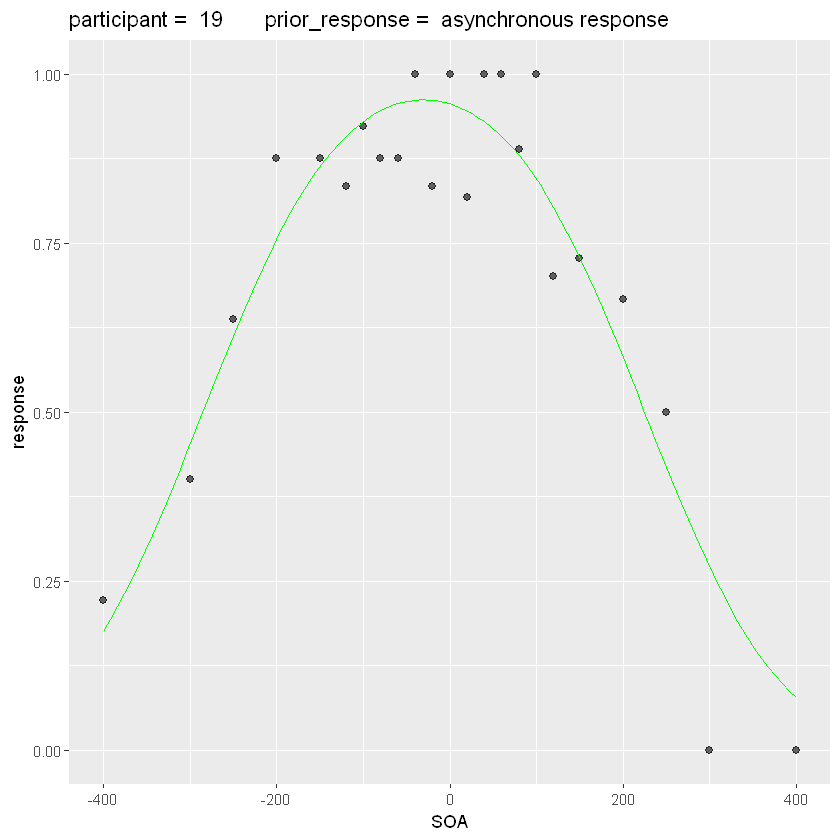

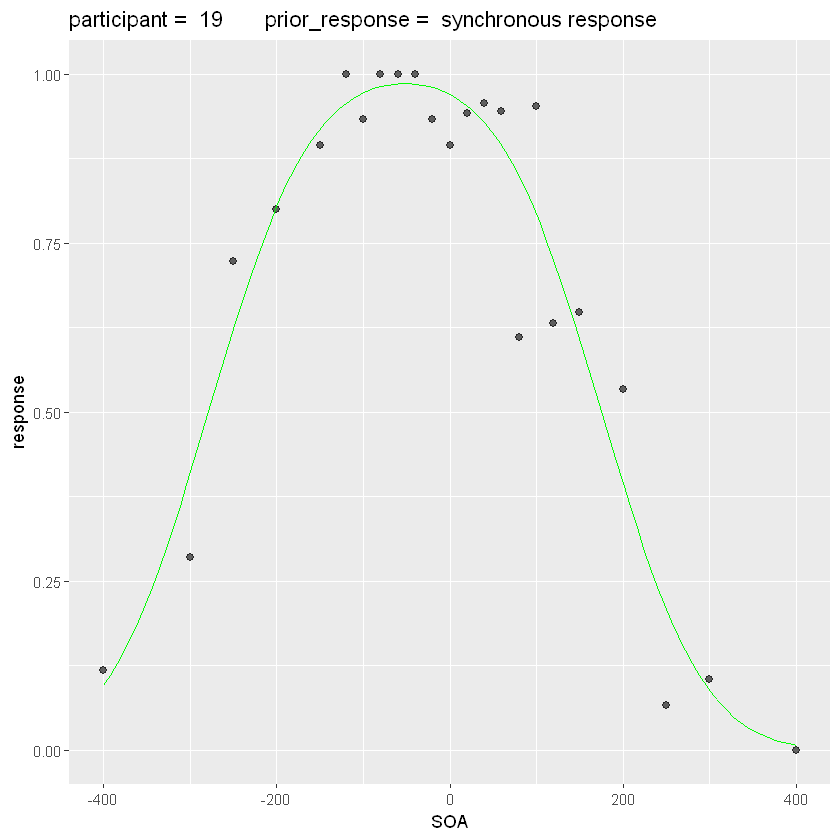

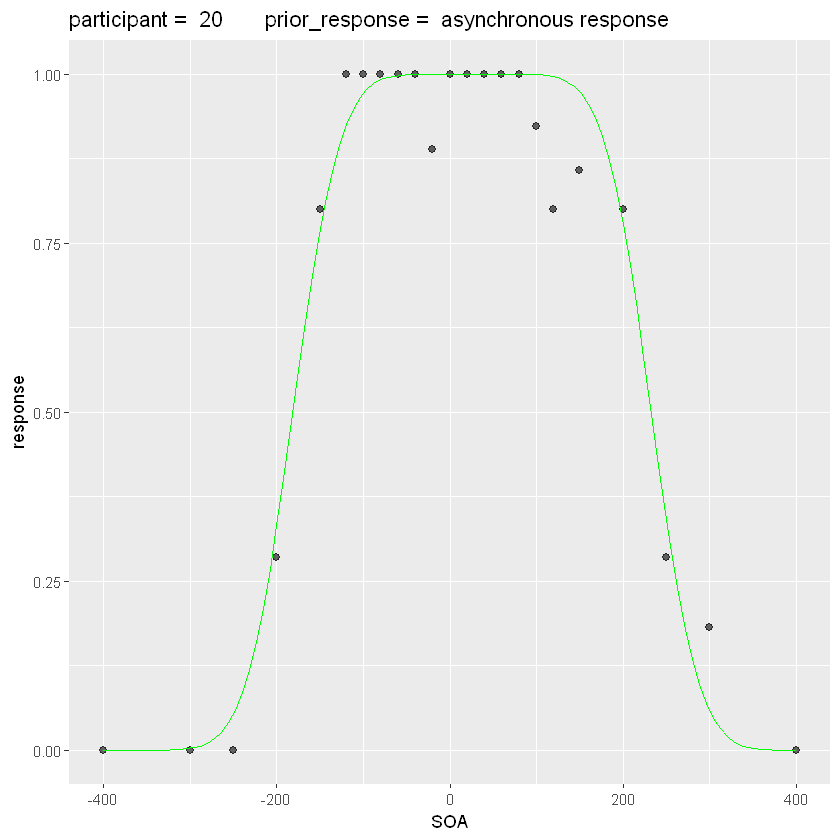

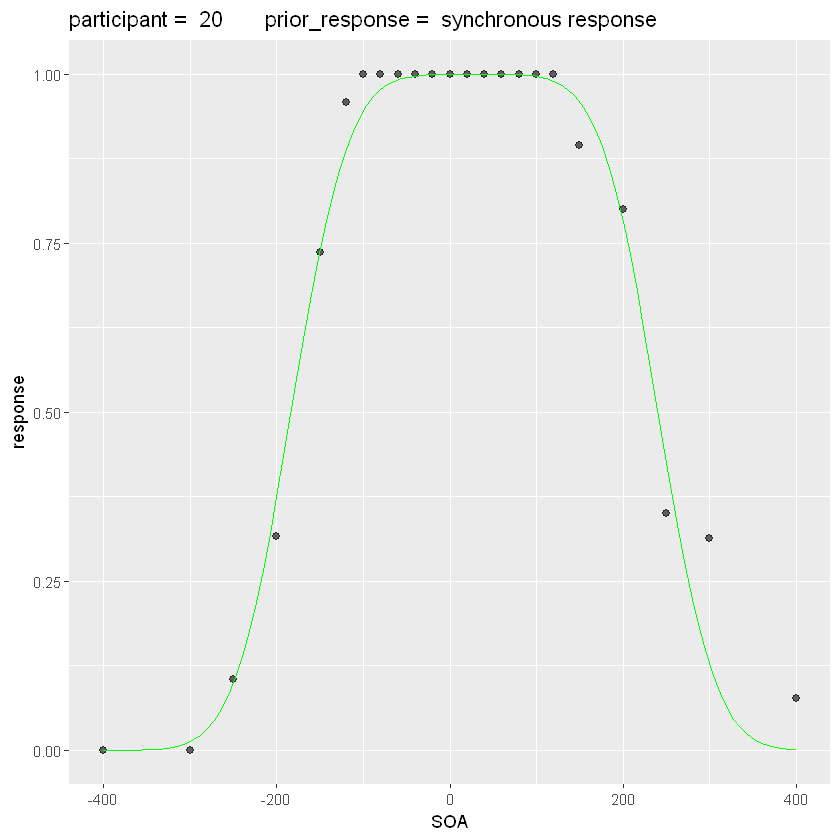

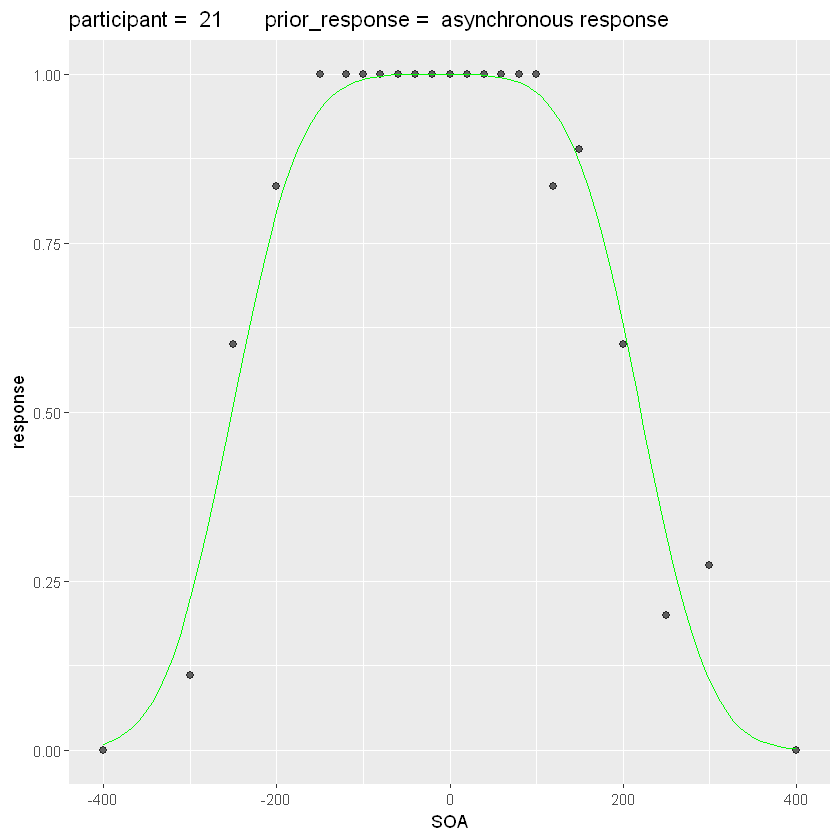

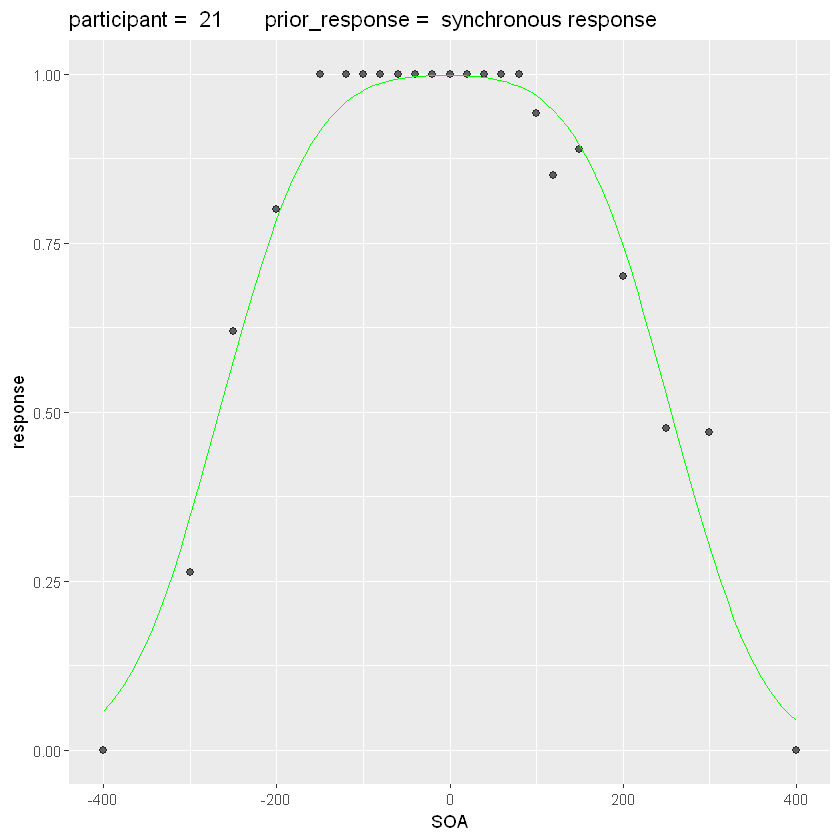

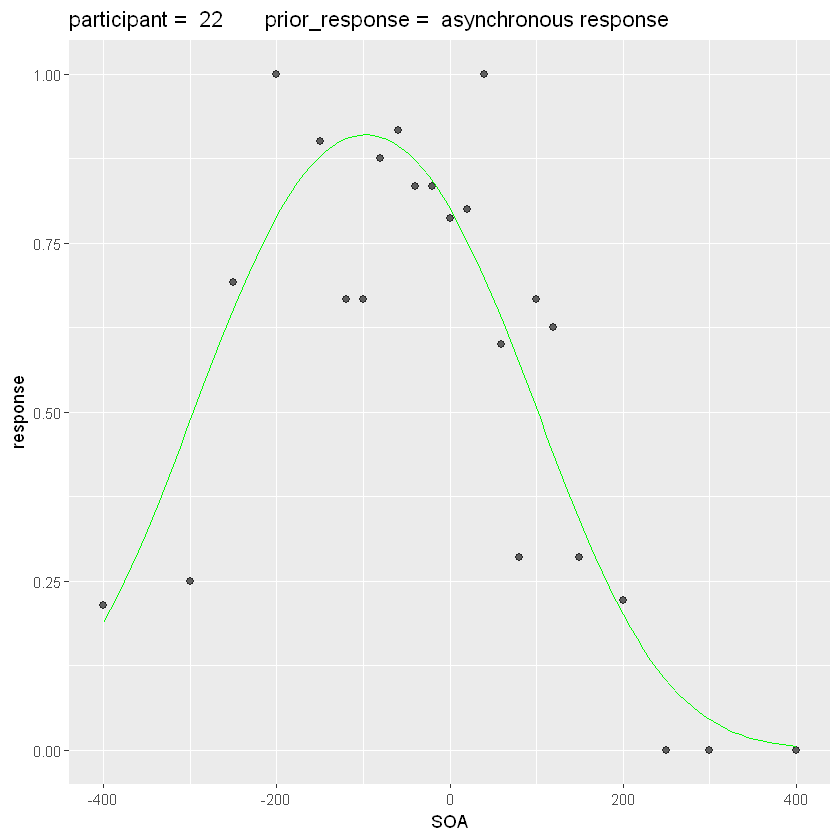

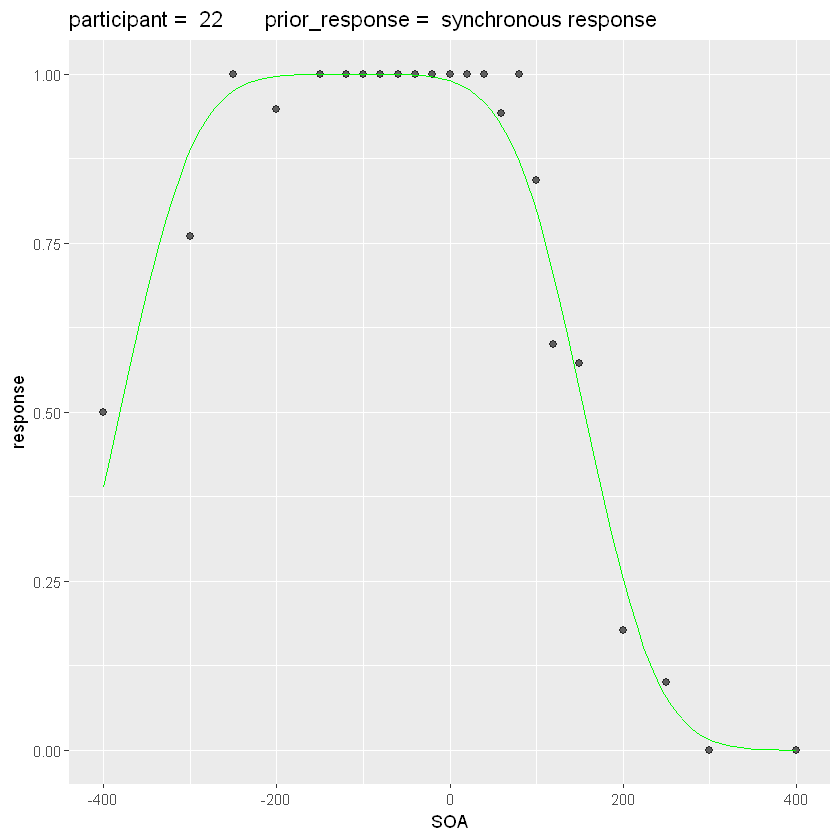

In [84]:
ff <- function(x,Clow,Chigh,sigma){
      pnorm(x, mean = Clow, sd = sigma) -
    pnorm(x, mean = Chigh, sd = sigma)
}

data_mean <- data %>% group_by(participant, prior_response, SOA) %>%   
    summarise(
                response = mean(response == 1),
                n_trials = n(),
                .groups = "drop"
              )

for(subj in unique(data$participant)){

    d1 <- data_mean %>% filter(participant == subj)
    for(pr in unique(data$prior_response)){
        d2 <- d1 %>% filter(prior_response == pr)

        Clow <- (model_results %>% filter(participant == subj) %>% filter(prior_response == pr))$Clow
        Chigh <- (model_results %>% filter(participant == subj) %>% filter(prior_response == pr))$Chigh
        sigma <- (model_results %>% filter(participant == subj) %>% filter(prior_response == pr))$sigma
        print(ggplot(d2, aes(x = SOA, y = response)) +
                geom_point(size = 2, alpha = 0.6) +
                geom_function(fun=ff, args = list(Clow = Clow, Chigh = Chigh, sigma = sigma), color='green') +
                labs(title = paste('participant = ',subj,'      prior_response = ',pr)))
            
}}

In [85]:
## Compute coefficient of determination (R²) to evaluate the goodness-of-fit of the psychometric model

R2 <- function(observed, predicted){
  SS_res <- sum((observed - predicted)^2)
  SS_tot <- sum((observed - mean(observed))^2)
  return(1 - SS_res / SS_tot)
}

model_results$R2 <- NA

for(i in 1:nrow(model_results)){
  id <- model_results$participant[i]
  pr <- model_results$prior_response[i]
  subdata <- data_mean %>% filter(participant == id) %>% filter(prior_response == pr)
  pred <- ff(subdata$SOA, model_results$Clow[i], model_results$Chigh[i], model_results$sigma[i])
  model_results$R2[i] <- R2(subdata$response, pred)
}

head(model_results)

,participant,prior_response,Clow,Chigh,sigma,PSS,R2
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,asynchronous response,-221.0305,181.79011,58.74870,-19.62018,0.9533977
2,1,synchronous response,-254.5232,189.91598,52.38215,-32.30362,0.9762434
3,3,asynchronous response,-200.5636,61.04111,133.09752,-69.76127,0.8407152
4,3,synchronous response,-184.4021,50.34115,112.80065,-67.03046,0.7613216
5,4,asynchronous response,-269.1213,32.08636,201.91210,-118.51746,0.7548057
6,4,synchronous response,-261.5051,144.31105,146.94675,-58.59705,0.8550135


In [86]:
model_results %>% arrange(R2)

participant,prior_response,Clow,Chigh,sigma,PSS,R2
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4,asynchronous response,-269.1213,32.08636,201.91210,-118.517464,0.7548057
3,synchronous response,-184.4021,50.34115,112.80065,-67.030458,0.7613216
7,asynchronous response,-262.0407,149.39389,100.88344,-56.323395,0.7774041
22,asynchronous response,-296.5851,101.59416,117.28611,-97.495489,0.8063712
11,asynchronous response,-269.7016,230.84886,114.51881,-19.426353,0.8235481
5,asynchronous response,-247.8615,234.09071,109.79730,-6.885388,0.8390358
3,asynchronous response,-200.5636,61.04111,133.09752,-69.761266,0.8407152
4,synchronous response,-261.5051,144.31105,146.94675,-58.597051,0.8550135
15,asynchronous response,-265.9684,219.12677,95.62497,-23.420824,0.8603275


In [118]:
## Save Parameter Estimates

write_xlsx(model_results, "files/SJ_prior_response_observer_parameters.xlsx")

###############################################################
## 3-4 Plot group-level fits

In [87]:
ff <- function(x,Clow,Chigh,sigma){
      pnorm(x, mean = Clow, sd = sigma) -
    pnorm(x, mean = Chigh, sd = sigma)
}

df_predicted <- data.frame()

for(subj in unique(data$participant)){
    for(pr in unique(data$prior_response)){
        Clow <- (model_results %>% filter(participant == subj) %>% filter(prior_response == pr))$Clow
        Chigh <- (model_results %>% filter(participant == subj) %>% filter(prior_response == pr))$Chigh
        sigma <- (model_results %>% filter(participant == subj) %>% filter(prior_response == pr))$sigma
        df <- data.frame(participant=subj, prior_response=pr, SOA = -400:400, response=ff(-400:400,Clow,Chigh,sigma))
        df_predicted <- rbind(df_predicted, df)
}}

In [88]:
###############################################################
# Compute observed psychometric data
###############################################################

df_summary <- data %>%
  group_by(participant, prior_response, SOA) %>%
  summarise(
    mr = mean(response),
    .groups = "drop"
  ) %>% group_by(prior_response, SOA) %>%
  summarise(
    mean_response = mean(mr),
    se = sd(mr) / sqrt(n()),
    .groups = "drop"
  )

df_predicted_summary <- df_predicted %>%
  group_by(prior_response, SOA) %>%
  summarise(
    mean_response = mean(response),
    se = sd(response) / sqrt(n()),
    .groups = "drop"
  )

png 
  2

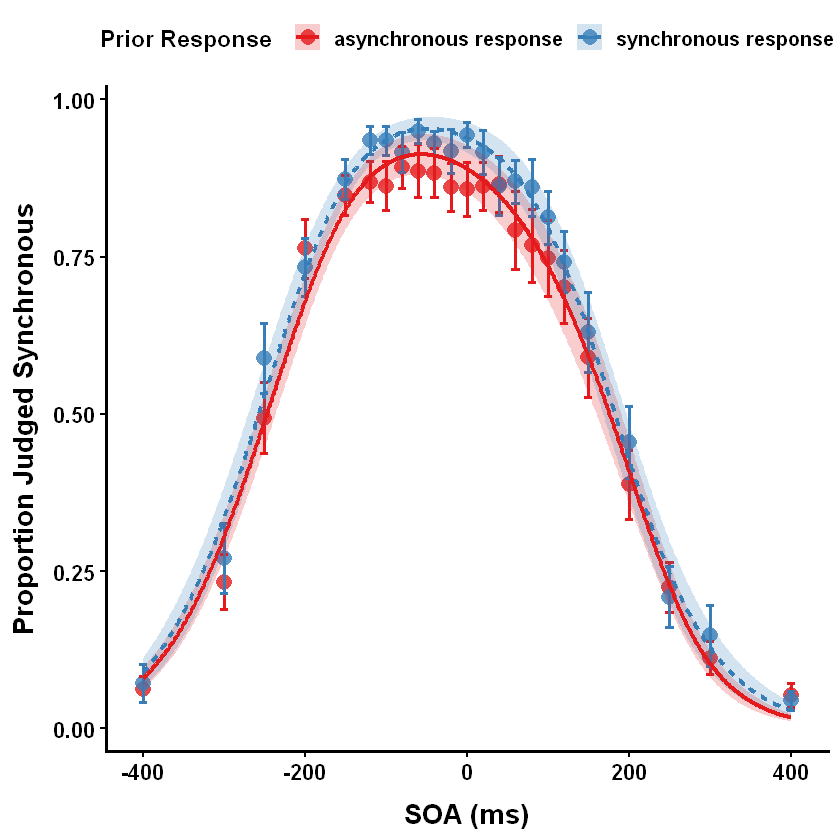

In [21]:
# =========================================================
# Visualize observed TOJ responses and fitted psychometric
# curves as a function of SOA and prior stimulus condition.
# =========================================================

pdf(file="figures/SJ_prior_response_observer_response.pdf", width = 10, height = 8)

p_sj_prior_resp <- ggplot() +
  # Plot observed data points
  geom_point(
    data = df_summary,
    aes(x = SOA, y = mean_response, color = prior_response),
    alpha = 0.8,
    size = 4,
    shape = 16
  ) +


  # Add error bars for observed data
  geom_errorbar(
    data = df_summary,
    aes(
      x = SOA,
      ymin = mean_response - se,
      ymax = mean_response + se,
      color = prior_response
    ),
    width = 10,
    linewidth = 1
  ) +


  # Add shaded ribbon around fitted values
  geom_ribbon(
    data = df_predicted_summary,
    aes(
      x = SOA,
      ymin = mean_response - se,
      ymax = mean_response + se,
      fill = prior_response,
      group = prior_response
    ),
    alpha = 0.22,
    color = NA
  ) +

  # Plot fitted curves
  geom_line(
    data = df_predicted_summary,
    aes(
      x = SOA,
      y = mean_response,
      color = prior_response,
      linetype = prior_response,
      group = prior_response
    ),
    linewidth = 1.2
  ) +

  # Define labels
  labs(
    x = "SOA (ms)",
    y = "Proportion Judged Synchronous",
    color = "Prior Response",
    linetype = "Prior Response",
    fill = "Prior Response"
  ) +

  # Use a clean theme consistent with previous figures
  theme_classic(base_size = 14) +
  theme(
    axis.title.x = element_text(face = "bold", size = 16, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 16, margin = margin(r = 10)),
    axis.text.x = element_text(face = "bold", size = 13, color = "black"),
    axis.text.y = element_text(face = "bold", size = 13, color = "black"),
    legend.title = element_text(face = "bold", size = 14),
    legend.text = element_text(face = "bold", size = 12),
    legend.position = "top",
    axis.line = element_line(linewidth = 1)
  ) +

  # Use the same color palette as the other figures
  scale_color_brewer(palette = "Set1") +
  scale_fill_brewer(palette = "Set1")
p_sj_prior_resp
dev.off()
# Display the plot
print(p_sj_prior_resp)

###############################################################
## 3-5 Statistical test of sigma

In [89]:
psy_results <- read_xlsx("files/SJ_prior_response_observer_parameters.xlsx")
head(psy_results)

participant,prior_response,Clow,Chigh,sigma,PSS,delta_c
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,asynchronous response,-221.0305,181.79011,58.74870,-19.62018,402.8206
1,synchronous response,-254.5232,189.91598,52.38215,-32.30362,444.4392
3,asynchronous response,-200.5636,61.04111,133.09752,-69.76126,261.6047
3,synchronous response,-184.4021,50.34115,112.80065,-67.03046,234.7432
4,asynchronous response,-269.1213,32.08636,201.91210,-118.51746,301.2077
4,synchronous response,-261.5051,144.31105,146.94675,-58.59705,405.8162


In [90]:
psy_results2 <- psy_results %>% group_by(participant) %>% summarise(
    diff = sigma[prior_response == "synchronous response"] - sigma[prior_response == "asynchronous response"],
    .groups = "drop"
  )
head(psy_results2)

participant,diff
<dbl>,<dbl>
1,-6.366546
3,-20.296876
4,-54.965351
5,-14.382555
7,7.323766
8,-21.307317


In [91]:
#summary
psy_results %>% group_by(prior_response) %>%  get_summary_stats(sigma)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
asynchronous response,sigma,18,42.689,201.912,98.254,71.190,116.594,45.404,32.205,98.013,36.650,8.639,18.226
synchronous response,sigma,18,46.372,146.947,92.927,54.863,109.565,54.702,36.896,86.900,29.938,7.057,14.888


In [92]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-54.965,40.471,-17.656,-22.86,6.628,29.488,20.404,-11.113,25.471,6.003,12.666


In [93]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

participant,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [94]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")

In [95]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9638936,0.6781576


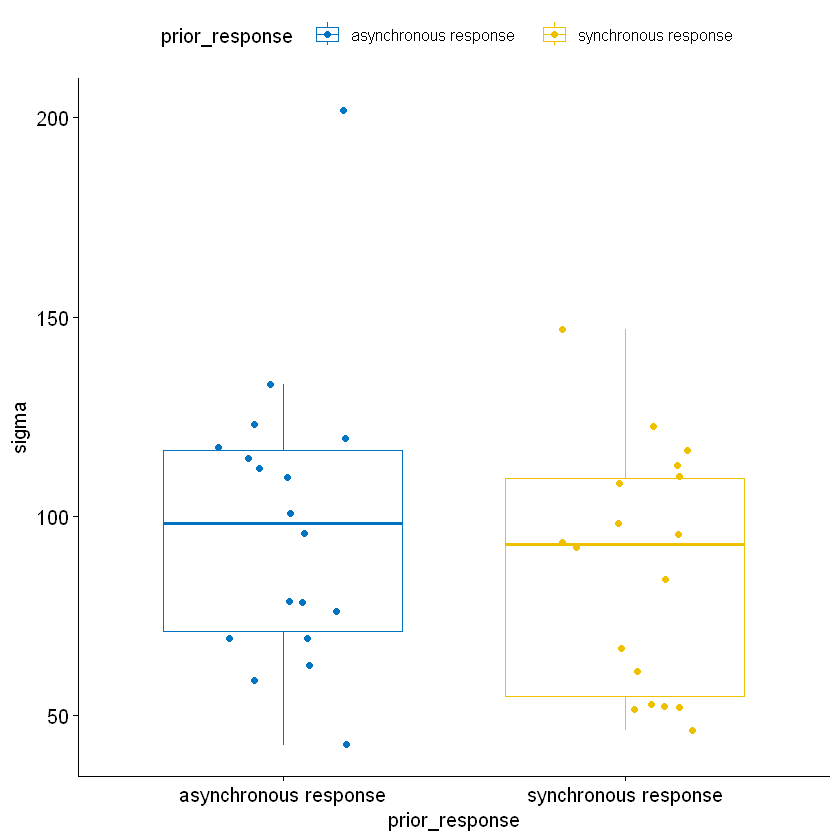

In [96]:
#plot
ggboxplot(
  psy_results, x = "prior_response", y = "sigma",
  color = "prior_response", palette = "jco", add = "jitter"
  )

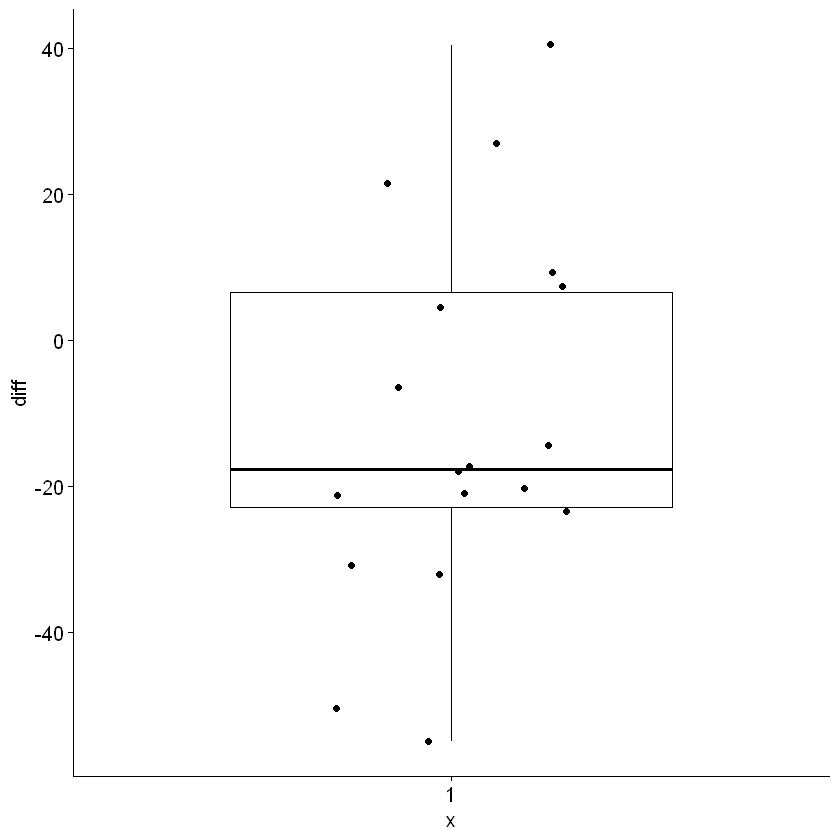

In [97]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [98]:
psy_results %>% t_test(sigma ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,11.11258,sigma,asynchronous response,synchronous response,18,18,1.851029,0.0816,17,-1.553614,23.77877,T-test,two.sided


In [99]:
psy_results %>% cohens_d(sigma ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,sigma,asynchronous response,synchronous response,0.4362918,18,18,small


###############################################################
## 3-6 Statistical test of Criterion_Low

In [100]:
psy_results <- read_xlsx("files/SJ_prior_response_observer_parameters.xlsx")
head(psy_results)

participant,prior_response,Clow,Chigh,sigma,PSS,delta_c
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,asynchronous response,-221.0305,181.79011,58.74870,-19.62018,402.8206
1,synchronous response,-254.5232,189.91598,52.38215,-32.30362,444.4392
3,asynchronous response,-200.5636,61.04111,133.09752,-69.76126,261.6047
3,synchronous response,-184.4021,50.34115,112.80065,-67.03046,234.7432
4,asynchronous response,-269.1213,32.08636,201.91210,-118.51746,301.2077
4,synchronous response,-261.5051,144.31105,146.94675,-58.59705,405.8162


In [101]:
psy_results2 <- psy_results %>% group_by(participant) %>% summarise(
    diff = Clow[prior_response == "synchronous response"] - Clow[prior_response == "asynchronous response"],
    .groups = "drop"
  )
head(psy_results2)

participant,diff
<dbl>,<dbl>
1,-33.492756
3,16.161578
4,7.616140
5,6.996402
7,-9.589353
8,-54.400111


In [102]:
#summary
psy_results %>% group_by(prior_response) %>%  get_summary_stats(Clow)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
asynchronous response,Clow,18,-316.034,-179.063,-262.576,-269.586,-227.738,41.848,22.822,-250.731,38.776,9.140,19.283
synchronous response,Clow,18,-381.066,-183.468,-264.034,-277.347,-241.113,36.234,31.750,-260.212,48.754,11.491,24.245


In [103]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-84.481,36.79,-1.497,-14.872,6.859,21.731,16.419,-9.482,29.826,7.03,14.832


In [104]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

participant,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>
8,-54.40011,TRUE,FALSE
10,-53.68211,TRUE,FALSE
22,-84.48136,TRUE,TRUE


In [105]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")

In [106]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9122555,0.1092133


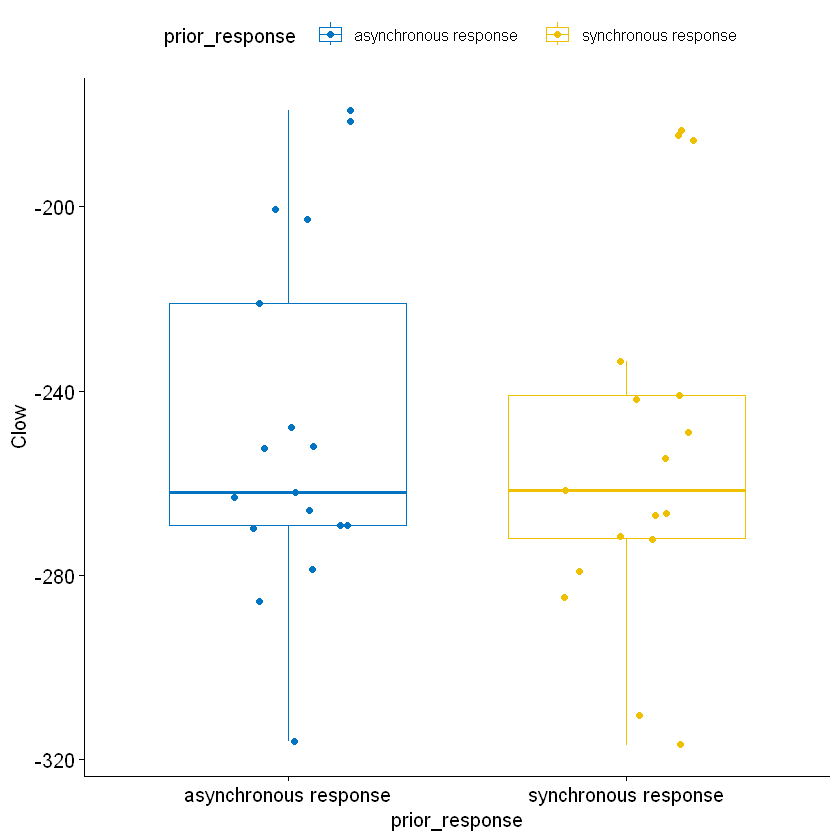

In [107]:
#plot
ggboxplot(
  psy_results, x = "prior_response", y = "Clow",
  color = "prior_response", palette = "jco", add = "jitter"
  )

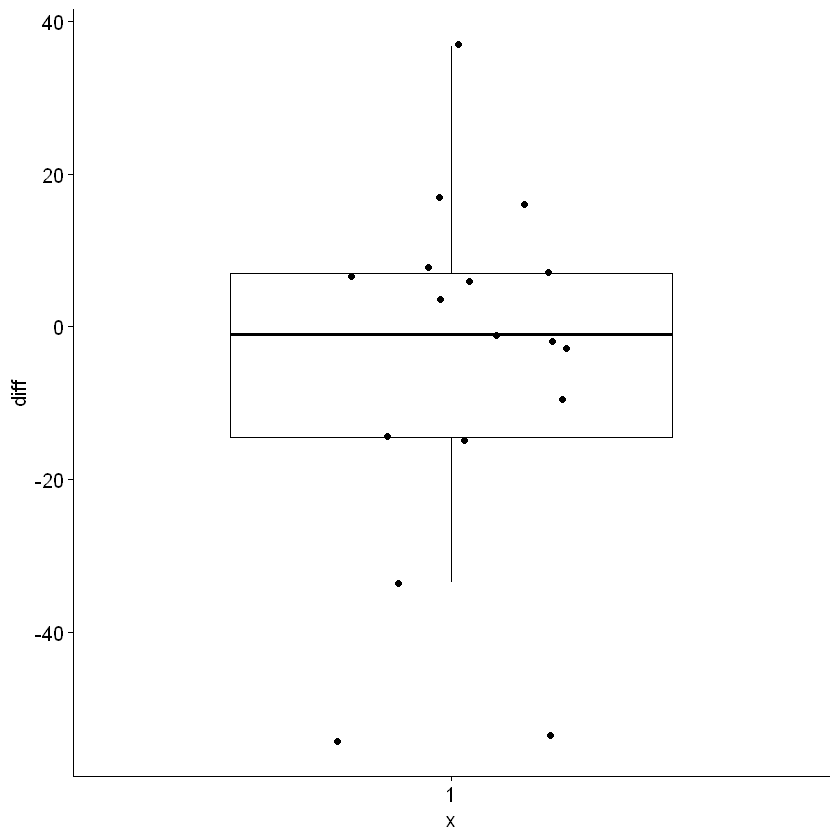

In [108]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [109]:
psy_results %>% t_test(Clow ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,5.070181,Clow,asynchronous response,synchronous response,17,17,0.8733698,0.395,16,-7.236522,17.37688,T-test,two.sided


In [110]:
psy_results %>% cohens_d(Clow ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,Clow,asynchronous response,synchronous response,0.2118233,17,17,small


In [111]:
wilcox.test(psy_results$Clow[psy_results$prior_response=='synchronous response'], psy_results$Clow[psy_results$prior_response=='asynchronous response'], paired = TRUE, conf.int = TRUE)


	Wilcoxon signed rank exact test

data:  psy_results$Clow[psy_results$prior_response == "synchronous response"] and psy_results$Clow[psy_results$prior_response == "asynchronous response"]
V = 70, p-value = 0.7819
alternative hypothesis: true location shift is not equal to 0
95 percent confidence interval:
 -18.299561   7.031129
sample estimates:
(pseudo)median 
     -1.933876 


###############################################################
## 3-7 Statistical test of Criterion_High

In [112]:
psy_results <- read_xlsx("files/SJ_prior_response_observer_parameters.xlsx")
head(psy_results)

participant,prior_response,Clow,Chigh,sigma,PSS,delta_c
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,asynchronous response,-221.0305,181.79011,58.74870,-19.62018,402.8206
1,synchronous response,-254.5232,189.91598,52.38215,-32.30362,444.4392
3,asynchronous response,-200.5636,61.04111,133.09752,-69.76126,261.6047
3,synchronous response,-184.4021,50.34115,112.80065,-67.03046,234.7432
4,asynchronous response,-269.1213,32.08636,201.91210,-118.51746,301.2077
4,synchronous response,-261.5051,144.31105,146.94675,-58.59705,405.8162


In [113]:
psy_results2 <- psy_results %>% group_by(participant) %>% summarise(
    diff = Chigh[prior_response == "synchronous response"] - Chigh[prior_response == "asynchronous response"],
    .groups = "drop"
  )
head(psy_results2)

participant,diff
<dbl>,<dbl>
1,8.125869
3,-10.699960
4,112.224684
5,-28.423294
7,13.996979
8,61.396205


In [114]:
#summary
psy_results %>% group_by(prior_response) %>%  get_summary_stats(Chigh)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
asynchronous response,Chigh,18,32.086,234.091,183.769,102.956,223.832,120.876,71.156,163.608,68.161,16.066,33.896
synchronous response,Chigh,18,50.341,315.631,178.767,140.528,205.651,65.123,54.825,182.232,64.537,15.212,32.093


In [115]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-53.543,112.225,16.925,-6.963,49.605,56.568,47.827,18.624,44.981,10.602,22.369


In [116]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

participant,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>


In [117]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")

In [118]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9778168,0.9247262


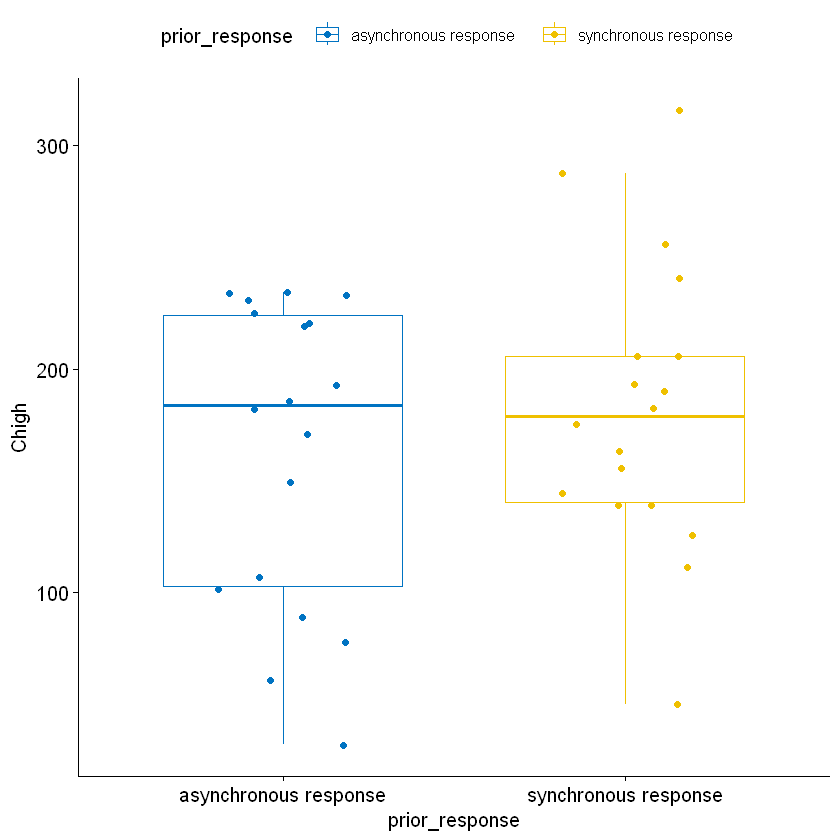

In [119]:
#plot
ggboxplot(
  psy_results, x = "prior_response", y = "Chigh",
  color = "prior_response", palette = "jco", add = "jitter"
  )

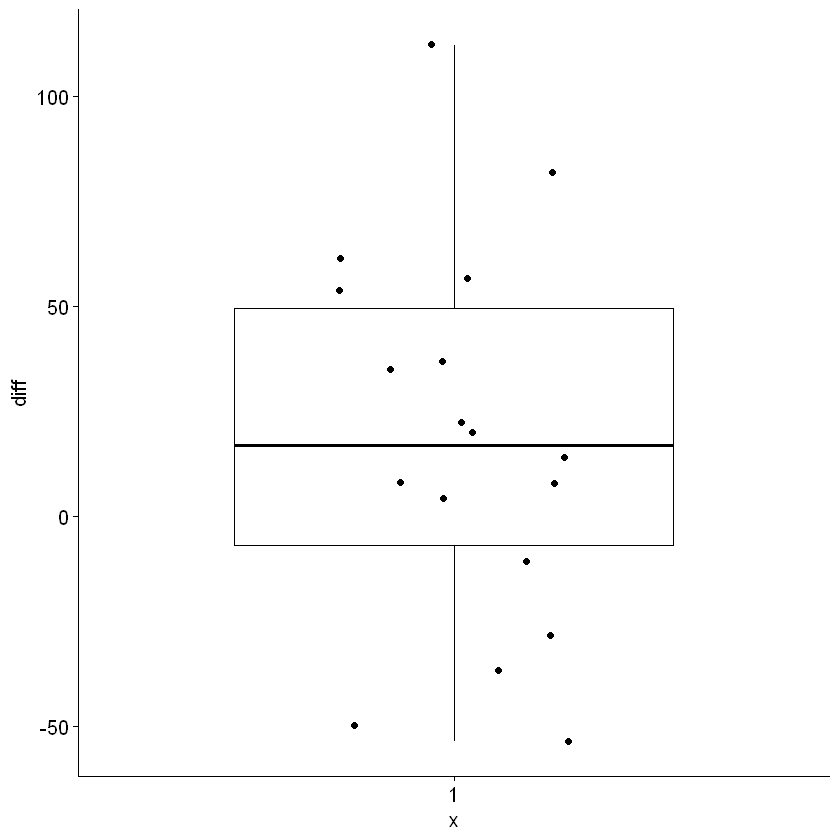

In [120]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [121]:
psy_results %>% t_test(Chigh ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-18.62402,Chigh,asynchronous response,synchronous response,18,18,-1.756632,0.097,17,-40.99253,3.744497,T-test,two.sided


In [122]:
psy_results %>% cohens_d(Chigh ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,Chigh,asynchronous response,synchronous response,-0.4140421,18,18,small


###############################################################
## 3-8 Statistical test of PSS

In [123]:
psy_results <- read_xlsx("files/SJ_prior_response_observer_parameters.xlsx")
head(psy_results)

participant,prior_response,Clow,Chigh,sigma,PSS,delta_c
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,asynchronous response,-221.0305,181.79011,58.74870,-19.62018,402.8206
1,synchronous response,-254.5232,189.91598,52.38215,-32.30362,444.4392
3,asynchronous response,-200.5636,61.04111,133.09752,-69.76126,261.6047
3,synchronous response,-184.4021,50.34115,112.80065,-67.03046,234.7432
4,asynchronous response,-269.1213,32.08636,201.91210,-118.51746,301.2077
4,synchronous response,-261.5051,144.31105,146.94675,-58.59705,405.8162


In [124]:
psy_results2 <- psy_results %>% group_by(participant) %>% summarise(
    diff = PSS[prior_response == "synchronous response"] - PSS[prior_response == "asynchronous response"],
    .groups = "drop"
  )
head(psy_results2)

participant,diff
<dbl>,<dbl>
1,-12.683443
3,2.730809
4,59.920412
5,-10.713446
7,2.203813
8,3.498047


In [125]:
#summary
psy_results %>% group_by(prior_response) %>%  get_summary_stats(PSS)

prior_response,variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
asynchronous response,PSS,18,-118.517,25.620,-44.419,-63.093,-19.475,43.619,36.911,-43.561,34.750,8.191,17.281
synchronous response,PSS,18,-112.827,28.462,-44.682,-57.478,-19.291,38.187,31.186,-38.990,32.988,7.775,16.405


In [126]:
psy_results2 %>% get_summary_stats(diff)

variable,n,min,max,median,q1,q3,iqr,mad,mean,sd,se,ci
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
diff,18,-28.192,59.92,3.17,-12.191,13.762,25.953,22.044,4.571,21.56,5.082,10.721


In [127]:
#identify outlier
dd <- psy_results2 %>% 
  identify_outliers(diff)
dd

participant,diff,is.outlier,is.extreme
<dbl>,<dbl>,<lgl>,<lgl>
4,59.92041,TRUE,FALSE


In [128]:
#Removing outliers data
psy_results <- psy_results %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")
psy_results2 <- psy_results2 %>%  anti_join(dd[which(dd$is.extreme == TRUE),], by = "participant")

In [133]:
# normality
psy_results2 %>% 
  shapiro_test(diff)

variable,statistic,p
<chr>,<dbl>,<dbl>
diff,0.9484738,0.40158


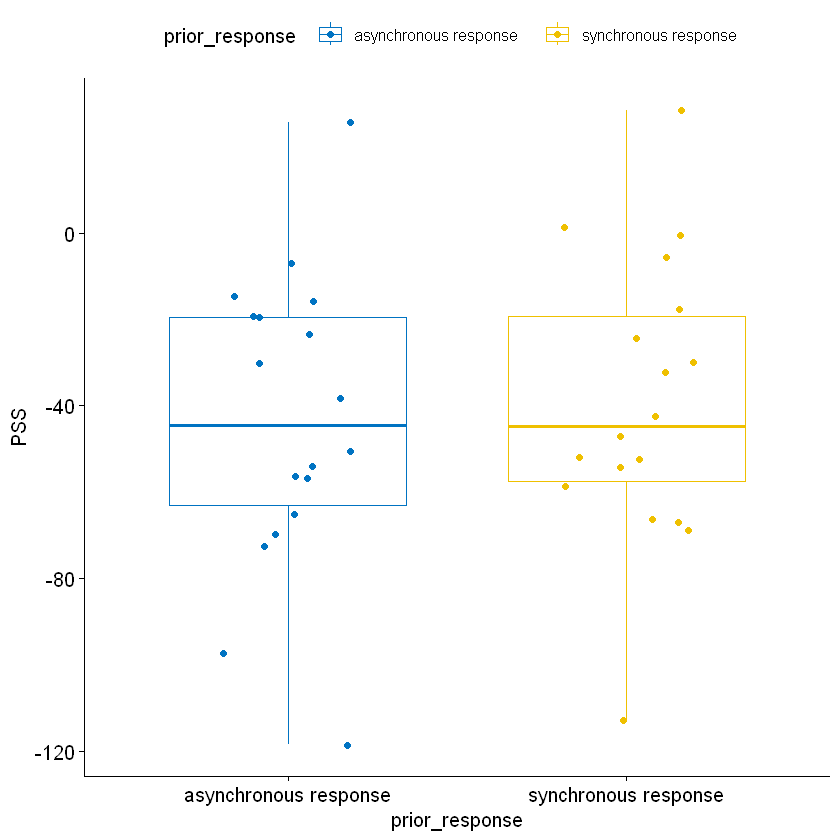

In [134]:
#plot
ggboxplot(
  psy_results, x = "prior_response", y = "PSS",
  color = "prior_response", palette = "jco", add = "jitter"
  )

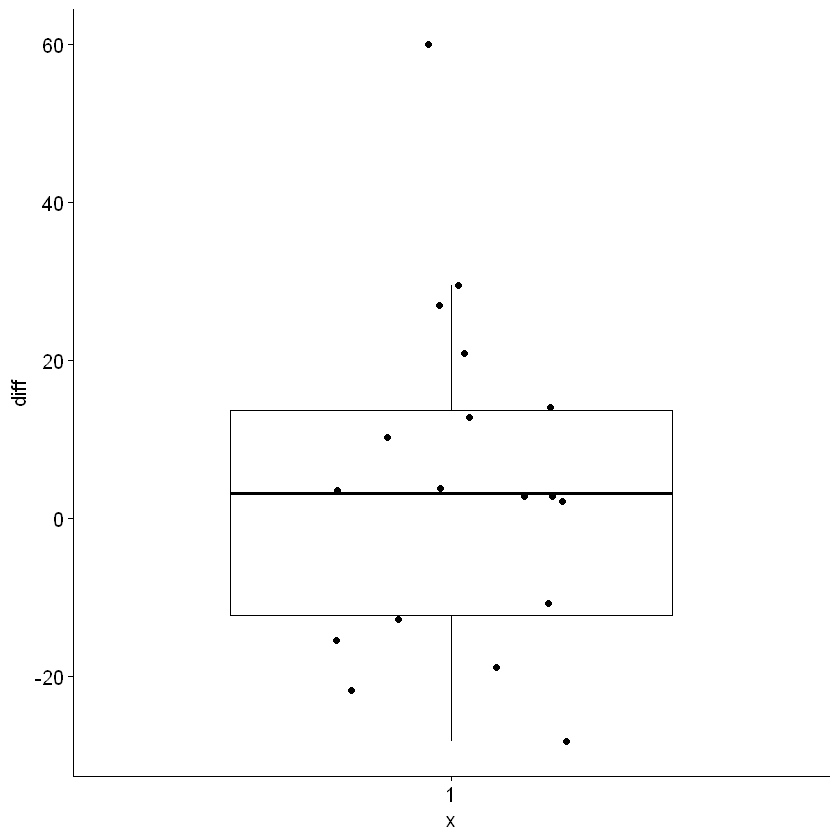

In [135]:
ggboxplot(
  psy_results2, y = "diff", palette = "jco", add = "jitter"
  )

In [136]:
psy_results %>% t_test(PSS ~ prior_response, paired=TRUE, detailed=TRUE)

,estimate,.y.,group1,group2,n1,n2,statistic,p,df,conf.low,conf.high,method,alternative
,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
mean difference,-4.571051,PSS,asynchronous response,synchronous response,18,18,-0.8995209,0.381,17,-15.2924,6.150295,T-test,two.sided


In [137]:
psy_results %>% cohens_d(PSS ~ prior_response, paired = TRUE)

,.y.,group1,group2,effsize,n1,n2,magnitude
,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<ord>
Cohen's d,PSS,asynchronous response,synchronous response,-0.2120191,18,18,small


###############################################################\
###############################################################
# 4- Visualizing Serial Dependence Statistical Results

In [139]:
prior_stimulus_psy_results <- read_xlsx("files/SJ_prior_stimulus_observer_parameters.xlsx")
prior_response_psy_results <- read_xlsx("files/SJ_prior_response_observer_parameters.xlsx")

# =========================================================
# Convert observer model results to long format
# =========================================================

stimulus_long <- prior_stimulus_psy_results %>%
  pivot_longer(
    cols = c(sigma, Clow, Chigh, PSS),
    names_to = "parameter",
    values_to = "value"
  ) %>%
  mutate(
    trial_leading = "prior_stimulus",
    type = prior_stimulus
  ) %>%
  select(participant, trial_leading, type, parameter, value)

response_long <- prior_response_psy_results %>%
  pivot_longer(
    cols = c(sigma, Clow, Chigh, PSS),
    names_to = "parameter",
    values_to = "value"
  ) %>%
  mutate(
    trial_leading = "prior_response",
    type = prior_response
  ) %>%
  select(participant, trial_leading, type, parameter, value)

# =========================================================
# Combine stimulus-driven and response-driven recalibration
# =========================================================

combined_results <- bind_rows(
  stimulus_long,
  response_long
) %>%
  arrange(participant, trial_leading, type, parameter)

In [143]:
combined_results <- combined_results %>%
  mutate(
    type = recode(type,
      "auditory_leading"="auditory leading",
      'visual_leading'='visual leading'
    ),
    trial_leading = recode(trial_leading,
      "prior_stimulus" = "Prior stimulus",
      "prior_response" = "Prior response"
    ),
    parameter = recode(parameter,
      "sigma" = "sigma",
      "Clow" = "C[low]",
      "Chigh" = "C[high]",
      "PSS" = "PSS"
    )
  )

In [144]:
combined_results <- combined_results %>%
  filter(!(participant == "22"  & trial_leading == "Prior stimulus" & parameter == "C[low]")) %>%
  filter(!(participant == "22"  & trial_leading == "Prior response" & parameter == "C[low]"))

In [145]:
d <- combined_results %>%
  group_by(trial_leading, parameter, type) %>%
  summarise(
    mean = mean(value, na.rm = TRUE),
    sd = sd(value, na.rm = TRUE) / sqrt(n()),
    .groups = "drop"
  )

In [146]:
stat_test <- combined_results %>%
  group_by(trial_leading, parameter) %>%
  t_test(value ~ type, paired = TRUE) %>%
  add_significance()

stat_test <- stat_test %>%
  add_xy_position(x = "trial_leading", dodge = 0.8)

In [148]:
stat_test[,13] = c(350, -150, 60, 230, 360, -160, 60, 200)

Warning message in geom_errorbar(data = d, aes(group = type, fill = c(), y = c(), :
"Ignoring unknown aesthetics: fill"


png 
  2

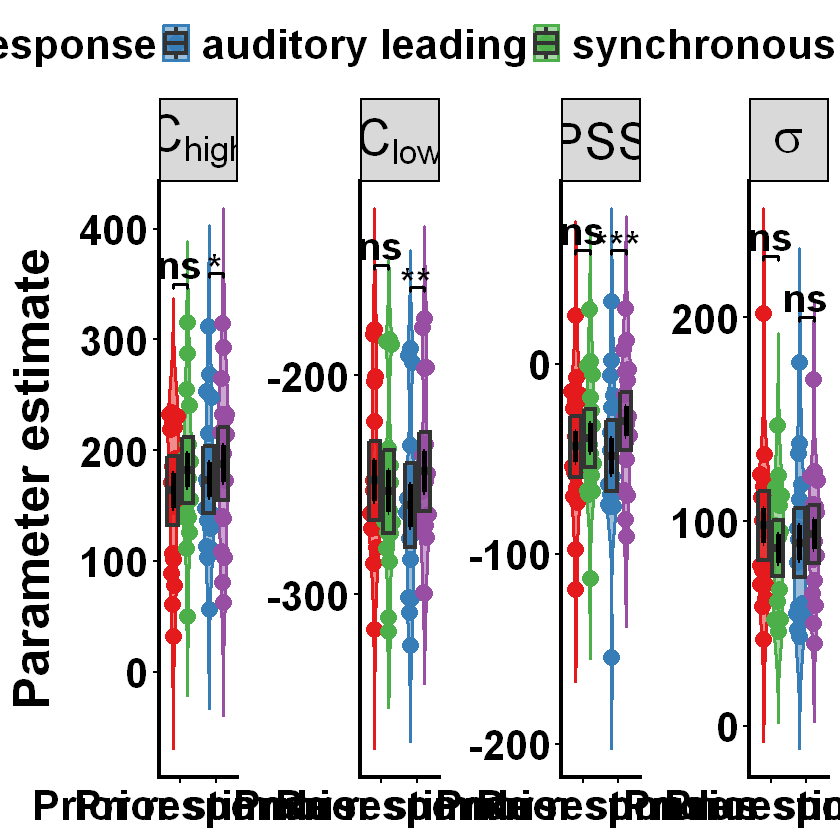

In [150]:
pdf(file="figures/SJ_observer_params1.pdf", width = 30, height = 8)
resfig <- ggplot(data=combined_results, mapping=aes(x=trial_leading, y=value)) +
    # Increased linewidth to 1 and alpha to 0.5 for a bolder, more vivid violin look
    geom_violin(trim = FALSE, alpha=.5, width=.6, scale='width', position=position_dodge(.8), aes(colour=type, fill = type), linewidth=1) +
    # Increased alpha to 1 and stroke to 1.2 so individual points stand out sharply
    geom_quasirandom(dodge.width=.8, aes(colour=type), width=.13, shape=16, stroke=1.2, size=4, alpha=1) +
    # Increased boxplot linewidth to 1.2 for better visibility inside the violin
    geom_boxplot(alpha=.8, data=d, aes(y=c(), ymin=mean-sd*1.96, lower=mean-sd*1.96, middle=mean, upper=mean+sd*1.96, ymax=mean+sd*1.96, fill=type),
                 stat = "identity", position=position_dodge(.8), width=0.6, linewidth = 1.2) +
    # Increased errorbar linewidth to 1.5 to make the SD bounds extra bold
    geom_errorbar(data=d, aes(group=type, fill=c(), y=c(), ymin=mean-sd, ymax=mean+sd), position=position_dodge(.8), width=.1, linewidth=1.5) +
    # Significance bars kept bold with your original size 8.5
    stat_pvalue_manual(stat_test, label = "p.adj.signif", tip.length = 0.01, size = 8.5, bracket.size = 1.1, fontface = "bold") +
    facet_wrap(vars(parameter), scales='free_y', nrow=1, labeller = label_parsed) + 
    labs(x = NULL, y = "Parameter estimate", color = NULL, fill = NULL) + 
    scale_color_brewer(palette = "Set1") +
    scale_fill_brewer(palette = "Set1") +

    # Clean publication theme with enhanced line thickness and your exact custom text sizes
    theme_classic(base_size = 14) +
    theme(
      axis.title.x     = element_text(face = "bold", size = 18, margin = margin(t = 10)),
      axis.title.y     = element_text(face = "bold", size = 30, margin = margin(r = 12)),
      axis.text.x      = element_text(face = "bold", size = 25, color = "black"),
      axis.text.y      = element_text(face = "bold", size = 25, color = "black"),
      strip.text       = element_text(face = "bold", size = 30, color = "black"),
      # Made the facet frame borders bolder (linewidth = 1)
      strip.background = element_rect(fill = "gray85", color = "black", linewidth = 1),
      legend.title     = element_text(face = "bold", size = 25),
      legend.text      = element_text(face = "bold", size = 25),
      legend.position  = "top",
      # Made main axis lines bolder (linewidth = 1.2)
      axis.line        = element_line(linewidth = 1.2),
      panel.spacing    = unit(1.2, "lines")
    )
resfig
dev.off()
resfig